In [2]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

from sklearn.metrics import confusion_matrix
import seaborn as sns

# FLOPP IR

## Data

In [3]:
df_flopp = pd.read_csv('processed_data/df_flopp_new.csv')
del df_flopp['Unnamed: 0'] 

df_flopp.insert(2, "data_source", 'flopp')

df_flopp_e = pd.read_csv('processed_data/df_flopp_e_new.csv')
del df_flopp_e['Unnamed: 0'] 

df_flopp_e.insert(2, "data_source", 'flopp_e')

flopp_flopp_e_pivot_new = pd.concat([df_flopp, df_flopp_e], axis=0).reset_index(drop=True)

flopp_flopp_e_pivot = pd.read_csv('processed_data/flopp_flopp_e_pivot.csv')
del flopp_flopp_e_pivot['Unnamed: 0'] 
flopp_flopp_e_pivot.columns = list(flopp_flopp_e_pivot.columns[:3]) + list(np.float64(flopp_flopp_e_pivot.columns[3:]))


check = flopp_flopp_e_pivot_new.iloc[:,:2].merge(flopp_flopp_e_pivot.iloc[:,:2], on ="file_name", how='left')
check.loc[pd.isna(check['polymer_y']),'polymer_y'] = 'Rubber'
#np.where(~(check['polymer_x'] == check['polymer_y']))[0]
#check.iloc[np.where(~(check['polymer_x'] == check['polymer_y']))[0],:]
flopp_flopp_e_pivot_new.loc[~(check['polymer_x'] == check['polymer_y']),'polymer'] = check.loc[~(check['polymer_x'] == check['polymer_y']),'polymer_y']
flopp_flopp_e_pivot_new.columns = list(flopp_flopp_e_pivot_new.columns[:3]) + list(np.float64(flopp_flopp_e_pivot_new.columns[3:]))


#flopp_flopp_e_pivot_new.iloc[:,3:] = (1-np.log10(flopp_flopp_e_pivot_new.iloc[:,3:]/100))

flopp_flopp_e_pivot_new

#flopp_flopp_e_pivot_new


,file_name,polymer,data_source,674.9918,676.9203,678.8489,680.7775,682.706,684.6345,686.5631,...,3982.452,3984.38,3986.309,3988.237,3990.166,3992.094,3994.023,3995.951,3997.88,3999.809
0,ABS 1. Orange LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,91.82936,91.67874,91.60149,91.38452,91.08202,90.73048,90.19894,...,99.99870,99.98991,100.02670,100.04670,100.04430,100.06880,100.07030,100.03320,100.02030,100.04200
1,ABS 10. Brown LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,87.53708,87.35301,87.08498,86.78752,86.39802,85.75906,84.95250,...,100.32650,100.31270,100.36010,100.39630,100.38240,100.36540,100.36210,100.36500,100.37590,100.37630
2,ABS 11. Black LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,89.22928,89.05251,88.92063,88.62650,88.32430,87.79993,86.99644,...,99.72849,99.69849,99.72910,99.76530,99.78951,99.79996,99.79977,99.76286,99.73790,99.74247
3,ABS 12. White LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,78.51719,78.51464,78.53676,78.48975,78.21510,77.90458,77.44738,...,98.46631,98.44939,98.49831,98.54372,98.53715,98.51609,98.51604,98.50509,98.49593,98.49917
4,ABS 14. White Fridge Lining Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,86.58844,86.49493,86.53345,86.42562,85.99354,85.46368,84.88692,...,97.80650,97.75261,97.77844,97.81771,97.83987,97.84790,97.85225,97.83199,97.81863,97.81449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,PVC 6. Clear Film.CSV,Polyvinyl Chloride,flopp_e,88.20566,87.86478,87.46474,87.46467,87.50079,87.57118,87.60056,...,99.01463,99.03217,99.07008,99.06869,99.02837,99.00091,99.00916,99.03188,99.02618,99.02136
377,PVC 7. Green Film.CSV,Polyvinyl Chloride,flopp_e,92.30173,91.97548,91.63803,91.52959,91.45844,91.44601,91.40334,...,100.00720,100.00700,99.97704,99.96997,99.98112,99.96960,99.95628,99.94707,99.94767,99.95502
378,PVC 8. Grey Fragment.CSV,Polyvinyl Chloride,flopp_e,92.02482,91.88469,91.64758,91.51962,91.50449,91.53230,91.25250,...,99.49762,99.49149,99.52625,99.53676,99.52065,99.51141,99.53561,99.54741,99.53754,99.54282
379,PVC 9. White Fragment.CSV,Polyvinyl Chloride,flopp_e,87.74227,87.57839,87.41970,87.46156,87.44899,87.50304,87.47438,...,98.47853,98.47276,98.48974,98.47692,98.49706,98.53522,98.55120,98.52874,98.46793,98.43912


In [181]:
flopp_flopp_e_pivot_new.to_csv('gloves_contamination/flopp_flopp_e_for_preprocess.csv')

In [4]:
flopp_flopp_e_pivot_new.to_csv('gloves_contamination/flopp_flopp_e_for_preprocess_no_trans.csv')

In [132]:
spectra_data_ir_fp = pd.read_csv('gloves_contamination/data_ir_new_mean_finger_print.csv')
del spectra_data_ir_fp['Unnamed: 0']
spectra_data_ir_fp.columns = list(np.float64(spectra_data_ir_fp.columns[:-4])) + list(spectra_data_ir_fp.columns[-4:])

spectra_data_ir_mean = pd.read_csv('gloves_contamination/data_ir_new_mean_int.csv')
del spectra_data_ir_mean['Unnamed: 0']
spectra_data_ir_mean.columns = list(np.float64(spectra_data_ir_mean.columns[:-4])) + list(spectra_data_ir_mean.columns[-4:])

spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])



In [133]:
def matching(ref_library, spectra_data_ir, limits, lib_name, data_name):
    
    lim1, lim2 = limits

    wn_gl = np.array(spectra_data_ir.columns[:-4])

    idx_gl = list(np.logical_or(np.logical_and(wn_gl > lim1[0], wn_gl < lim1[1]),
                           np.logical_and(wn_gl > lim2[0], wn_gl < lim2[1])
                          ) ) + [False]*4


    wn_fl = np.array(ref_library.columns[3:])

    idx_fl = [False]*3 + list(np.logical_or(np.logical_and(wn_fl > lim1[0], wn_fl < lim1[1]),
                                np.logical_and(wn_fl > lim2[0], wn_fl < lim2[1])
                                ))
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

    x_train_ir = ref_library.iloc[:,idx_fl].to_numpy()
    x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV')
    y_train_ir = ref_library.iloc[:,1]


    x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
    x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV')
    
    pred_ = corr_matching(x_train_ir, y_train_ir, 
                          x_test_ir, r_min=0)
    pred_polymers = pred_[0]
    pred_hqi = pred_[1]
    pred_df = pd.DataFrame(pred_polymers)
    polymer_name = 'polymer_'+lib_name
    hqi_name = 'hqi_'+lib_name
    pred_df.columns = [polymer_name]
    pred_df[hqi_name] = pred_hqi
    pred_df = pred_df.reset_index(drop=True) 
    pred_df['background_'+data_name] = spectra_data_ir['background']
    #matches_mean = pred_df.reset_index().query('@hqi_name>.7').query('background!="background"').groupby(polymer_name).count()[hqi_name]

    #spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
    #spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']

    return pred_df, pred_

In [186]:
flopp_flopp_e_pivot_new

,file_name,polymer,data_source,674.9918,676.9203,678.8489,680.7775,682.706,684.6345,686.5631,...,3982.452,3984.38,3986.309,3988.237,3990.166,3992.094,3994.023,3995.951,3997.88,3999.809
0,ABS 1. Orange LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,1.037018,1.037731,1.038097,1.039127,1.040567,1.042247,1.044799,...,1.000006,1.000044,0.999884,0.999797,0.999808,0.999701,0.999695,0.999856,0.999912,0.999818
1,ABS 10. Brown LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,1.057808,1.058722,1.060057,1.061543,1.063496,1.066720,1.070824,...,0.998584,0.998644,0.998439,0.998282,0.998342,0.998416,0.998430,0.998418,0.998371,0.998369
2,ABS 11. Black LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,1.049493,1.050354,1.050997,1.052436,1.053920,1.056506,1.060499,...,1.001181,1.001311,1.001178,1.001020,1.000915,1.000870,1.000870,1.001031,1.001140,1.001120
3,ABS 12. White LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,1.105035,1.105049,1.104927,1.105187,1.106709,1.108437,1.110993,...,1.006712,1.006787,1.006571,1.006371,1.006400,1.006493,1.006493,1.006541,1.006582,1.006567
4,ABS 14. White Fridge Lining Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,1.062540,1.063009,1.062816,1.063357,1.065534,1.068218,1.071159,...,1.009632,1.009872,1.009757,1.009583,1.009484,1.009448,1.009429,1.009519,1.009578,1.009597
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,PVC 6. Clear Film.CSV,Polyvinyl Chloride,flopp_e,1.054504,1.056185,1.058167,1.058167,1.057988,1.057639,1.057493,...,1.004301,1.004224,1.004057,1.004064,1.004240,1.004361,1.004325,1.004225,1.004250,1.004271
377,PVC 7. Green Film.CSV,Polyvinyl Chloride,flopp_e,1.034790,1.036328,1.037924,1.038438,1.038776,1.038835,1.039038,...,0.999969,0.999970,1.000100,1.000130,1.000082,1.000132,1.000190,1.000230,1.000227,1.000195
378,PVC 8. Grey Fragment.CSV,Polyvinyl Chloride,flopp_e,1.036095,1.036757,1.037879,1.038486,1.038558,1.038426,1.039755,...,1.002187,1.002214,1.002062,1.002016,1.002087,1.002127,1.002022,1.001970,1.002013,1.001990
379,PVC 9. White Fragment.CSV,Polyvinyl Chloride,flopp_e,1.056791,1.057603,1.058391,1.058183,1.058245,1.057977,1.058119,...,1.006658,1.006684,1.006609,1.006666,1.006577,1.006409,1.006338,1.006437,1.006705,1.006832


In [187]:
spectra_data_ir_fp

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2939.6376953125,2941.56689453125,2943.495849609375,2945.4248046875,2947.353759765625,2949.28271484375,map_x,map_y,id,background
0,0.872796,0.796779,-0.611306,-2.278622,-1.746481,-0.370841,0.778302,0.997491,0.094961,-0.064373,...,1.375787,2.917618,3.121620,0.932374,0.674207,-0.859183,15624.450195,1545.449951,MF_L_01_0514_1,background
1,-1.434505,-1.497058,-1.515828,-0.927052,-0.611952,0.703137,0.247949,0.281065,0.596256,1.011994,...,-1.075249,-2.371098,-0.291259,2.515266,3.062379,1.459214,15623.299805,1550.750000,MF_L_01_0514_2,background
2,-0.737597,-0.713237,-0.905982,-0.591487,-0.466991,-0.367976,1.594194,2.186429,0.696239,-0.075104,...,4.507484,3.868423,-1.555192,-2.568281,-1.460040,-1.293480,15617.500000,1564.949951,MF_L_01_0514_3,background
3,-2.124903,-0.445256,1.207637,0.106094,0.010575,0.896289,0.727375,-0.501711,-1.311360,-0.878556,...,1.874117,1.123778,2.563381,3.423367,1.008936,-0.186797,15620.650391,1565.050049,MF_L_01_0514_4,background
4,-0.324747,0.132726,0.309409,1.550920,-0.190660,-0.960115,-0.619112,-0.322470,-0.299099,-0.761152,...,-0.888169,2.748883,3.803817,3.199041,1.382513,3.019189,15616.150391,1570.400024,MF_L_01_0514_5,background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,-0.262721,-0.276170,-0.284734,-0.286635,-0.275587,-0.286407,-0.297969,-0.295624,-0.294374,-0.298505,...,0.906197,0.758653,0.633189,0.545954,0.509604,0.532265,-4543.500000,-1759.750000,KC_N_02_0328_28,no_background
1482,-0.288857,-0.285425,-0.268086,-0.264488,-0.279130,-0.287197,-0.286700,-0.283724,-0.281515,-0.280514,...,2.524593,1.592003,0.858827,0.402423,0.209320,0.153394,-4501.899902,-1758.099976,KC_N_02_0328_29,no_background
1483,-2.289574,-1.723470,-1.599757,-1.588312,-1.486721,-0.954253,-0.713513,-0.372474,-0.098228,0.336216,...,-2.221426,-1.323936,-3.531721,-2.867894,-4.747120,-3.493588,-4510.850098,-1747.099976,KC_N_02_0328_30,background
1484,-0.411749,-0.411490,-0.412306,-0.412452,-0.411963,-0.411440,-0.411809,-0.412027,-0.412110,-0.412255,...,2.259355,1.877813,1.603583,1.474002,1.472530,1.570823,-4511.100098,-1743.050049,KC_N_02_0328_31,no_background


In [113]:
pred_fp_df = matching(flopp_flopp_e_pivot_new, spectra_data_ir_fp, limits=((980,1800),(2720, 2950)), lib_name='flopp', data_name='finger_print')
pred_mean_int_df = matching(flopp_flopp_e_pivot_new, spectra_data_ir_mean, limits=((980,1800),(2720, 2950)), lib_name='flopp', data_name='mean_int')
pred_total_df = matching(flopp_flopp_e_pivot_new, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='flopp', data_name='total_var')

In [65]:
pred_fp_df

,polymer_flopp,hqi_flopp,background_finger_print
0,Polystyrene,0.169966,background
1,Polycarbonate,0.226918,background
2,Polystyrene,0.070586,background
3,Polypropylene,0.199337,background
4,Polyethylene Vinyl Acetate,0.250529,background
...,...,...,...
1481,Polyethylene,0.942226,no_background
1482,Polyethylene,0.775349,no_background
1483,Polyethylene,0.396031,background
1484,Polyethylene,0.894872,no_background


In [138]:
mean_hqi_fp = pd.concat([pred_fp_df.groupby('background_finger_print').count()['polymer_flopp'],
                         pred_fp_df.query('polymer_flopp=="Polyethylene"').groupby('background_finger_print').count()['polymer_flopp'],
                         pred_fp_df.query('polymer_flopp=="Polyethylene"').groupby('background_finger_print').mean(),
                         pred_fp_df.query('polymer_flopp=="Polyethylene"').groupby('background_finger_print').std()],axis=1)
mean_hqi_fp.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_fp['excl_rule'] = 'mean_int_finger_print'#['']
mean_hqi_fp

,n_total,n_only_matches,mean_hqi,std_hqi,excl_rule
background_finger_print,,,,,
background,758,304,0.721547,0.264413,mean_int_finger_print
no_background,728,444,0.825099,0.166070,mean_int_finger_print


In [139]:
mean_hqi_mean = pd.concat([pred_mean_int_df.groupby('background_mean_int').count()['polymer_flopp'],
                           pred_mean_int_df.query('polymer_flopp=="Polyethylene"').groupby('background_mean_int').count()['polymer_flopp'],
                           pred_mean_int_df.query('polymer_flopp=="Polyethylene"').groupby('background_mean_int').mean(),
                         pred_mean_int_df.query('polymer_flopp=="Polyethylene"').groupby('background_mean_int').std()],axis=1)
mean_hqi_mean.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_mean['excl_rule'] = 'mean_int'#['']
mean_hqi_mean


,n_total,n_only_matches,mean_hqi,std_hqi,excl_rule
background_mean_int,,,,,
background,619,163,0.575588,0.268073,mean_int
no_background,867,585,0.840810,0.158803,mean_int


In [140]:
mean_hqi_total = pd.concat([pred_total_df.groupby('background_total_var').count()['polymer_flopp'],
                            pred_total_df.query('polymer_flopp=="Polyethylene"').groupby('background_total_var').count()['polymer_flopp'],
                            pred_total_df.query('polymer_flopp=="Polyethylene"').groupby('background_total_var').mean(),
                         pred_total_df.query('polymer_flopp=="Polyethylene"').groupby('background_total_var').std()],axis=1)
mean_hqi_total.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total['excl_rule'] = 'total_var'
mean_hqi_total

,n_total,n_only_matches,mean_hqi,std_hqi,excl_rule
background_total_var,,,,,
background,254,35,0.229179,0.095723,total_var
no_background,1232,713,0.810201,0.182686,total_var


In [142]:
pd.concat([mean_hqi_fp, mean_hqi_mean, mean_hqi_total], axis=0).to_csv('gloves_contamination/mean_std_hqi_flopp.csv')


In [141]:
pd.concat([mean_hqi_fp, mean_hqi_mean, mean_hqi_total], axis=0).groupby('excl_rule').sum('n')

,n_total,n_only_matches,mean_hqi,std_hqi
excl_rule,,,,
mean_int,1486,748,1.416398,0.426876
mean_int_finger_print,1486,748,1.546647,0.430483
total_var,1486,748,1.039379,0.278409


# Rebecca IR

In [119]:
rebecca_data_ir = pd.read_csv('gloves_contamination/data_ir_rebecca_idx.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])
rebecca_data_ir = rebecca_data_ir.iloc[:,[-2,-1,-3]+list(range(rebecca_data_ir.shape[1]-4))]

idx_libr_reb = []
for pol in ['PE', 'PP', 'PSL']:
    idx_reb = pd.read_excel('gloves_contamination/MEC_04_017_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=pol)
    idx_reb = idx_reb.iloc[:-1,:]
    idx_libr_reb = idx_libr_reb + [pol+'_'+str(int(x)) for x in idx_reb['ID']]
    
rebecca_data_ir = rebecca_data_ir.loc[[x in idx_libr_reb for x in rebecca_data_ir['id']],:]
rebecca_data_ir

,id,polymer,map_y,948.9097900390625,950.8388061523438,952.767822265625,954.69677734375,956.6257934570312,958.5548095703125,960.4838256835938,...,2984.0048828125,2985.933837890625,2987.86279296875,2989.791748046875,2991.720703125,2993.64990234375,2995.578857421875,2997.5078125,2999.436767578125,3001.36572265625
127,PSL_1,PSL,0,-7.056258,-0.898900,-1.054693,1.247319,4.000384,1.476333,-0.814513,...,-3.430876,-4.024211,0.163280,2.034931,1.222586,5.827278,6.598411,0.476916,0.253867,-4.552416
128,PSL_2,PSL,0,1.397564,-2.019503,-7.169917,-3.760889,-1.550604,-0.163867,-0.996640,...,-2.580987,-4.073760,-2.433055,-4.912431,-2.338469,-1.421752,-4.412337,-5.002874,-1.320303,-4.351211
129,PSL_3,PSL,0,-5.593897,-6.567244,-3.703439,-3.115316,-3.842192,-2.440678,-2.345335,...,0.073889,-0.706320,-3.311346,-5.779844,-6.047543,-8.825969,-5.394586,-2.865774,4.630945,4.370772
130,PSL_4,PSL,0,-0.806438,-1.172160,-1.399561,-2.647534,-3.076305,-1.002320,-1.056947,...,3.208759,0.876663,-2.937733,-3.352232,-1.816757,-5.842503,-5.758707,-2.605827,-6.128135,-9.933145
131,PSL_5,PSL,0,2.508037,0.454289,-4.157435,-4.949165,-2.626234,-2.478443,0.023402,...,-3.169762,-2.117142,1.331473,-3.517704,-5.462035,-1.232834,-4.485771,-2.271235,-7.674783,2.835400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,PP_91,PP,0,-5.501368,-0.731867,-0.177870,1.631273,1.277006,-0.030214,-1.289151,...,1.842598,-2.932383,-5.631901,-6.726546,-7.156198,-3.977822,-4.158401,-4.595611,-13.014235,-8.531109
521,PP_92,PP,0,-1.505513,-0.951109,-1.146239,-0.818072,-0.425984,-0.550227,-0.906025,...,-1.053415,-0.620651,-0.053222,-2.035541,-2.834967,-2.177698,-1.911629,-3.101400,-3.542112,-2.078771
522,PP_93,PP,0,-1.193376,-0.839387,-0.916520,-0.691928,-0.512431,-0.134070,-0.026930,...,-0.639061,-0.677715,-0.776359,-0.275816,-0.848965,-1.251804,-1.878466,-2.252761,-2.282949,-2.407313
523,PP_94,PP,0,-4.960909,-3.982604,-1.582585,-1.550157,-2.910924,-2.709201,-2.636106,...,-0.876704,-4.353799,-2.211868,-0.561427,-3.150743,-3.617692,-1.793774,0.045828,-0.385556,-5.184566


In [120]:
pred_fp_df_reb = matching(rebecca_data_ir, spectra_data_ir_fp, limits=((980,1800),(2720, 2950)), lib_name='rebecca_ir', data_name='finger_print')
pred_mean_int_df_reb = matching(rebecca_data_ir, spectra_data_ir_mean, limits=((980,1800),(2720, 2950)), lib_name='rebecca_ir', data_name='mean_int')
pred_total_df_reb = matching(rebecca_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='rebecca_ir', data_name='total_var')


In [144]:
mean_hqi_fp_reb = pd.concat([pred_fp_df_reb.groupby('background_finger_print').count()['polymer_rebecca_ir'],
                             pred_fp_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_finger_print').count()['polymer_rebecca_ir'],
                             pred_fp_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_finger_print').mean(),
                             pred_fp_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_finger_print').std()],axis=1)
mean_hqi_fp_reb.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_fp_reb['excl_rule'] = 'mean_int_finger_print'#['']
mean_hqi_fp_reb


,n_total,n_only_matches,mean_hqi,std_hqi,excl_rule
background_finger_print,,,,,
background,758,351,0.775909,0.238596,mean_int_finger_print
no_background,728,301,0.937225,0.108361,mean_int_finger_print


In [146]:
mean_hqi_mean_reb = pd.concat([pred_mean_int_df_reb.groupby('background_mean_int').count()['polymer_rebecca_ir'],
                               pred_mean_int_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_mean_int').count()['polymer_rebecca_ir'],
                               pred_mean_int_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_mean_int').mean(),
                         pred_mean_int_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_mean_int').std()],axis=1)
mean_hqi_mean_reb.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_mean_reb['excl_rule'] = 'mean_int'#['']
mean_hqi_mean_reb

,n_total,n_only_matches,mean_hqi,std_hqi,excl_rule
background_mean_int,,,,,
background,619,211,0.661727,0.241808,mean_int
no_background,867,441,0.940645,0.098658,mean_int


In [147]:
mean_hqi_total_reb = pd.concat([pred_total_df_reb.groupby('background_total_var').count()['polymer_rebecca_ir'],
                                pred_total_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_total_var').count()['polymer_rebecca_ir'],
                                pred_total_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_total_var').mean(),
                                pred_total_df_reb.query('polymer_rebecca_ir=="PE"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_reb.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_reb['excl_rule'] = 'total_var'
mean_hqi_total_reb

,n_total,n_only_matches,mean_hqi,std_hqi,excl_rule
background_total_var,,,,,
background,254,37,0.297427,0.081136,total_var
no_background,1232,615,0.883649,0.158544,total_var


In [149]:
pd.concat([mean_hqi_fp_reb, mean_hqi_mean_reb, mean_hqi_total_reb], axis=0).to_csv('gloves_contamination/mean_std_hqi_rebecca.csv')


In [148]:
pd.concat([mean_hqi_fp_reb, mean_hqi_mean_reb, mean_hqi_total_reb], axis=0).groupby('excl_rule').sum('n')


,n_total,n_only_matches,mean_hqi,std_hqi
excl_rule,,,,
mean_int,1486,652,1.602372,0.340466
mean_int_finger_print,1486,652,1.713134,0.346958
total_var,1486,652,1.181076,0.239680


# Stearates IR

In [134]:
stearates_data_ir = pd.read_csv('gloves_contamination/stearates_preprocessed_ir.csv')
del stearates_data_ir['Unnamed: 0']
stearates_data_ir.columns = list(np.float64(stearates_data_ir.columns[:-3])) + list(stearates_data_ir.columns[-3:])
#stearates_data_ir['material'] = [x[:str.find(x, '_')] if x[(str.find(x, '_')-1):str.find(x, '_')] != '2' else x[:(str.find(x, '_')-3)] for x in stearates_data_ir['id']]
stearates_data_ir['material'] = [x[:str.find(x, '_')] for x in stearates_data_ir['id']]
stearates_data_ir

#stearates_data_ir.groupby('material').count().iloc[:,-1:]

material_list = ['Magnesium Stearate v2',
                 'Calcium Stearate',  
                 'Sodium Stearate',  
                 'Zinc Stearate']

material_sheets =['Mg (v2)', 'Ca', 'Na', 'Zn']

df_stearates_library_list = []

for mat, sheet in zip(material_list, material_sheets):
    df_stearates_library = pd.read_excel('gloves_contamination/MEC_04_010_StearateLibrary_Compilation.xlsx', sheet_name=sheet)
    df_stearates_library = df_stearates_library.iloc[:-2,:2]#['Number']
    df_stearates_library['id'] = [mat+ '_' + str(x) for x in df_stearates_library['Number']]
    df_stearates_library = df_stearates_library.loc[:,['id', 'PTIR']]
    df_stearates_library.columns = ['id', 'in_library']
    df_stearates_library_list.append(df_stearates_library)
    
df_stearates_library = pd.concat(df_stearates_library_list, axis=0)
df_stearates_library = df_stearates_library.query('in_library == 1').reset_index(drop=True)

stearates_data_ir = stearates_data_ir.merge(df_stearates_library)

stearates_data_ir = stearates_data_ir.iloc[:,[-3,-2,-1]+list(range(stearates_data_ir.shape[1]-5))]
stearates_data_ir

,id,material,in_library,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,...,2951.2119140625,2953.140869140625,2955.06982421875,2956.998779296875,2958.927734375,2960.856689453125,2962.785888671875,2964.71484375,2966.643798828125,2968.57275390625
0,Magnesium Stearate v2_1,Magnesium Stearate v2,1.0,-0.675534,-0.674187,-0.676164,-0.677512,-0.676342,-0.673528,-0.673201,...,0.794043,0.849992,0.870741,0.844799,0.768033,0.642383,0.493054,0.340156,0.193000,0.063008
1,Magnesium Stearate v2_2,Magnesium Stearate v2,1.0,-0.693635,-0.696416,-0.701324,-0.706167,-0.711282,-0.716251,-0.721704,...,0.912760,0.938968,0.971182,1.004702,1.021692,1.007395,0.965420,0.888698,0.784624,0.684637
2,Magnesium Stearate v2_3,Magnesium Stearate v2,1.0,-0.692647,-0.693295,-0.687913,-0.684325,-0.681512,-0.679313,-0.680552,...,0.465926,0.479528,0.478039,0.450841,0.388141,0.301285,0.210615,0.113115,0.000349,-0.111578
3,Magnesium Stearate v2_4,Magnesium Stearate v2,1.0,-0.940120,-0.942183,-0.938993,-0.929239,-0.914637,-0.900830,-0.893118,...,-0.304739,-0.246790,-0.173257,-0.108228,-0.011482,0.022649,-0.085364,-0.159528,-0.184049,-0.214074
4,Magnesium Stearate v2_5,Magnesium Stearate v2,1.0,-0.632855,-0.637773,-0.641436,-0.643244,-0.635807,-0.625978,-0.617085,...,-0.137139,-0.108433,-0.106210,-0.135094,-0.199672,-0.287346,-0.372035,-0.446433,-0.514453,-0.582863
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,Zinc Stearate_107,Zinc Stearate,1.0,-0.598982,-0.601600,-0.608833,-0.607913,-0.598026,-0.597362,-0.591982,...,-0.256498,-0.212438,-0.219671,-0.265847,-0.311385,-0.327372,-0.350094,-0.408934,-0.451611,-0.461317
312,Zinc Stearate_108,Zinc Stearate,1.0,-0.692782,-0.702264,-0.692153,-0.703968,-0.695667,-0.691210,-0.692771,...,-0.083022,0.001096,0.037022,0.054710,0.026293,-0.086340,-0.220806,-0.277223,-0.306242,-0.403612
313,Zinc Stearate_109,Zinc Stearate,1.0,-0.658094,-0.668548,-0.670447,-0.664076,-0.651426,-0.648725,-0.645287,...,0.837930,0.907885,0.912219,0.841964,0.729376,0.589333,0.453168,0.333181,0.190004,0.034273
314,Zinc Stearate_110,Zinc Stearate,1.0,-0.746370,-0.746520,-0.747310,-0.748197,-0.749398,-0.750353,-0.751858,...,1.736097,1.794241,1.843112,1.842068,1.781271,1.679791,1.547962,1.393496,1.223780,1.035223


In [77]:
stearates_data_ir.to_csv('gloves_contamination/stearates_preprocessed_ir_in_library.csv')

In [78]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_min.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [79]:
#pred_fp_df_st = matching(stearates_data_ir, spectra_data_ir_fp, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='finger_print')
#pred_mean_int_df_st = matching(stearates_data_ir, spectra_data_ir_mean, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='mean_int')
#pred_total_df_st = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


## min (0)

In [80]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [81]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '0'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_min_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,706,706,0.308009,0.285716,0,matching using only Calcium Stearate
no_background,780,780,0.760717,0.349585,0,matching using only Calcium Stearate


In [30]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [31]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '0'
mean_hqi_total_st['comment'] = 'matching using all stearates'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_min_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,706,270,0.533396,0.292263,0,matching using all stearates
no_background,780,395,0.960785,0.078965,0,matching using all stearates


## 01

In [119]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_01.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [120]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [121]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '01'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_01_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,591,591,0.241972,0.225483,01,matching using only Calcium Stearate
no_background,895,895,0.746155,0.347926,01,matching using only Calcium Stearate


In [122]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [123]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '01'
mean_hqi_total_st['comment'] = 'matching using all stearates'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_01_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,591,197,0.423532,0.257901,01,matching using all stearates
no_background,895,468,0.940366,0.099879,01,matching using all stearates


## 03

In [114]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_03.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [115]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [116]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '03'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_03_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,487,487,0.197440,0.183643,03,matching using only Calcium Stearate
no_background,999,999,0.715376,0.353176,03,matching using only Calcium Stearate


In [117]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [118]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '03'
mean_hqi_total_st['comment'] = 'matching using all stearates'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_03_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,487,150,0.338646,0.223664,03,matching using all stearates
no_background,999,515,0.917922,0.127029,03,matching using all stearates


## 05

In [109]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_05.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [110]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [111]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '05'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_05_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,351,351,0.161779,0.148152,05,matching using only Calcium Stearate
no_background,1135,1135,0.664343,0.367684,05,matching using only Calcium Stearate


In [112]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [113]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '05'
mean_hqi_total_st['comment'] = 'matching using all stearates'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_05_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,351,100,0.276665,0.181140,05,matching using all stearates
no_background,1135,565,0.877629,0.192019,05,matching using all stearates


## 07

In [104]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_07.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [105]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [106]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '07'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_07_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,333,333,0.156545,0.141300,07,matching using only Calcium Stearate
no_background,1153,1153,0.658009,0.369284,07,matching using only Calcium Stearate


In [107]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [108]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '07'
mean_hqi_total_st['comment'] = 'matching using all stearates'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_07_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,333,93,0.263411,0.171973,07,matching using all stearates
no_background,1153,572,0.872429,0.197789,07,matching using all stearates


## 10

In [140]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_10.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [141]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [142]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '10'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_10_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,270,270,0.133520,0.113709,10,matching using only Calcium Stearate
no_background,1216,1216,0.637141,0.373157,10,matching using only Calcium Stearate


In [143]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [144]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '10'
mean_hqi_total_st['comment'] = 'matching using all stearates'
mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_10_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,270,64,0.207497,0.135991,10,matching using all stearates
no_background,1216,601,0.848997,0.222714,10,matching using all stearates


## 15

In [135]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_15.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [136]:
pred_total_df_st, _ = matching(stearates_data_ir.query('material == "Calcium Stearate"'), spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [137]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '10'
mean_hqi_total_st['comment'] = 'matching using only Calcium Stearate'
#mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_15_stearates_ca.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,203,203,0.127761,0.105858,10,matching using only Calcium Stearate
no_background,1283,1283,0.611752,0.380267,10,matching using only Calcium Stearate


In [138]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [139]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '10'
mean_hqi_total_st['comment'] = 'matching using all stearates'
#mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_15_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,203,47,0.186541,0.121536,10,matching using all stearates
no_background,1283,618,0.832944,0.240875,10,matching using all stearates


## 25

In [150]:
spectra_data_ir_total = pd.read_csv('gloves_contamination/data_ir_new_total_var_25.csv')
del spectra_data_ir_total['Unnamed: 0']
spectra_data_ir_total.columns = list(np.float64(spectra_data_ir_total.columns[:-4])) + list(spectra_data_ir_total.columns[-4:])


In [151]:
pred_total_df_st, _ = matching(stearates_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='stearates_ir', data_name='total_var')


In [153]:
mean_hqi_total_st = pd.concat([pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').mean(),
                               pred_total_df_st.query('polymer_stearates_ir=="Calcium Stearate"').groupby('background_total_var').std()],axis=1)
mean_hqi_total_st.columns = ['n_total','n_only_matches','mean_hqi', 'std_hqi']
mean_hqi_total_st['quantile'] = '10'
mean_hqi_total_st['comment'] = 'matching using all stearates'
#mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_25_stearates_all.csv')
mean_hqi_total_st

,n_total,n_only_matches,mean_hqi,std_hqi,quantile,comment
background_total_var,,,,,,
background,126,29,0.158162,0.082782,10,matching using all stearates
no_background,1360,636,0.815944,0.258817,10,matching using all stearates


In [73]:
mean_hqi_total_st = pd.concat([#pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_st.groupby(['polymer_stearates_ir', 'background_total_var']).count(),
                               pred_total_df_st.groupby(['polymer_stearates_ir', 'background_total_var']).mean(),
                               pred_total_df_st.groupby(['polymer_stearates_ir', 'background_total_var']).std()],axis=1)
mean_hqi_total_st.columns = ['n','mean_hqi', 'std_hqi']
mean_hqi_total_st['excl_rule'] = 'total_var'
#mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_min_stearates.csv')
mean_hqi_total_st

n  mean_hqi   std_hqi  excl_rule
polymer_stearates_ir  background_total_var                                    
Calcium Stearate      background             18  0.152281  0.056396  total_var
                      no_background         647  0.804924  0.270349  total_var
Magnesium Stearate v2 background             21  0.110091  0.063639  total_var
                      no_background         418  0.350450  0.260668  total_var
Sodium Stearate       background             12  0.068826  0.041805  total_var
                      no_background          33  0.246090  0.273250  total_var
Zinc Stearate         background             20  0.096625  0.075870  total_var
                      no_background         317  0.540697  0.393577  total_var

In [74]:
mean_hqi_fp_st = pd.concat([pred_fp_df_st.groupby(['polymer_stearates_ir', 'background_finger_print']).count(),
                            pred_fp_df_st.groupby(['polymer_stearates_ir', 'background_finger_print']).mean(),
                            pred_fp_df_st.groupby(['polymer_stearates_ir', 'background_finger_print']).std()],axis=1)
mean_hqi_fp_st.columns = ['n','mean_hqi', 'std_hqi']
mean_hqi_fp_st['excl_rule'] = 'mean_int_finger_print'#['']
mean_hqi_fp_st


n  mean_hqi   std_hqi  \
polymer_stearates_ir  background_finger_print                            
Calcium Stearate      background               381  0.694809  0.316404   
                      no_background            284  0.911284  0.178936   
Magnesium Stearate v2 background               159  0.223872  0.168889   
                      no_background            280  0.404302  0.279287   
Sodium Stearate       background                31  0.125455  0.136718   
                      no_background             14  0.361269  0.349503   
Zinc Stearate         background               187  0.206859  0.210905   
                      no_background            150  0.897672  0.178997   

                                                           excl_rule  
polymer_stearates_ir  background_finger_print                         
Calcium Stearate      background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Magnesium Stearate v2 background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Sodium Stearate       background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Zinc Stearate         background               mean_int_finger_print  
                      no_background            mean_int_finger_print

In [75]:
mean_hqi_mean_st = pd.concat([pred_mean_int_df_st.groupby(['polymer_stearates_ir', 'background_mean_int']).count(),
                              pred_mean_int_df_st.groupby(['polymer_stearates_ir', 'background_mean_int']).mean(),
                              pred_mean_int_df_st.groupby(['polymer_stearates_ir', 'background_mean_int']).std()],axis=1)
mean_hqi_mean_st.columns = ['n','mean_hqi', 'std_hqi']
mean_hqi_mean_st['excl_rule'] = 'mean_int'#['']
mean_hqi_mean_st

n  mean_hqi   std_hqi excl_rule
polymer_stearates_ir  background_mean_int                                   
Calcium Stearate      background           246  0.555533  0.311719  mean_int
                      no_background        419  0.923307  0.154343  mean_int
Magnesium Stearate v2 background           156  0.201023  0.156437  mean_int
                      no_background        283  0.414984  0.274013  mean_int
Sodium Stearate       background            33  0.141306  0.170090  mean_int
                      no_background         12  0.356981  0.350316  mean_int
Zinc Stearate         background           184  0.193270  0.183240  mean_int
                      no_background        153  0.900469  0.178531  mean_int

In [25]:
final_df = pd.merge(mean_hqi_total_st.reset_index(),
       mean_hqi_total_st.reset_index().groupby(['excl_rule','background_total_var']).sum().iloc[:,:1].reset_index(),
    how='left',
    on=['background_total_var','excl_rule'])

#final_df.columns = ['polymer_stearates_ir','background_total_var','n_total','mean_hqi','std_hqi','excl_rule','n_only_matches']
#final_df= final_df.loc[:, ['excl_rule','polymer_stearates_ir','background_total_var','n_total','n_only_matches','mean_hqi','std_hqi']]
#final_df = final_df.query('polymer_stearates_ir == "Calcium Stearate"')
#final_df.set_index(['excl_rule','polymer_stearates_ir','background_total_var']).to_csv('gloves_contamination/mean_std_hqi_min_stearates.csv')
final_df

,polymer_stearates_ir,background_total_var,n_x,mean_hqi,std_hqi,excl_rule,n_y
0,Calcium Stearate,background,270,0.533396,0.292263,total_var,706
1,Calcium Stearate,no_background,395,0.960785,0.078965,total_var,780
2,Magnesium Stearate v2,background,214,0.226517,0.159437,total_var,706
3,Magnesium Stearate v2,no_background,225,0.445891,0.290302,total_var,780
4,Sodium Stearate,background,36,0.136730,0.136490,total_var,706
5,Sodium Stearate,no_background,9,0.447179,0.409128,total_var,780
6,Zinc Stearate,background,186,0.193473,0.179063,total_var,706
7,Zinc Stearate,no_background,151,0.909587,0.165287,total_var,780


In [76]:
pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0)#.to_csv('gloves_contamination/mean_std_hqi_stearates.csv')


n  mean_hqi   std_hqi  \
polymer_stearates_ir  background_finger_print                            
Calcium Stearate      background               381  0.694809  0.316404   
                      no_background            284  0.911284  0.178936   
Magnesium Stearate v2 background               159  0.223872  0.168889   
                      no_background            280  0.404302  0.279287   
Sodium Stearate       background                31  0.125455  0.136718   
                      no_background             14  0.361269  0.349503   
Zinc Stearate         background               187  0.206859  0.210905   
                      no_background            150  0.897672  0.178997   
Calcium Stearate      background               246  0.555533  0.311719   
                      no_background            419  0.923307  0.154343   
Magnesium Stearate v2 background               156  0.201023  0.156437   
                      no_background            283  0.414984  0.274013   
Sodium Stearate       background                33  0.141306  0.170090   
                      no_background             12  0.356981  0.350316   
Zinc Stearate         background               184  0.193270  0.183240   
                      no_background            153  0.900469  0.178531   
Calcium Stearate      background                18  0.152281  0.056396   
                      no_background            647  0.804924  0.270349   
Magnesium Stearate v2 background                21  0.110091  0.063639   
                      no_background            418  0.350450  0.260668   
Sodium Stearate       background                12  0.068826  0.041805   
                      no_background             33  0.246090  0.273250   
Zinc Stearate         background                20  0.096625  0.075870   
                      no_background            317  0.540697  0.393577   

                                                           excl_rule  
polymer_stearates_ir  background_finger_print                         
Calcium Stearate      background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Magnesium Stearate v2 background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Sodium Stearate       background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Zinc Stearate         background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Calcium Stearate      background                            mean_int  
                      no_background                         mean_int  
Magnesium Stearate v2 background                            mean_int  
                      no_background                         mean_int  
Sodium Stearate       background                            mean_int  
                      no_background                         mean_int  
Zinc Stearate         background                            mean_int  
                      no_background                         mean_int  
Calcium Stearate      background                           total_var  
                      no_background                        total_var  
Magnesium Stearate v2 background                           total_var  
                      no_background                        total_var  
Sodium Stearate       background                           total_var  
                      no_background                        total_var  
Zinc Stearate         background                           total_var  
                      no_background                        total_var

In [77]:
pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0)

n  mean_hqi   std_hqi  \
polymer_stearates_ir  background_finger_print                            
Calcium Stearate      background               381  0.694809  0.316404   
                      no_background            284  0.911284  0.178936   
Magnesium Stearate v2 background               159  0.223872  0.168889   
                      no_background            280  0.404302  0.279287   
Sodium Stearate       background                31  0.125455  0.136718   
                      no_background             14  0.361269  0.349503   
Zinc Stearate         background               187  0.206859  0.210905   
                      no_background            150  0.897672  0.178997   
Calcium Stearate      background               246  0.555533  0.311719   
                      no_background            419  0.923307  0.154343   
Magnesium Stearate v2 background               156  0.201023  0.156437   
                      no_background            283  0.414984  0.274013   
Sodium Stearate       background                33  0.141306  0.170090   
                      no_background             12  0.356981  0.350316   
Zinc Stearate         background               184  0.193270  0.183240   
                      no_background            153  0.900469  0.178531   
Calcium Stearate      background                18  0.152281  0.056396   
                      no_background            647  0.804924  0.270349   
Magnesium Stearate v2 background                21  0.110091  0.063639   
                      no_background            418  0.350450  0.260668   
Sodium Stearate       background                12  0.068826  0.041805   
                      no_background             33  0.246090  0.273250   
Zinc Stearate         background                20  0.096625  0.075870   
                      no_background            317  0.540697  0.393577   

                                                           excl_rule  
polymer_stearates_ir  background_finger_print                         
Calcium Stearate      background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Magnesium Stearate v2 background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Sodium Stearate       background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Zinc Stearate         background               mean_int_finger_print  
                      no_background            mean_int_finger_print  
Calcium Stearate      background                            mean_int  
                      no_background                         mean_int  
Magnesium Stearate v2 background                            mean_int  
                      no_background                         mean_int  
Sodium Stearate       background                            mean_int  
                      no_background                         mean_int  
Zinc Stearate         background                            mean_int  
                      no_background                         mean_int  
Calcium Stearate      background                           total_var  
                      no_background                        total_var  
Magnesium Stearate v2 background                           total_var  
                      no_background                        total_var  
Sodium Stearate       background                           total_var  
                      no_background                        total_var  
Zinc Stearate         background                           total_var  
                      no_background                        total_var

In [15]:
pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0).reset_index().groupby(['excl_rule','background_finger_print']).sum().iloc[:,:1].reset_index()

,excl_rule,background_finger_print,n
0,mean_int,background,619
1,mean_int,no_background,867
2,mean_int_finger_print,background,758
3,mean_int_finger_print,no_background,728
4,total_var,background,706
5,total_var,no_background,780


In [78]:
pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0).reset_index().groupby(['excl_rule','background_finger_print']).sum().iloc[:,:1].reset_index()

,excl_rule,background_finger_print,n
0,mean_int,background,619
1,mean_int,no_background,867
2,mean_int_finger_print,background,758
3,mean_int_finger_print,no_background,728
4,total_var,background,71
5,total_var,no_background,1415


In [16]:
final_df = pd.merge(pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0).reset_index(),
       pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0).reset_index().groupby(['excl_rule','background_finger_print']).sum().iloc[:,:1].reset_index(),
    how='left',
    on=['background_finger_print','excl_rule'])
final_df.columns = ['polymer_stearates_ir','background_finger_print','n_total','mean_hqi','std_hqi','excl_rule','n_only_matches']
final_df= final_df.loc[:, ['excl_rule','polymer_stearates_ir','background_finger_print','n_total','n_only_matches','mean_hqi','std_hqi']]
final_df.set_index(['excl_rule','polymer_stearates_ir','background_finger_print'])#.to_csv('gloves_contamination/mean_std_hqi_stearates.csv')
#pd.merge()

n_total  \
excl_rule             polymer_stearates_ir  background_finger_print            
mean_int_finger_print Calcium Stearate      background                   381   
                                            no_background                284   
                      Magnesium Stearate v2 background                   159   
                                            no_background                280   
                      Sodium Stearate       background                    31   
                                            no_background                 14   
                      Zinc Stearate         background                   187   
                                            no_background                150   
mean_int              Calcium Stearate      background                   246   
                                            no_background                419   
                      Magnesium Stearate v2 background                   156   
                                            no_background                283   
                      Sodium Stearate       background                    33   
                                            no_background                 12   
                      Zinc Stearate         background                   184   
                                            no_background                153   
total_var             Calcium Stearate      background                   270   
                                            no_background                395   
                      Magnesium Stearate v2 background                   214   
                                            no_background                225   
                      Sodium Stearate       background                    36   
                                            no_background                  9   
                      Zinc Stearate         background                   186   
                                            no_background                151   

                                                                     n_only_matches  \
excl_rule             polymer_stearates_ir  background_finger_print                   
mean_int_finger_print Calcium Stearate      background                          758   
                                            no_background                       728   
                      Magnesium Stearate v2 background                          758   
                                            no_background                       728   
                      Sodium Stearate       background                          758   
                                            no_background                       728   
                      Zinc Stearate         background                          758   
                                            no_background                       728   
mean_int              Calcium Stearate      background                          619   
                                            no_background                       867   
                      Magnesium Stearate v2 background                          619   
                                            no_background                       867   
                      Sodium Stearate       background                          619   
                                            no_background                       867   
                      Zinc Stearate         background                          619   
                                            no_background                       867   
total_var             Calcium Stearate      background                          706   
                                            no_background                       780   
                      Magnesium Stearate v2 background                          706   
                                            no_background                       780   
                      Sodium Stearate       background                    

In [79]:
final_df = pd.merge(pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0).reset_index(),
       pd.concat([mean_hqi_fp_st, mean_hqi_mean_st, mean_hqi_total_st], axis=0).reset_index().groupby(['excl_rule','background_finger_print']).sum().iloc[:,:1].reset_index(),
    how='left',
    on=['background_finger_print','excl_rule'])
final_df.columns = ['polymer_stearates_ir','background_finger_print','n_total','mean_hqi','std_hqi','excl_rule','n_only_matches']
final_df= final_df.loc[:, ['excl_rule','polymer_stearates_ir','background_finger_print','n_total','n_only_matches','mean_hqi','std_hqi']]
final_df.set_index(['excl_rule','polymer_stearates_ir','background_finger_print'])#.to_csv('gloves_contamination/mean_std_hqi_stearates.csv')
#pd.merge()

n_total  \
excl_rule             polymer_stearates_ir  background_finger_print            
mean_int_finger_print Calcium Stearate      background                   381   
                                            no_background                284   
                      Magnesium Stearate v2 background                   159   
                                            no_background                280   
                      Sodium Stearate       background                    31   
                                            no_background                 14   
                      Zinc Stearate         background                   187   
                                            no_background                150   
mean_int              Calcium Stearate      background                   246   
                                            no_background                419   
                      Magnesium Stearate v2 background                   156   
                                            no_background                283   
                      Sodium Stearate       background                    33   
                                            no_background                 12   
                      Zinc Stearate         background                   184   
                                            no_background                153   
total_var             Calcium Stearate      background                    18   
                                            no_background                647   
                      Magnesium Stearate v2 background                    21   
                                            no_background                418   
                      Sodium Stearate       background                    12   
                                            no_background                 33   
                      Zinc Stearate         background                    20   
                                            no_background                317   

                                                                     n_only_matches  \
excl_rule             polymer_stearates_ir  background_finger_print                   
mean_int_finger_print Calcium Stearate      background                          758   
                                            no_background                       728   
                      Magnesium Stearate v2 background                          758   
                                            no_background                       728   
                      Sodium Stearate       background                          758   
                                            no_background                       728   
                      Zinc Stearate         background                          758   
                                            no_background                       728   
mean_int              Calcium Stearate      background                          619   
                                            no_background                       867   
                      Magnesium Stearate v2 background                          619   
                                            no_background                       867   
                      Sodium Stearate       background                          619   
                                            no_background                       867   
                      Zinc Stearate         background                          619   
                                            no_background                       867   
total_var             Calcium Stearate      background                           71   
                                            no_background                      1415   
                      Magnesium Stearate v2 background                           71   
                                            no_background                      1415   
                      Sodium Stearate       background                    

In [162]:
x_train_ir.shape, x_test_ir.shape

((381, 544), (1486, 544))

In [13]:
np.mean(spectra_data_ir['background'] == 'background')

0.5100942126514132

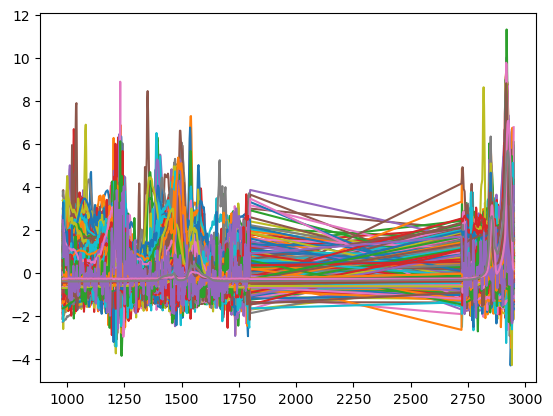

In [14]:
_ = plt.plot(spectra_data_ir.query('background != "background"').loc[:,idx_gl].T)

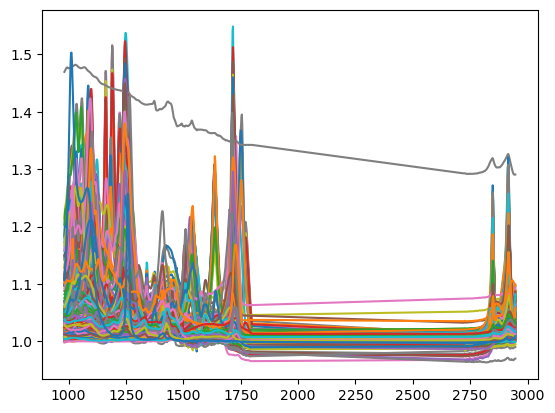

In [15]:
_ = plt.plot(flopp_flopp_e_pivot_new.loc[:,idx_fl].T)

## Matching

# Mean int

In [163]:
pred_ = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers)
pred_df.columns = ['polymer_flopp']
pred_df['hqi_flopp'] = pred_hqi
pred_df = pred_df.reset_index(drop=True) 
pred_df['background_mean'] = spectra_data_ir['background']
matches_mean = pred_df.reset_index().query('hqi_flopp>.7').query('background_mean!="background"').groupby('polymer_flopp').count()['hqi_flopp']
#matches_mean = matches_mean / matches_mean.sum()

matches_bg_mean = pred_df.reset_index().query('hqi_flopp>.7').query('background_mean=="background"').groupby('polymer_flopp').count()['hqi_flopp']
#matches_bg_mean = matches_bg_mean / matches_bg_mean.sum()
matches_bg_mean


polymer_flopp
Polyethylene    199
Rubber           44
Name: hqi_flopp, dtype: int64

In [169]:
pred_df.query('polymer_flopp=="Polyethylene"').groupby('background_mean').mean()

,hqi_flopp
background_mean,
background,0.721547
no_background,0.825099


In [170]:
pred_df.query('polymer_flopp=="Polyethylene"').groupby('background_mean').std()

,hqi_flopp
background_mean,
background,0.264413
no_background,0.166070


In [104]:
spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']
#spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']

In [109]:
spectra_data_ir.query('background != "background" and polymer_flopp == "Polyethylene" and hqi_flopp > .7')

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2943.495849609375,2945.4248046875,2947.353759765625,2949.28271484375,map_x,map_y,id,background,polymer_flopp,hqi_flopp
210,-0.447722,-0.402410,-0.404672,-0.401270,-0.418026,-0.444411,-0.455482,-0.442944,-0.430878,-0.419940,...,1.816618,1.700725,1.615969,1.620261,16144.000000,5119.899902,KC_L_02_0425_10,no_background,Polyethylene,0.929840
217,-0.380225,-0.379462,-0.378739,-0.379132,-0.379298,-0.379070,-0.379127,-0.379798,-0.379598,-0.379581,...,1.580707,1.406933,1.304605,1.264954,15998.950195,5168.500000,KC_L_02_0425_17,no_background,Polyethylene,0.900127
220,0.097941,-0.174424,-0.278410,0.042787,0.082671,-0.009771,-0.141479,-0.452110,-0.605869,-0.397850,...,0.900266,1.395258,1.104588,0.454525,15979.000000,5179.750000,KC_L_02_0425_20,no_background,Polyethylene,0.940811
222,-0.364618,-0.363374,-0.362846,-0.355976,-0.357187,-0.360998,-0.362912,-0.356795,-0.350137,-0.353982,...,1.002393,0.913730,0.883572,0.892159,15974.799805,5194.000000,KC_L_02_0425_22,no_background,Polyethylene,0.955547
224,0.011665,0.436095,1.270280,0.654591,0.338395,0.046708,0.078750,0.282319,0.099222,0.020333,...,1.225459,1.927126,3.522187,2.417761,16004.150391,5296.200195,KC_L_02_0425_24,no_background,Polyethylene,0.773243
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1478,-0.447442,-0.447799,-0.449295,-0.449823,-0.446639,-0.445425,-0.445670,-0.445512,-0.446346,-0.445951,...,1.392680,1.051106,0.805281,0.669040,-4531.649902,-1766.150024,KC_N_02_0328_25,no_background,Polyethylene,0.815404
1479,-0.463342,-0.463195,-0.463946,-0.465754,-0.465648,-0.464834,-0.464019,-0.463689,-0.463777,-0.464120,...,1.144432,0.969529,0.855940,0.820492,-4553.850098,-1765.500000,KC_N_02_0328_26,no_background,Polyethylene,0.929281
1481,-0.262721,-0.276170,-0.284734,-0.286635,-0.275587,-0.286407,-0.297969,-0.295624,-0.294374,-0.298505,...,0.633189,0.545954,0.509604,0.532265,-4543.500000,-1759.750000,KC_N_02_0328_28,no_background,Polyethylene,0.942226
1482,-0.288857,-0.285425,-0.268086,-0.264488,-0.279130,-0.287197,-0.286700,-0.283724,-0.281515,-0.280514,...,0.858827,0.402423,0.209320,0.153394,-4501.899902,-1758.099976,KC_N_02_0328_29,no_background,Polyethylene,0.775349


In [108]:
std_PE.shape, mean_PE.shape, wn_gl[idx_gl[:-4]].shape

((544,), (544,), (544,))

(340, 544)


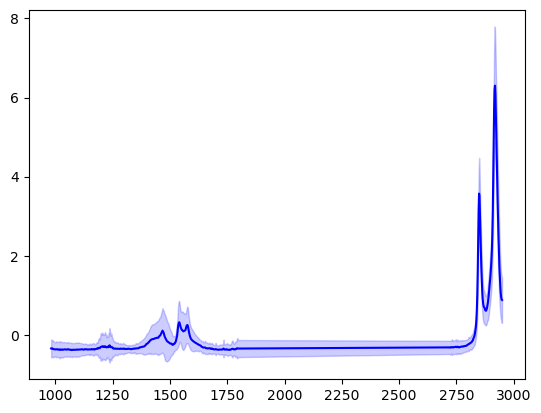

In [113]:
df_PE = spectra_data_ir.query('background != "background" and polymer_flopp == "Polyethylene" and hqi_flopp > .7').loc[:,idx_gl+[False]*2]
mean_PE = np.array(df_PE.mean(0))
std_PE = np.array(df_PE.std(0))

mean_PE = np.float64(mean_PE)
std_PE = np.float64(std_PE)
wn_gl = np.float64(wn_gl)
print(df_PE.shape)

_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE, c='b')

#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE+std_PE)
#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE-std_PE)
    
_ = plt.fill_between(wn_gl[idx_gl[:-4]], mean_PE - std_PE, mean_PE + std_PE, color='b', alpha=.2)


(199, 544)


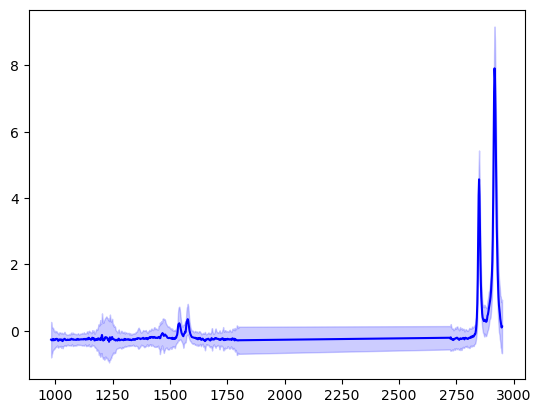

In [114]:
df_PE = spectra_data_ir.query('background == "background" and polymer_flopp == "Polyethylene" and hqi_flopp > .7').loc[:,idx_gl+[False]*2]
mean_PE = np.array(df_PE.mean(0))
std_PE = np.array(df_PE.std(0))

mean_PE = np.float64(mean_PE)
std_PE = np.float64(std_PE)
wn_gl = np.float64(wn_gl)
print(df_PE.shape)

_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE, c='b')

#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE+std_PE)
#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE-std_PE)
    
_ = plt.fill_between(wn_gl[idx_gl[:-4]], mean_PE - std_PE, mean_PE + std_PE, color='b', alpha=.2)


In [289]:
#pred_df['background_mean'] = spectra_data_ir['background']
#pred_df['background_mean_finger_print'] = spectra_data_ir['background']
#pred_df['background_total_var'] = spectra_data_ir['background']

In [310]:
pred_ = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
#pred_df = 


Int64Index([361, 315, 130, 116, 287,  18,  74, 369, 287, 296,
            ...
            257, 331, 254, 254, 155,  67, 228, 220, 345, 261],
           dtype='int64', length=1486)

In [314]:
pred_df.to_csv('gloves_contamination/table_matches_exlusion_rule.csv')

In [281]:
np.mean(spectra_data_ir['background'] == 'background')

0.4165545087483176

In [282]:
pred_df.reset_index().query('hqi_flopp>.7').query('background_mean=="background"').shape[0] / pred_df.query('background_mean=="background"').shape[0]


0.16478190630048464

In [283]:
pred_df.reset_index().query('hqi_flopp>.7').query('background_mean!="background"').shape[0] / pred_df.query('background_mean!="background"').shape[0]


0.6828143021914648

In [284]:
pred_df.reset_index().query('hqi_flopp>.7').shape[0] / pred_df.shape[0]

0.4670255720053836

In [285]:
mean_prop = pd.DataFrame({'exc_rule':['mean'], 
              'prop_excluded':[0.4165], 
              'prop_excluded_match':[0.16478], 
              'prop_included_match':[0.6828], 
              'overall_match':[0.4670]})

In [65]:
pred_df.reset_index().query('hqi_flopp>.7').shape[0] / pred_df.shape[0]

0.6626898047722343


# Total Var

In [425]:
pred_ = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers)
pred_df.columns = ['polymer_flopp']
pred_df['hqi_flopp'] = pred_hqi
pred_df = pred_df.reset_index(drop=True) 
pred_df['background_total_var'] = spectra_data_ir['background']
matches_total_var = pred_df.query('hqi_flopp>.7').query('background_total_var!="background"').groupby('polymer_flopp').count()['hqi_flopp']
matches_total_var = matches_total_var / matches_total_var.sum()

matches_bg_total_var = pred_df.reset_index().query('hqi_flopp>.7').query('background_total_var=="background"').groupby('polymer_flopp').count()['hqi_flopp']
matches_bg_total_var = matches_bg_total_var / matches_bg_total_var.sum()
matches_bg_total_var

Series([], Name: hqi_flopp, dtype: float64)

In [445]:
pred_df#.query('hqi_flopp >.7').shape[0]

,polymer_flopp,hqi_flopp,background_total_var
0,Polystyrene,0.232908,no_background
1,Polypropylene,0.171990,no_background
2,Polystyrene,0.063929,background
3,Polypropylene,0.251303,background
4,Polypropylene,0.224501,background
...,...,...,...
1481,Polyethylene,0.939378,no_background
1482,Polyethylene,0.774900,no_background
1483,Polyethylene,0.384105,no_background
1484,Polypropylene,0.890937,no_background


In [426]:
np.mean(spectra_data_ir['background'] == 'background')

0.17092866756393002

In [427]:
pred_df.reset_index().query('hqi_flopp>.7').query('background_total_var=="background"').shape[0] / pred_df.query('background_total_var=="background"').shape[0]


0.0

In [428]:
pred_df.reset_index().query('hqi_flopp>.7').query('background_total_var!="background"').shape[0] / pred_df.query('background_total_var!="background"').shape[0]


0.5633116883116883

In [256]:
pred_df.reset_index().query('hqi_flopp>.7').shape[0] / pred_df.shape[0]

0.4670255720053836

In [257]:
tot_prop = pd.DataFrame({'exc_rule':['total_var'], 
 'prop_excluded':[0.1709], 
 'prop_excluded_match':[0], 
 'prop_included_match':[0.5633], 
 'overall_match':[0.4670]})


# Mean Finger Print

In [268]:
pred_ = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers)
pred_df.columns = ['polymer_flopp']
pred_df['hqi_flopp'] = pred_hqi
pred_df = pred_df.reset_index(drop=True) 
pred_df['background_mean_finger_print'] = spectra_data_ir['background']
matches_mean_fing = pred_df.reset_index().query('hqi_flopp>.7').query('background_mean_finger_print!="background"').groupby('polymer_flopp').count()['hqi_flopp']
matches_mean_fing = matches_mean_fing / matches_mean_fing.sum()

matches_bg_mean_fing = pred_df.reset_index().query('hqi_flopp>.7').query('background_mean_finger_print=="background"').groupby('polymer_flopp').count()['hqi_flopp']
matches_bg_mean_fing = matches_bg_mean_fing / matches_bg_mean_fing.sum()
matches_bg_mean_fing

polymer_flopp
Polyethylene     0.876596
Polypropylene    0.012766
Rubber           0.110638
Name: hqi_flopp, dtype: float64

In [278]:
pred_df#.loc[:,['background_total_var']].reset_index()['index']#.sort_values('index')#.to_csv('gloves_contamination/table_matches_exlusion_rule.csv')

,polymer_flopp,hqi_flopp,background_mean
0,Polystyrene,0.232908,background
1,Polypropylene,0.171990,background
2,Polystyrene,0.063929,background
3,Polypropylene,0.251303,background
4,Polypropylene,0.224501,background
...,...,...,...
1481,Polyethylene,0.939378,no_background
1482,Polyethylene,0.774900,no_background
1483,Polyethylene,0.384105,background
1484,Polypropylene,0.890937,no_background


In [151]:
#pred_df['background_mean'] = spectra_data_ir['background']
#pred_df['background_mean_finger_print'] = spectra_data_ir['background']
#pred_df['background_total_var'] = spectra_data_ir['background']

In [260]:
np.mean(spectra_data_ir['background'] == 'background')

0.5100942126514132

In [261]:
pred_df.reset_index().query('hqi_flopp>.7').query('background_mean_finger_print=="background"').shape[0] / pred_df.query('background_mean_finger_print=="background"').shape[0]


0.3100263852242744

In [262]:
pred_df.reset_index().query('hqi_flopp>.7').query('background_mean_finger_print!="background"').shape[0] / pred_df.query('background_mean_finger_print!="background"').shape[0]


0.6304945054945055

In [263]:
pred_df.reset_index().query('hqi_flopp>.7').shape[0] / pred_df.shape[0]


0.4670255720053836

In [275]:
mean_fp_prop = pd.DataFrame({'exc_rule':['finger print'], 
 'prop_excluded':[0.5100], 
 'prop_excluded_match':[0.3100], 
 'prop_included_match':[0.6304], 
 'overall_match':[0.4670]})

In [276]:
pd.concat([mean_prop, mean_fp_prop, tot_prop]).set_index('exc_rule')*100

,prop_excluded,prop_excluded_match,prop_included_match,overall_match
exc_rule,,,,
mean,41.65,16.478,68.28,46.7
finger print,51.00,31.000,63.04,46.7
total_var,17.09,0.000,56.33,46.7


In [267]:
match_table_exc_rule = pd.concat([matches_mean *100,
           matches_mean_fing * 100,
          matches_total_var*100], axis=1)
match_table_exc_rule.columns = ['mean','mean_finger_print','total_var']
match_table_exc_rule

,mean,mean_finger_print,total_var
polymer_flopp,,,
Cellulose Acetate,0.168919,0.217865,0.144092
Cotton,0.675676,0.871460,0.576369
Polycarbonate,2.533784,3.485839,2.305476
Polyethylene,70.777027,63.834423,71.902017
Polymethyl Methacrylate,0.337838,0.435730,0.288184
Polypropylene,15.709459,19.825708,13.544669
Polystyrene,0.844595,1.089325,0.720461
Polyurethane,1.182432,1.525054,1.008646
Polyvinyl Chloride,0.337838,0.653595,0.432277


In [274]:
match_table_exc_rule = pd.concat([matches_bg_mean *100,
           matches_bg_mean_fing * 100,
          matches_bg_total_var*100], axis=1)
match_table_exc_rule.columns = ['mean','mean_finger_print','total_var']
match_table_exc_rule

,mean,mean_finger_print,total_var
polymer_flopp,,,
Polycarbonate,0.980392,NaN,NaN
Polyethylene,78.431373,87.659574,NaN
Polypropylene,0.980392,1.276596,NaN
Polyvinyl Chloride,0.980392,NaN,NaN
Rubber,18.627451,11.063830,NaN


(array([ 60., 179., 155.,  95.,  76.,  96., 110.,  90., 166., 459.]),
 array([0.00546169, 0.10217521, 0.19888873, 0.29560225, 0.39231578,
        0.4890293 , 0.58574282, 0.68245634, 0.77916986, 0.87588338,
        0.9725969 ]),
 <BarContainer object of 10 artists>)

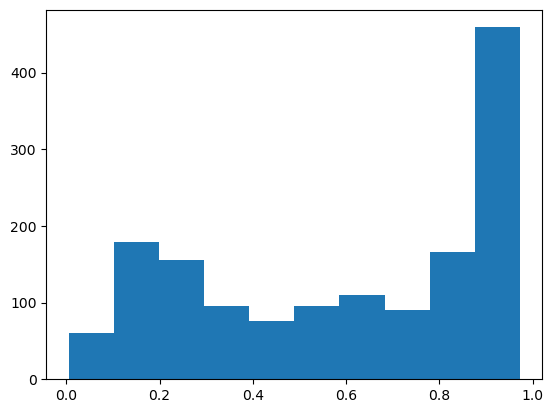

In [430]:
plt.hist(pred_df['hqi_flopp'])

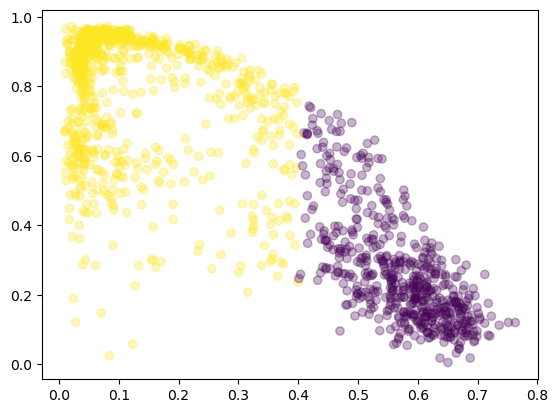

In [431]:
abs_var = np.abs(np.diff(x_test_ir,1)).mean(1) 
plt.scatter(abs_var, pred_hqi, c=abs_var < .4, alpha=.3)

In [31]:
pred_polymers

255          Polyethylene
251          Polyethylene
200     Cellulose Acetate
138          Polyurethane
198                Cotton
              ...        
254          Polyethylene
155    Polyvinyl Chloride
67           Polyethylene
228          Polyethylene
345         Polypropylene
Name: polymer, Length: 867, dtype: object

In [291]:
particles_data = pd.read_csv('gloves_contamination/spectra_matches.csv')
del particles_data['Unnamed: 0']
particles_data = particles_data.loc[:,['id_x', 'size', 'area', 'perimeter', 'circularity']]

In [298]:
spectra_data_ir_particle = spectra_data_ir.loc[:,['map_x', 'map_y', 'id']].merge(particles_data, how='left', left_on='id',right_on='id_x')
spectra_data_ir_particle['hqi_flopp'] = np.array(pred_df['hqi_flopp'])
spectra_data_ir_particle['background'] = spectra_data_ir['background']
spectra_data_ir_particle

,map_x,map_y,id,id_x,size,area,perimeter,circularity,hqi_flopp,background
0,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01_0514_1,1.374926,1.330287,5.386343,0.575968,0.232908,background
1,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01_0514_2,3.169136,6.776416,11.286760,0.668194,0.171990,background
2,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01_0514_3,1.793934,2.482638,6.046356,0.853035,0.063929,background
3,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01_0514_4,0.936898,0.696918,3.310439,0.798824,0.251303,background
4,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01_0514_5,1.615575,2.111937,5.716350,0.811866,0.224501,background
...,...,...,...,...,...,...,...,...,...,...
1481,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02_0328_28,1.796098,2.247508,8.490387,0.391640,0.939378,no_background
1482,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02_0328_29,1.743342,2.414853,6.154179,0.800924,0.774900,no_background
1483,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02_0328_30,0.515590,0.211829,1.831388,0.793352,0.384105,background
1484,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02_0328_31,1.621519,2.048388,5.662438,0.802502,0.890937,no_background


In [300]:
np.mean(spectra_data_ir_particle.query('background != "background"')['hqi_flopp'] > .7)

0.6304945054945055

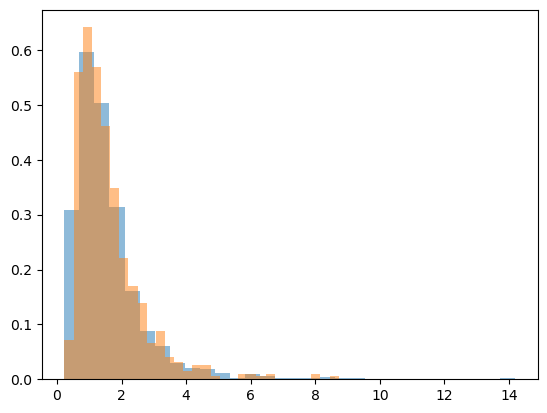

In [302]:
_ = plt.hist(spectra_data_ir_particle['size'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_flopp > .7')['size'], bins=30, density=True, alpha=.5)

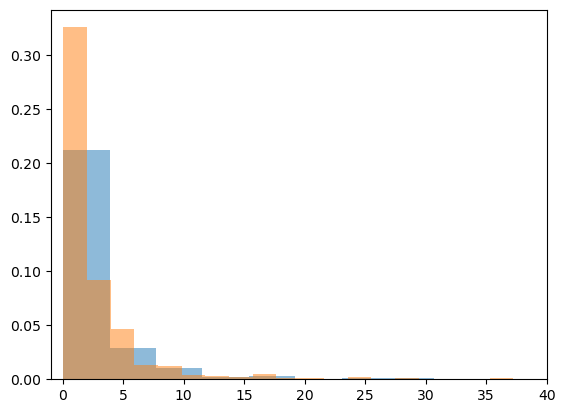

In [37]:
_ = plt.hist(spectra_data_ir_particle['area'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_flopp > .7')['area'], bins=30, density=True, alpha=.5)
_ = plt.xlim((-1,40))

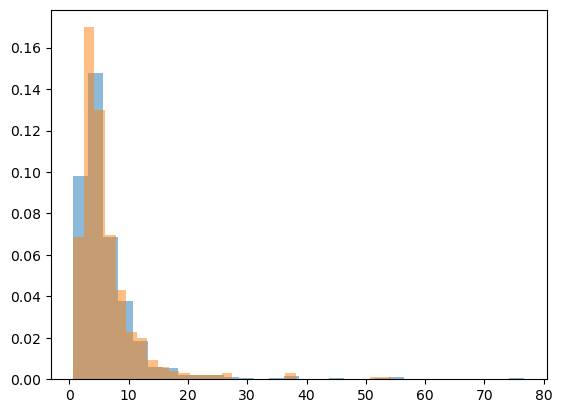

In [38]:
_ = plt.hist(spectra_data_ir_particle['perimeter'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_flopp > .7')['perimeter'], bins=30, density=True, alpha=.5)
#_ = plt.xlim((-1,40))

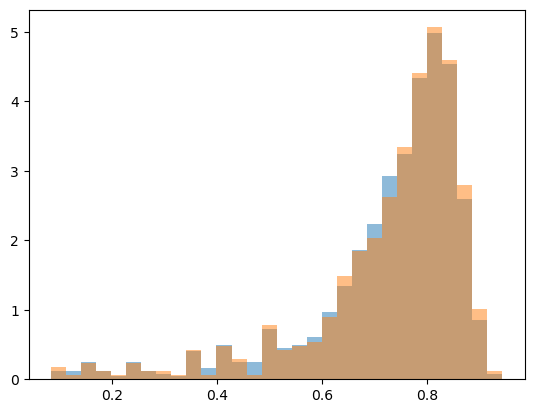

In [39]:
_ = plt.hist(spectra_data_ir_particle['circularity'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_flopp > .7')['circularity'], bins=30, density=True, alpha=.5)
#_ = plt.xlim((-1,40))

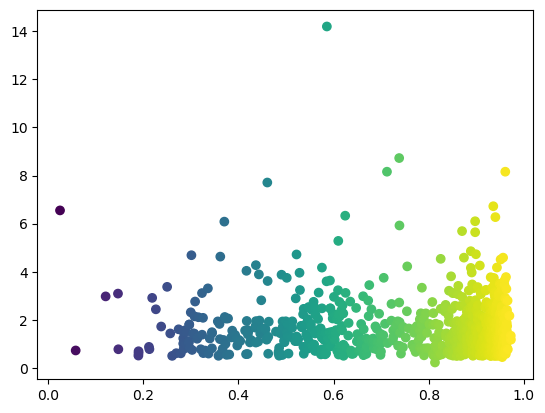

In [40]:
plt.scatter(spectra_data_ir_particle.loc[:,['size','hqi_flopp']].sort_values('hqi_flopp')['hqi_flopp'],
            spectra_data_ir_particle.loc[:,['size','hqi_flopp']].sort_values('hqi_flopp')['size'], 
            c=spectra_data_ir_particle.loc[:,['size','hqi_flopp']].sort_values('hqi_flopp')['hqi_flopp'])

# SLOPP Raman

In [407]:
slopp_slopp_e_pivot = pd.read_csv('processed_data/slopp_slopp_e_pivot.csv')
del slopp_slopp_e_pivot['Unnamed: 0'] 
slopp_slopp_e_pivot.columns = list(slopp_slopp_e_pivot.columns[:2]) + list(np.float64(slopp_slopp_e_pivot.columns[2:-1])) + [slopp_slopp_e_pivot.columns[1]]
#slopp_slopp_e_pivot

spectra_data_raman = pd.read_csv('gloves_contamination/data_raman_new_no_bc.csv')
del spectra_data_raman['Unnamed: 0']
spectra_data_raman.columns = list(np.float64(spectra_data_raman.columns[:-3])) + list(spectra_data_raman.columns[-3:])
spectra_data_raman

wn_gl_r = np.array(spectra_data_raman.columns[:-3])
idx_gl_r = list(np.logical_and(wn_gl_r > 355, wn_gl_r < 3500)) + [False]*3


wn_sl = np.float64(slopp_slopp_e_pivot.columns[2:-1])

idx_sl = [False]*2 + list(np.logical_and(wn_sl > 355, wn_sl < 3500)) + [False]

#idx_sl[np.where(idx_fl)[0][-1]] = False

x_train_raman = slopp_slopp_e_pivot.iloc[:,idx_sl].to_numpy()
x_train_raman = norm_spect_pivot(x_train_raman, norm_type='SNV') #MINMAX
#x_train_raman = -x_train_raman
x_train_raman_diff = np.diff(x_train_raman)
x_train_raman_diff = norm_spect_pivot(x_train_raman_diff, norm_type='SNV')
y_train_raman = slopp_slopp_e_pivot.iloc[:,1]


x_test_raman = spectra_data_raman.loc[:,idx_gl_r].to_numpy()
x_test_raman = norm_spect_pivot(x_test_raman, norm_type='SNV') #MINMAX
x_test_raman_diff = np.diff(x_test_raman)
x_test_raman_diff = norm_spect_pivot(x_test_raman_diff, norm_type='SNV')


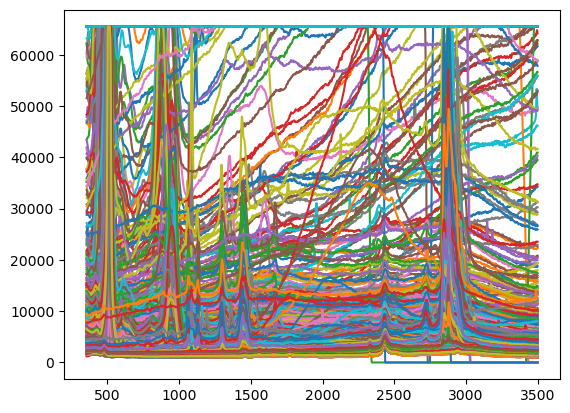

In [129]:
_ = plt.plot(spectra_data_raman.loc[:,idx_gl_r].T)

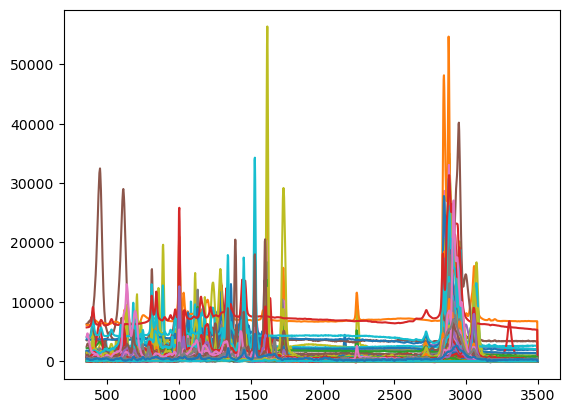

In [125]:
_ = plt.plot(slopp_slopp_e_pivot.loc[:,idx_sl].T)

In [32]:
pred_raman = corr_matching(x_train_raman, y_train_raman, 
                      x_test_raman, r_min=0)
pred_polymers_raman = pred_raman[0]
pred_hqi_raman = pred_raman[1]
pred_df_raman = pd.DataFrame(pred_polymers_raman)
pred_df_raman.columns = ['polymer_slopp']
pred_df_raman['hqi_slopp'] = pred_hqi_raman
pred_df_raman.reset_index().query('hqi_slopp>.7').groupby('polymer_slopp').count()

,index,hqi_slopp
polymer_slopp,,
Polyethylene,455,455
Polyethylene-co-Polypropylene,1,1
Polymethyl Methacrylate,5,5
Polypropylene,2,2
Polyvinyl Chloride,1,1
Rubber,1,1


In [143]:
pred_raman = corr_matching(x_train_raman, y_train_raman, 
                      x_test_raman, r_min=0)
pred_polymers_raman = pred_raman[0]
pred_hqi_raman = pred_raman[1]
pred_df_raman = pd.DataFrame(pred_polymers_raman)
pred_df_raman.columns = ['polymer_slopp']
pred_df_raman['hqi_slopp'] = pred_hqi_raman
pred_df_raman.reset_index().query('hqi_slopp>.7').groupby('polymer_slopp').count()

,index,hqi_slopp
polymer_slopp,,
Cellulose Acetate,1,1
Polyethylene,426,426
Polyethylene-co-Polypropylene,1,1
Polymethyl Methacrylate,1,1
Polypropylene,30,30
Rubber,1,1


In [33]:
missing_int_raman = (np.abs(np.diff(x_test_raman,1)) < 0.00001).sum(1)

In [34]:
np.argmax(missing_int_raman)

1010

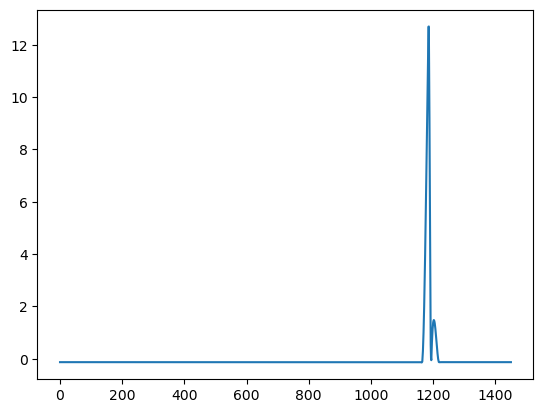

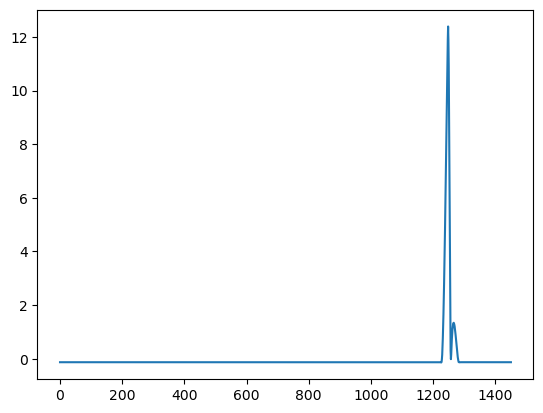

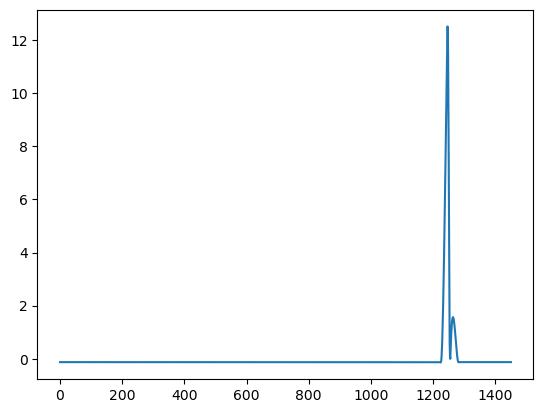

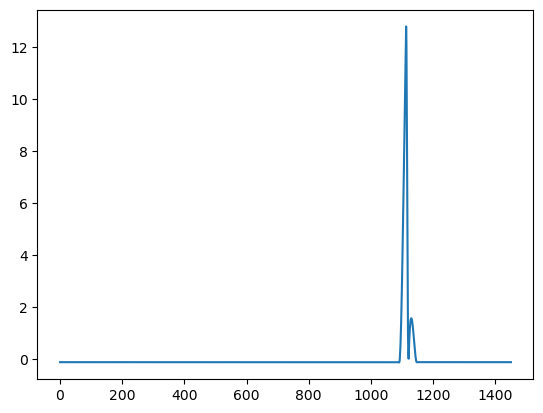

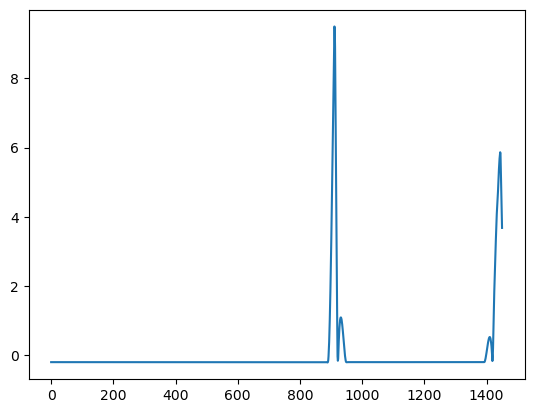

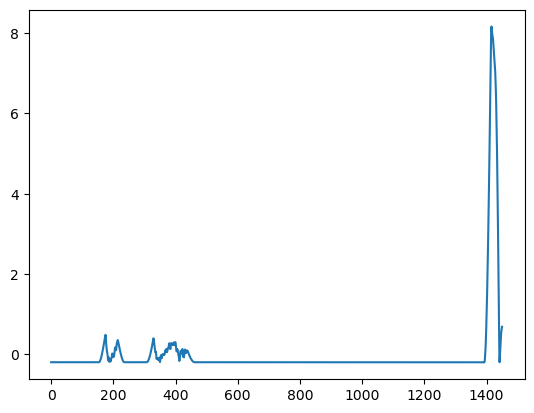

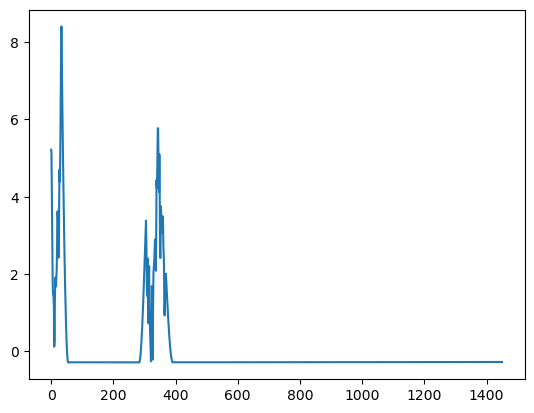

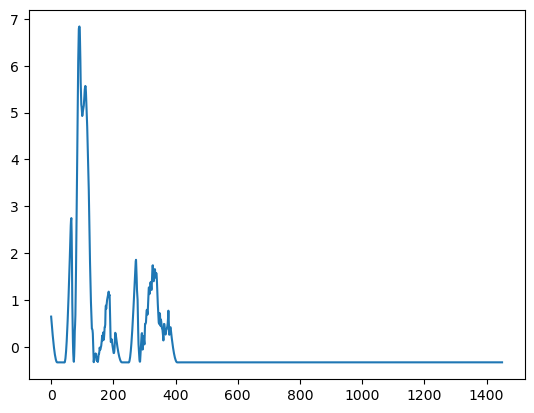

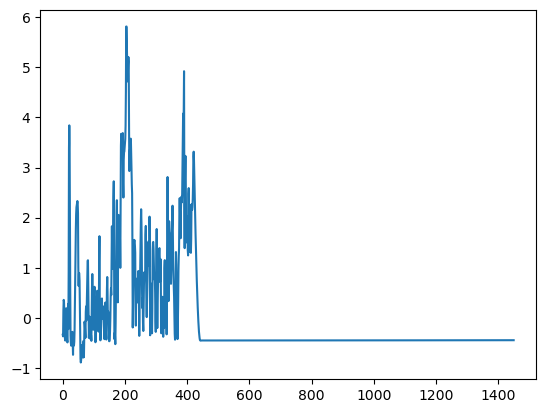

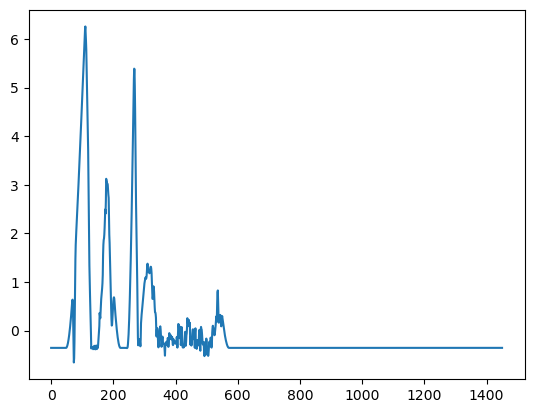

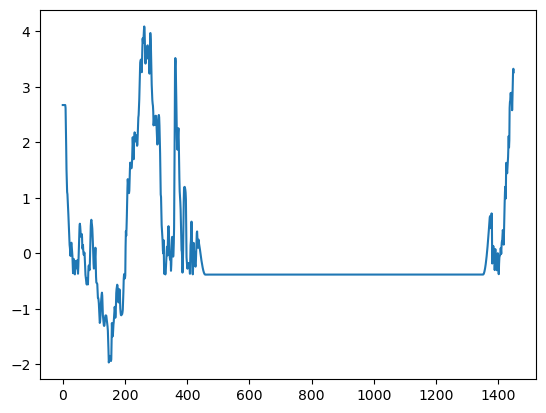

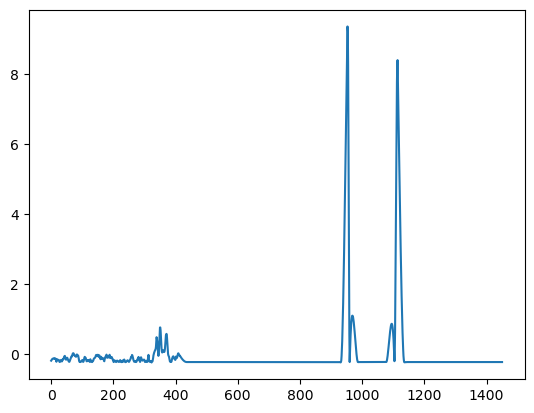

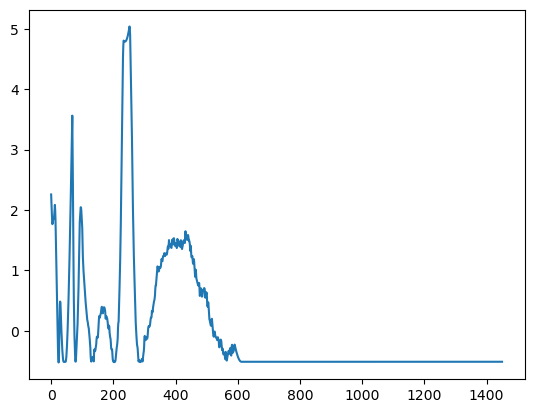

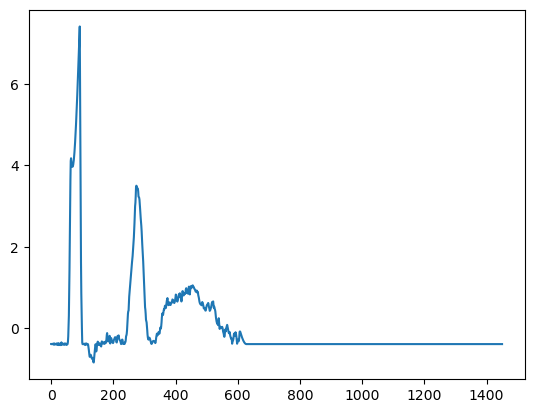

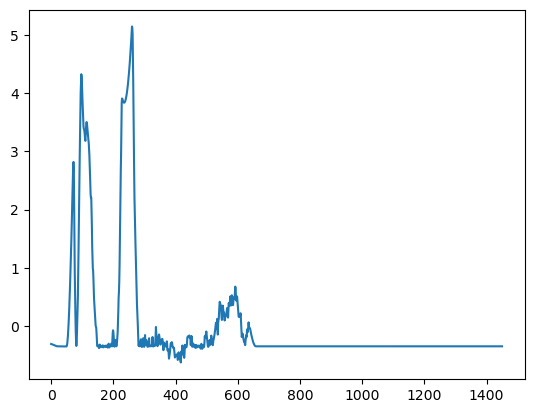

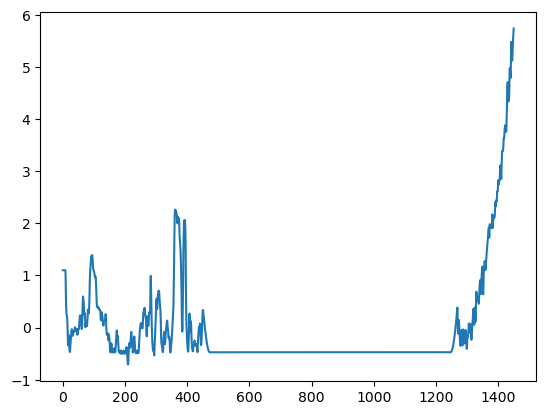

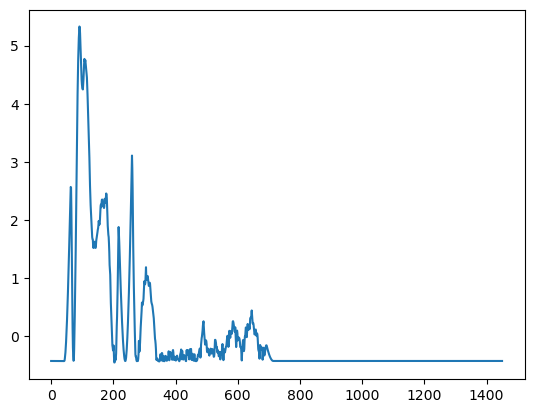

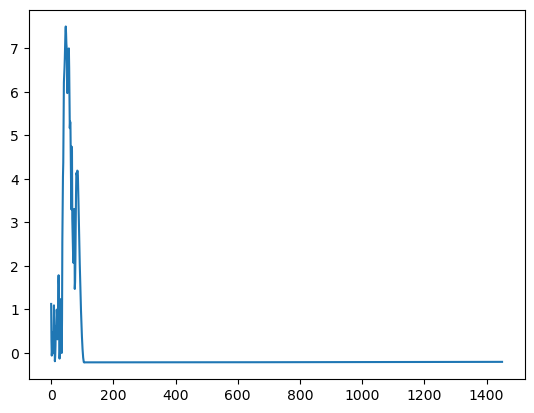

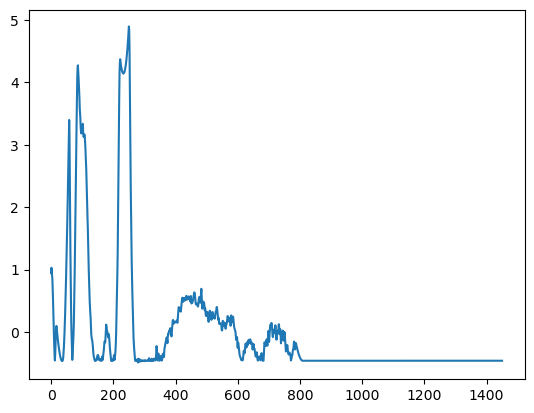

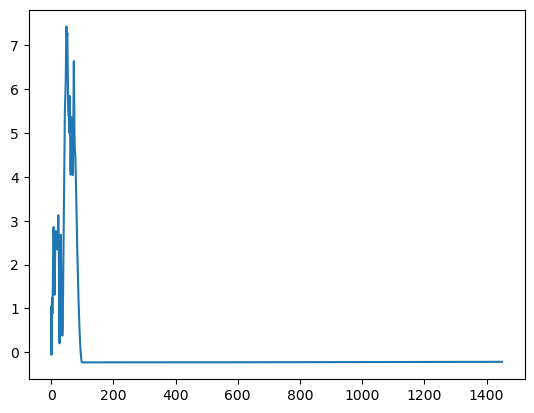

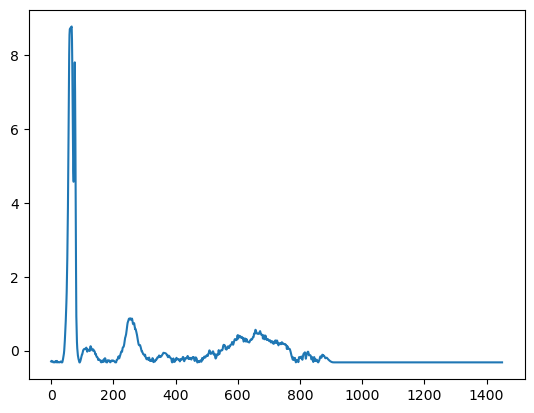

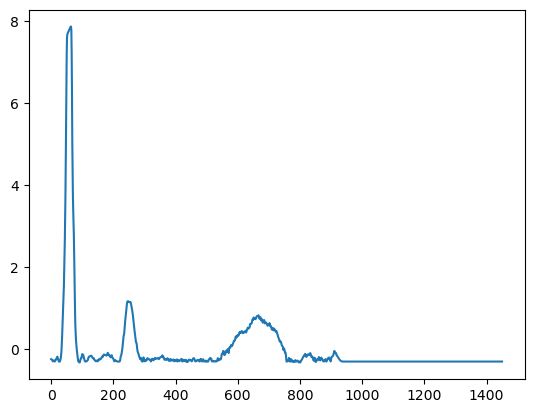

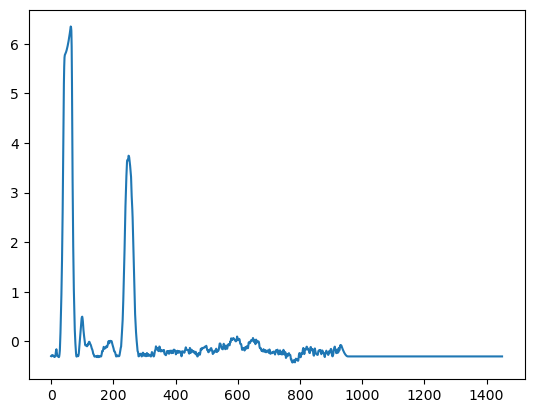

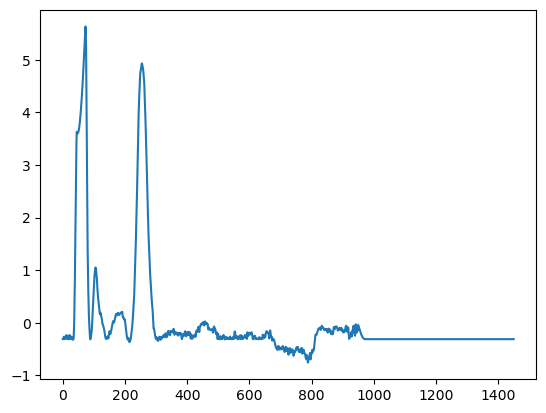

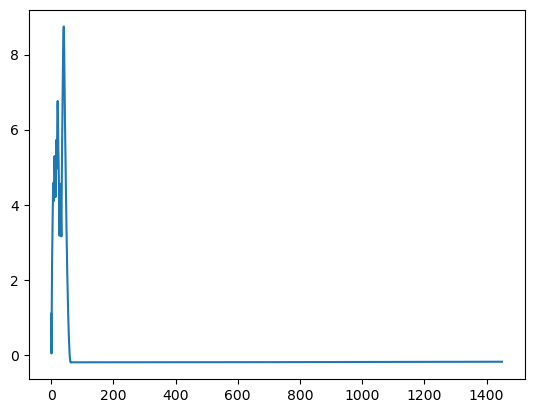

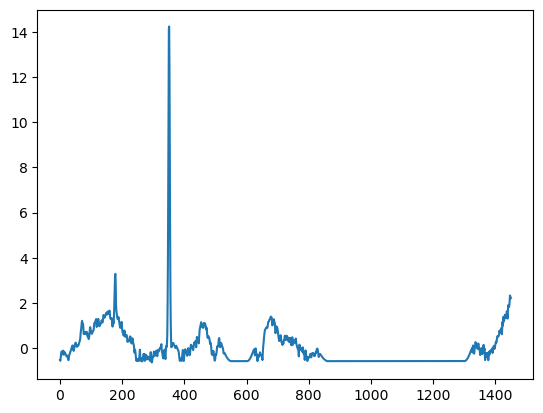

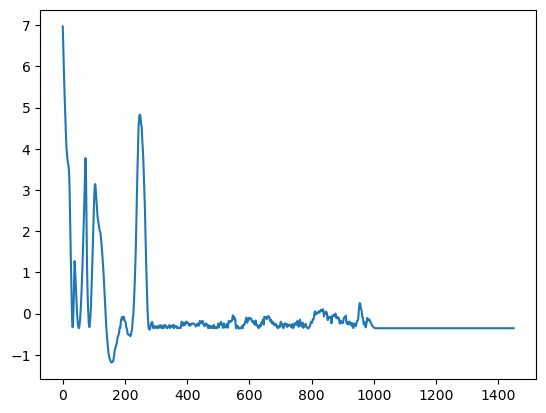

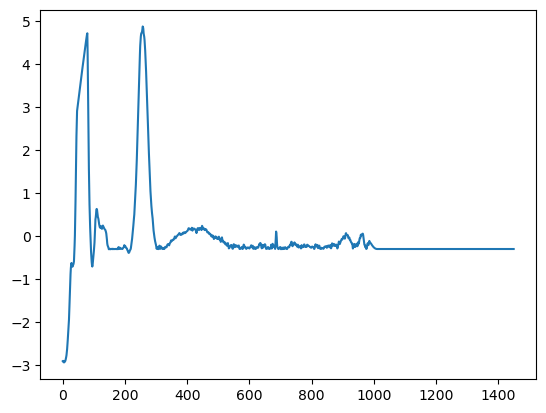

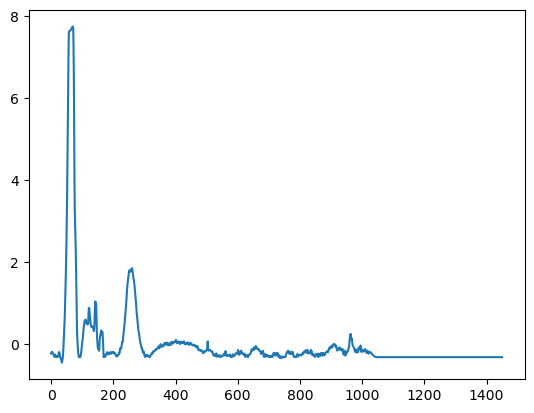

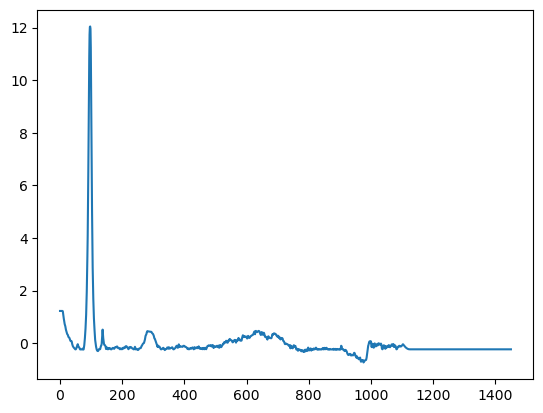

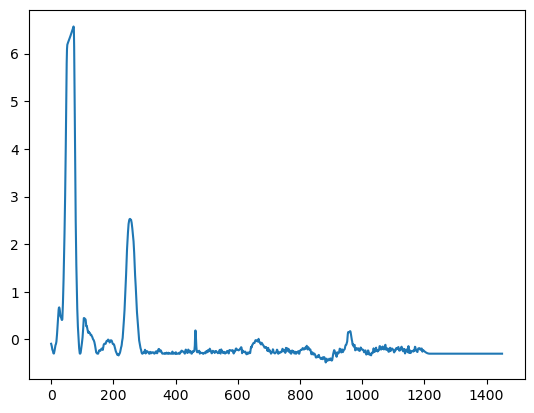

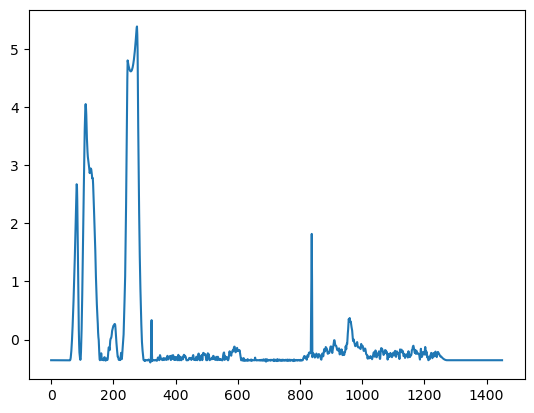

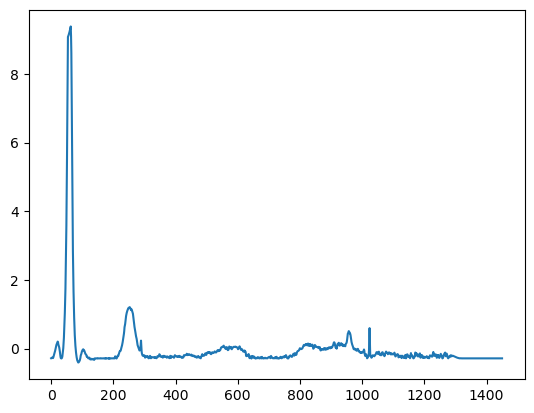

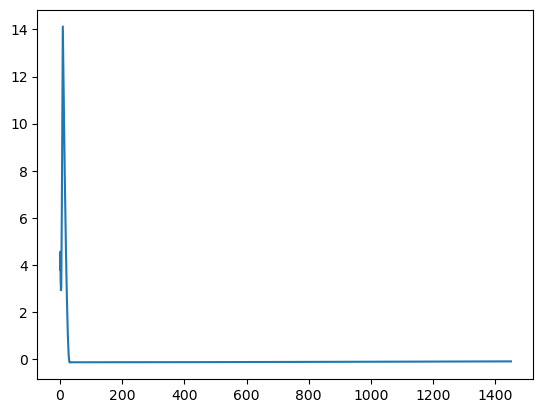

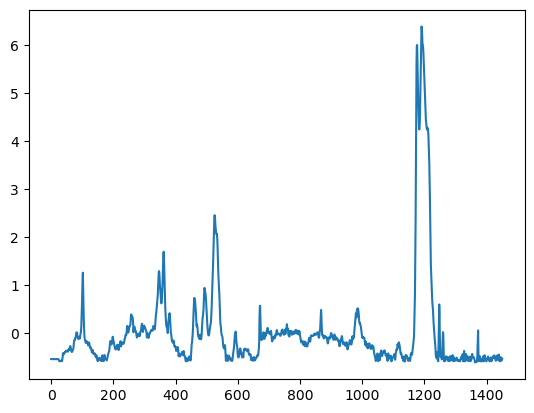

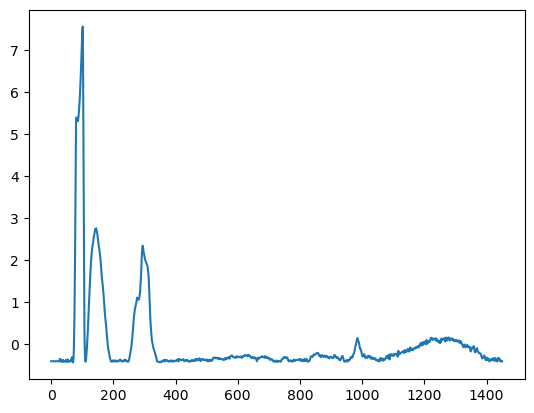

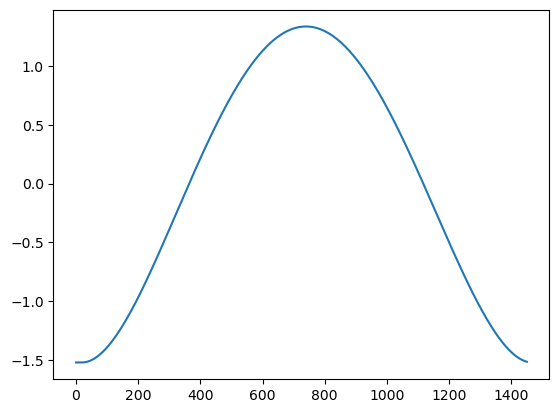

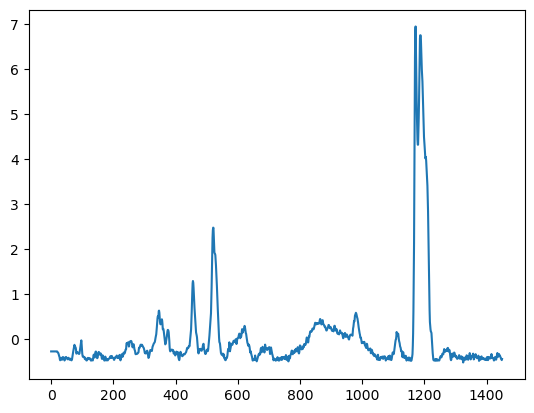

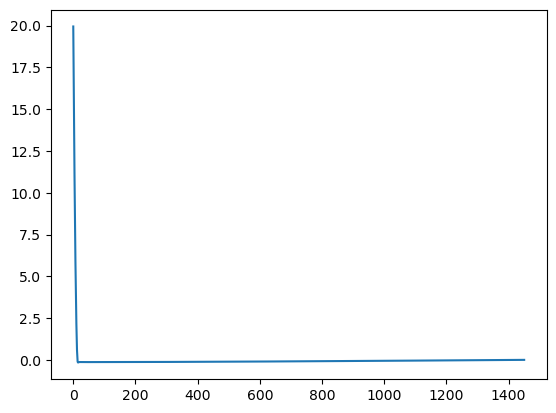

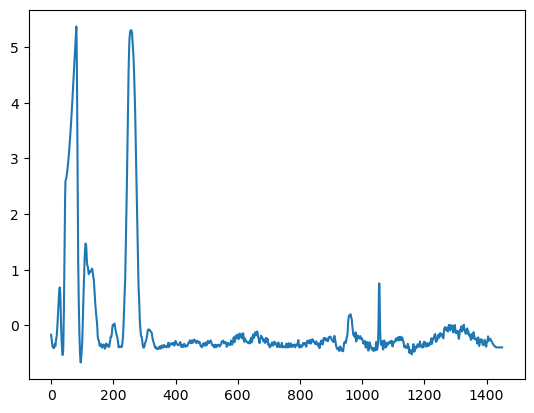

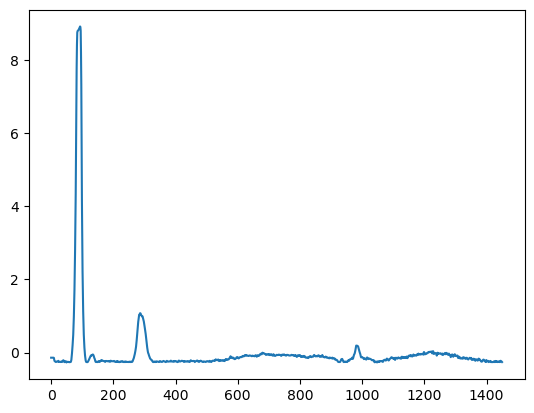

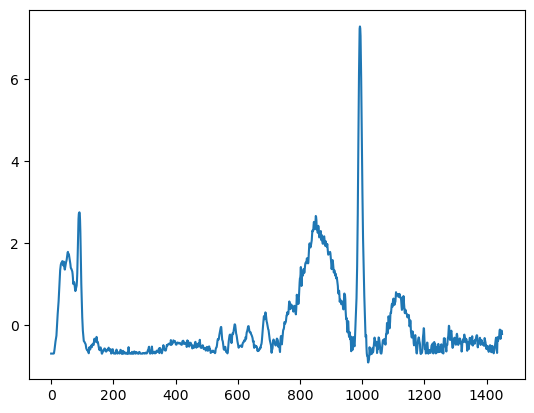

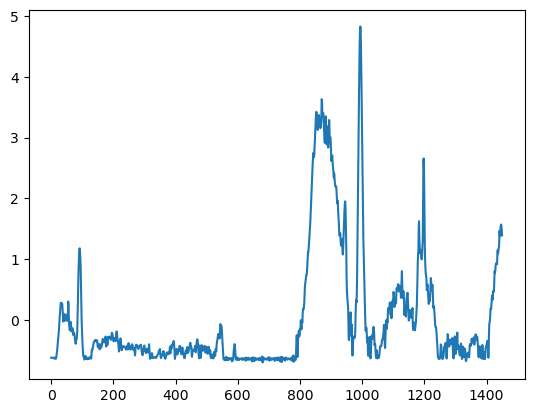

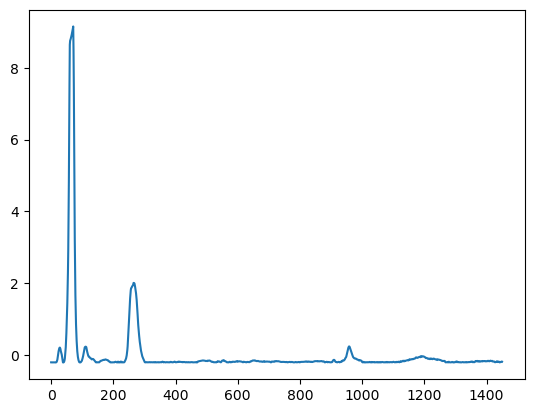

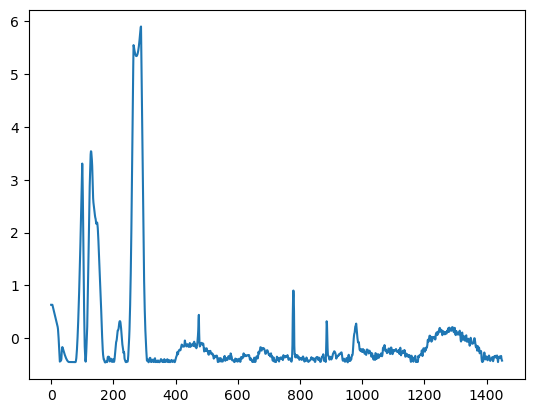

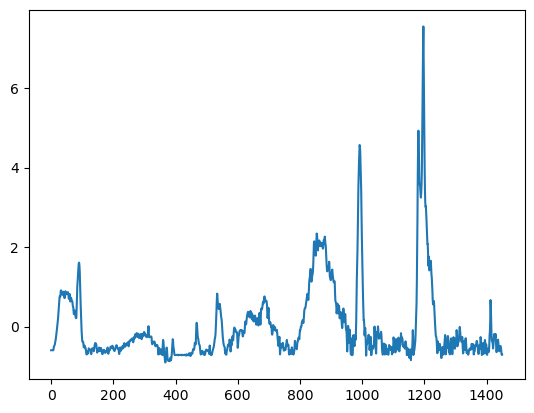

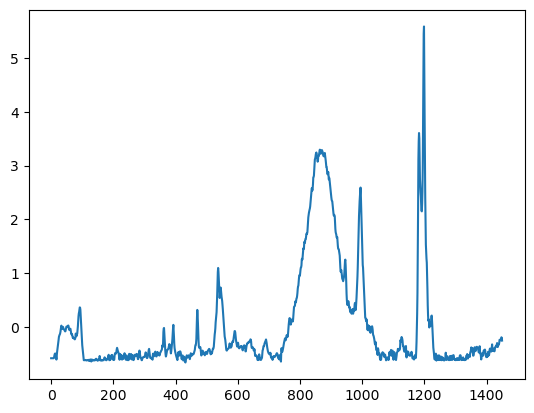

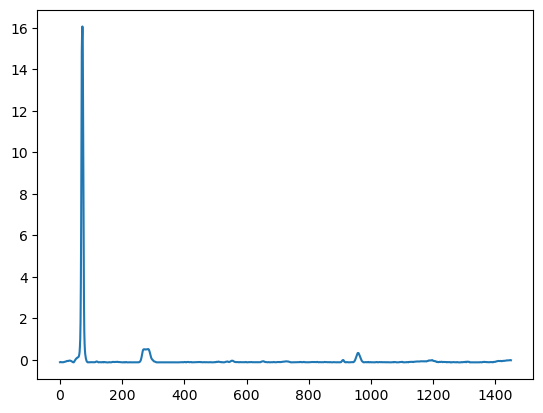

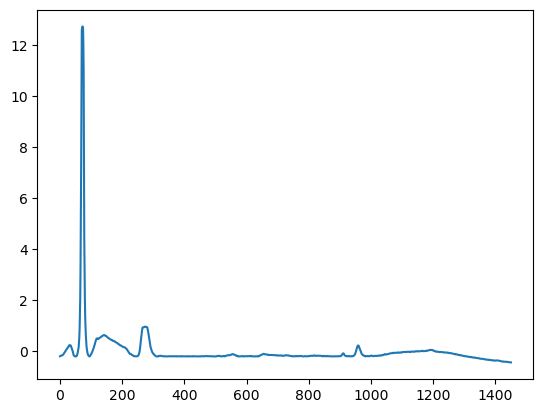

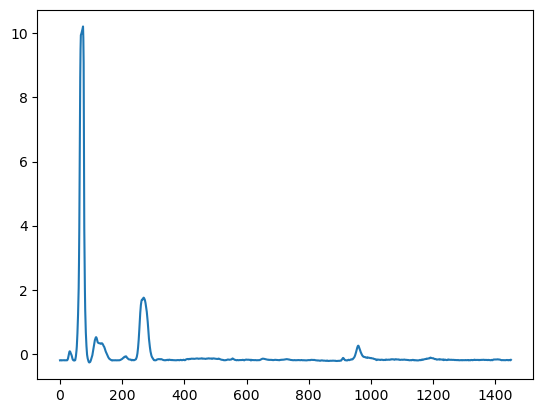

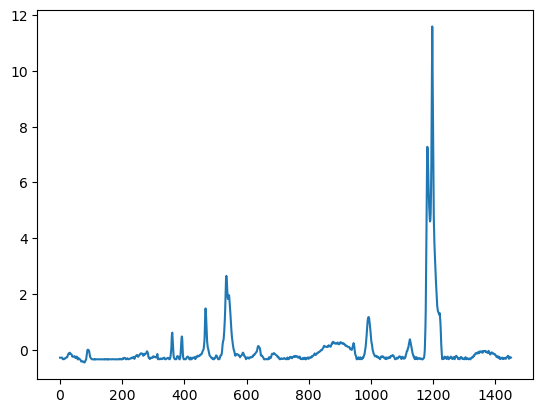

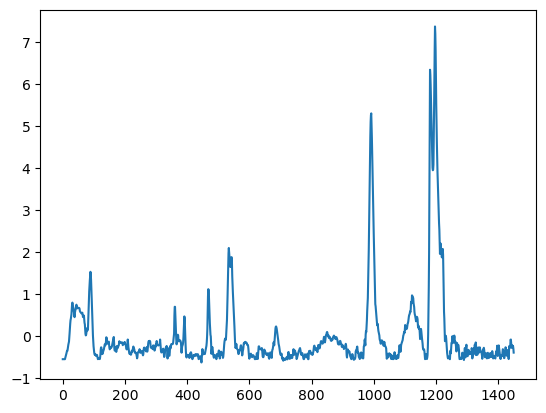

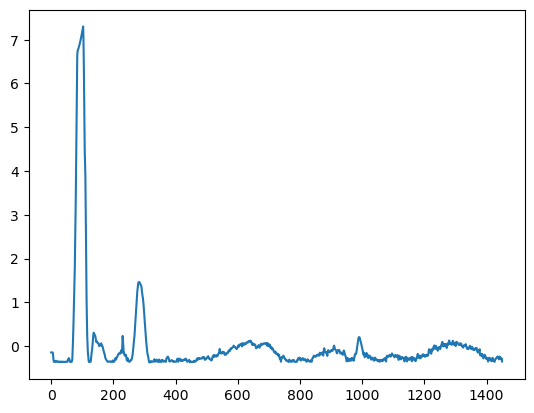

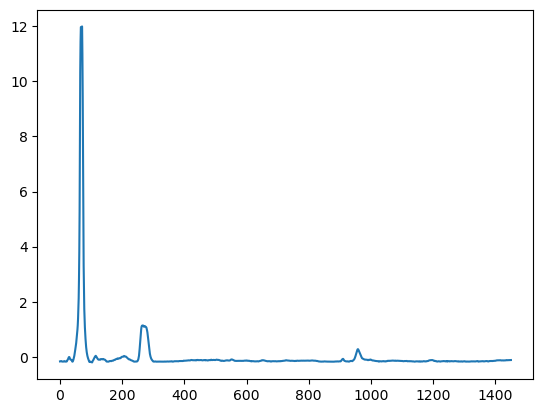

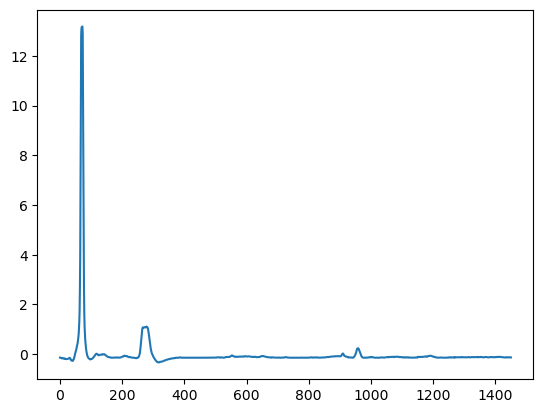

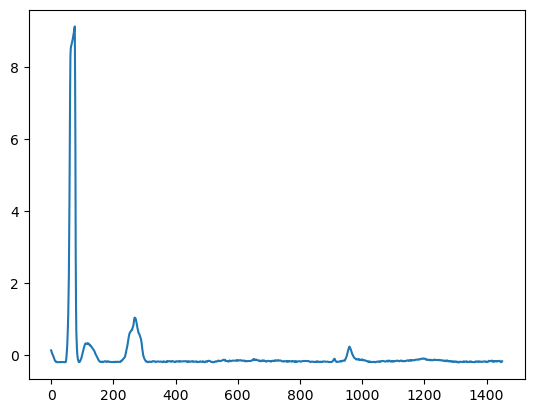

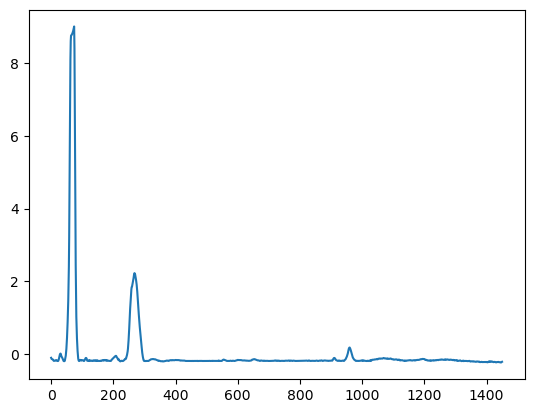

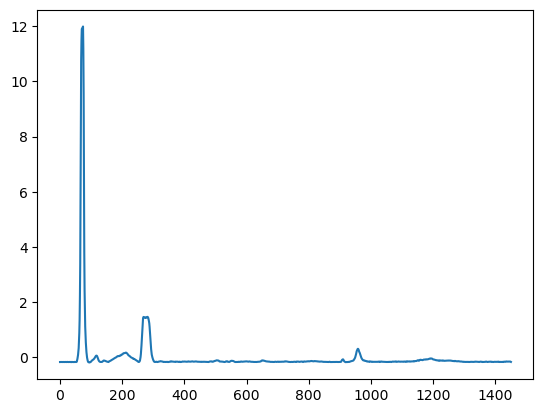

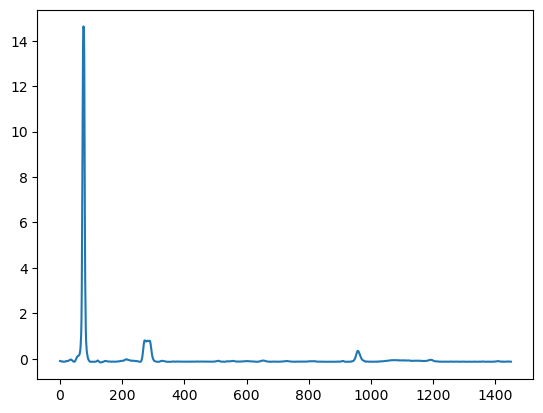

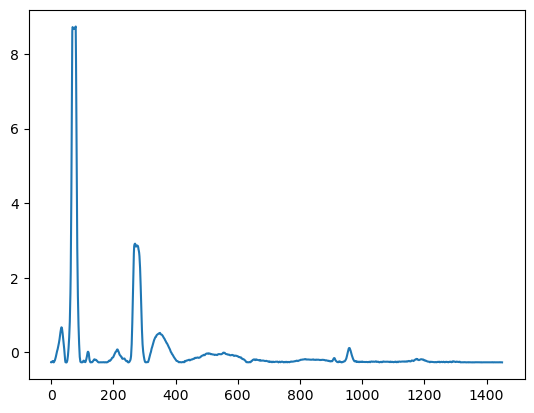

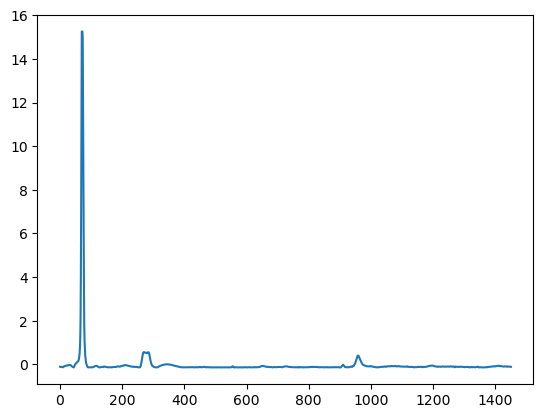

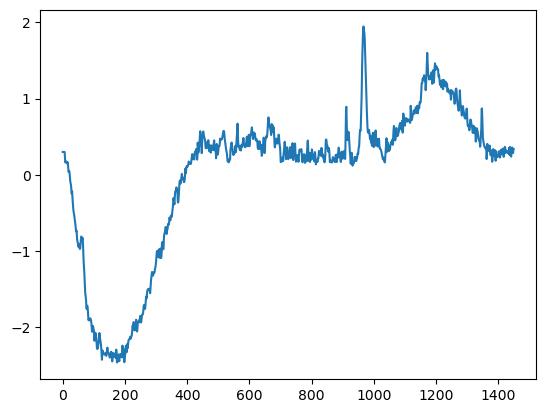

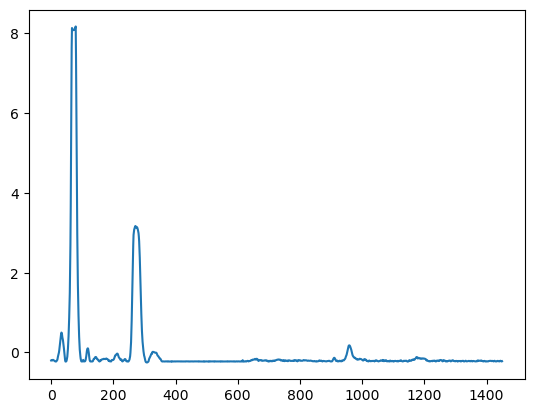

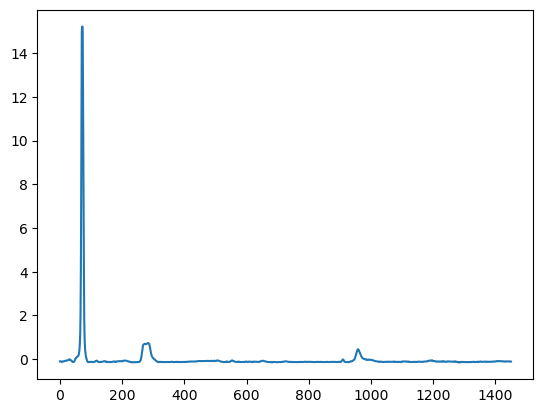

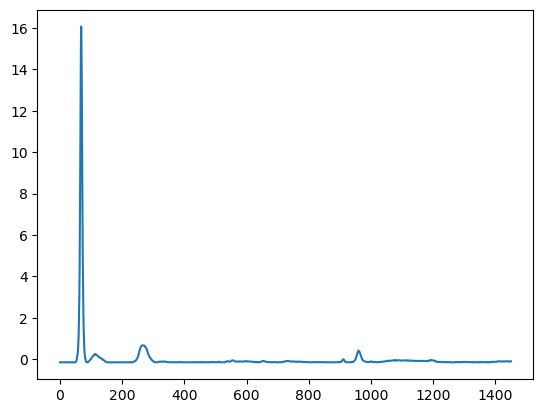

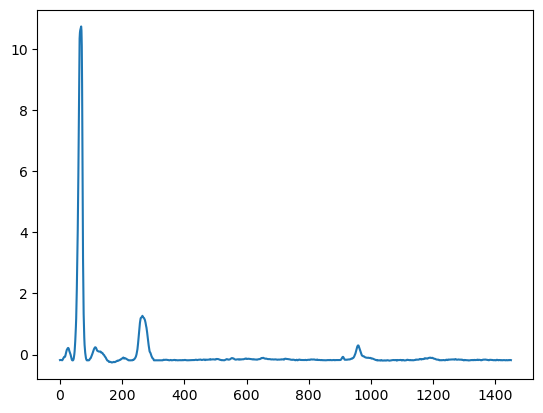

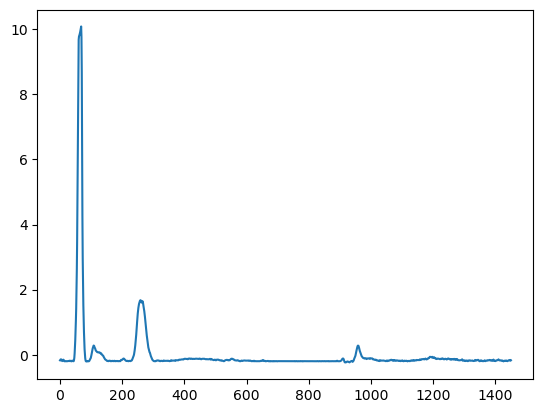

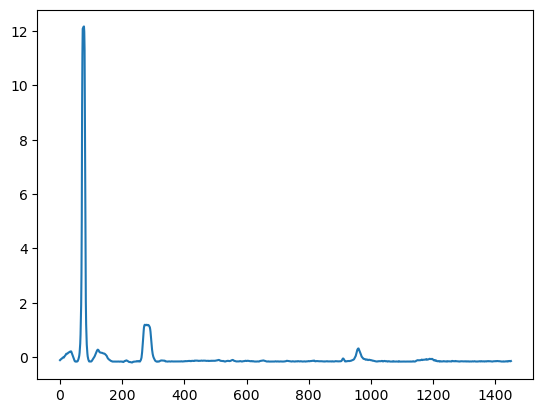

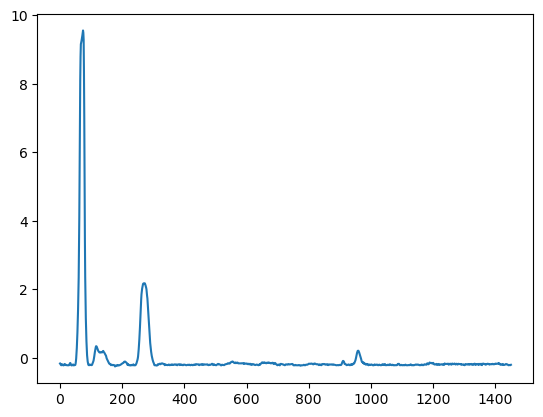

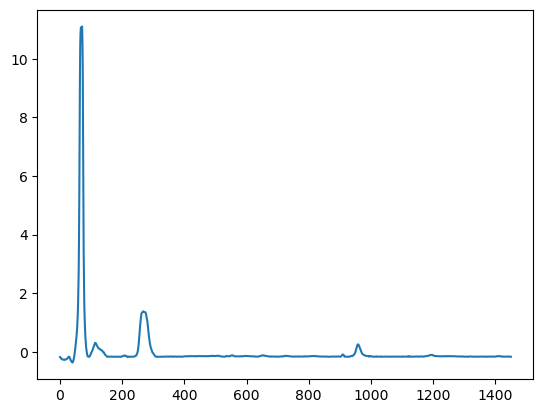

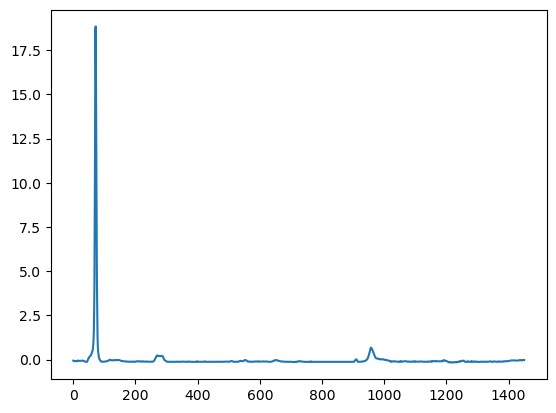

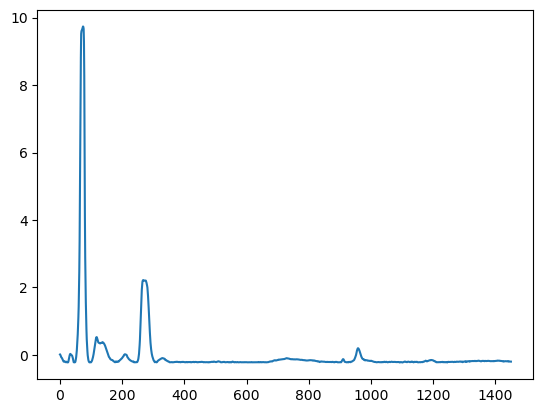

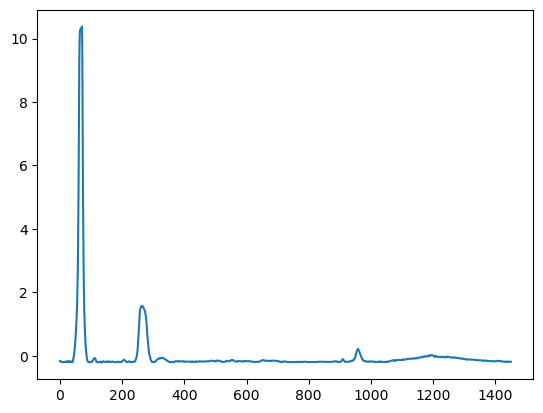

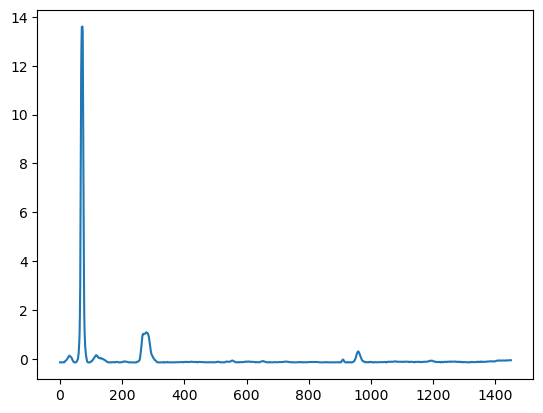

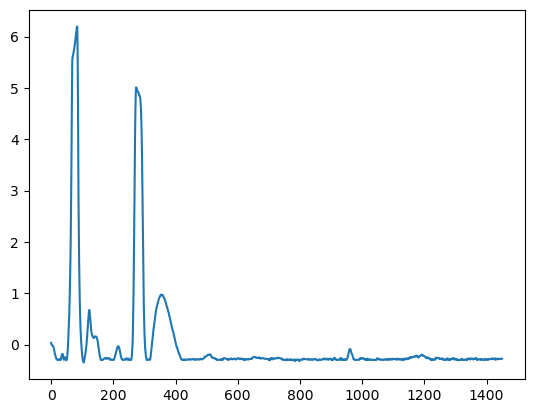

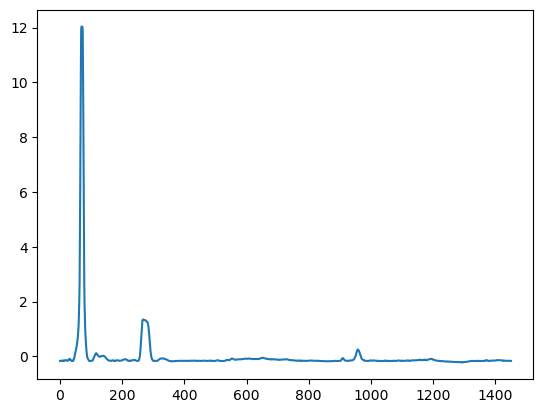

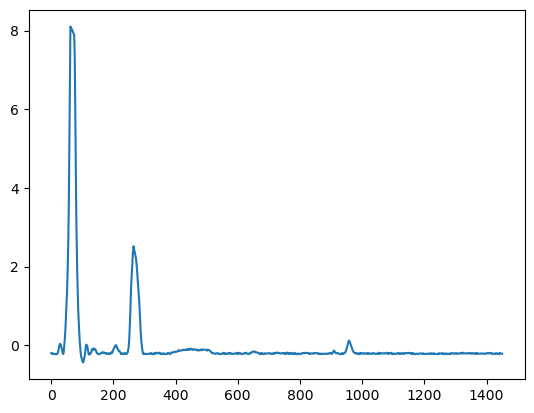

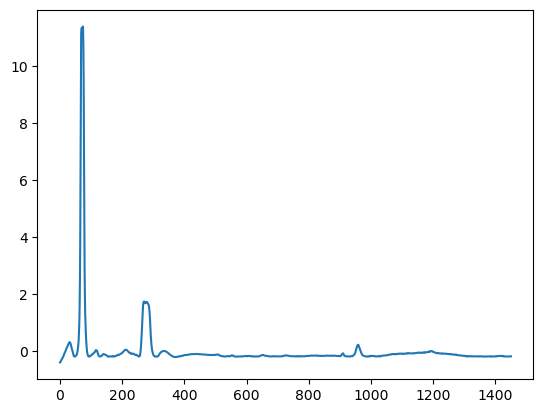

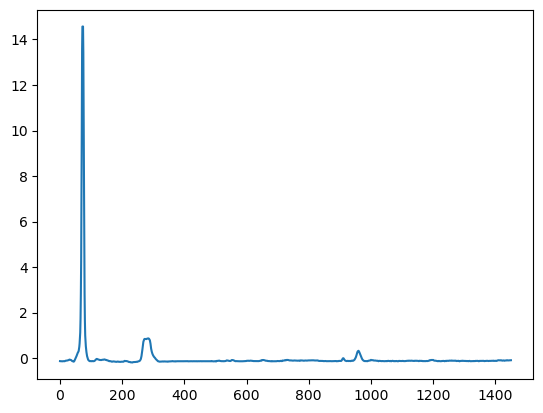

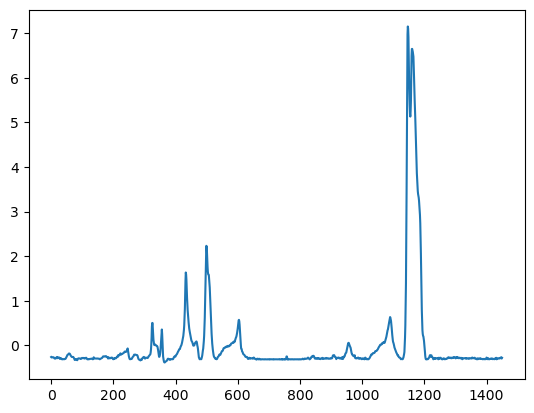

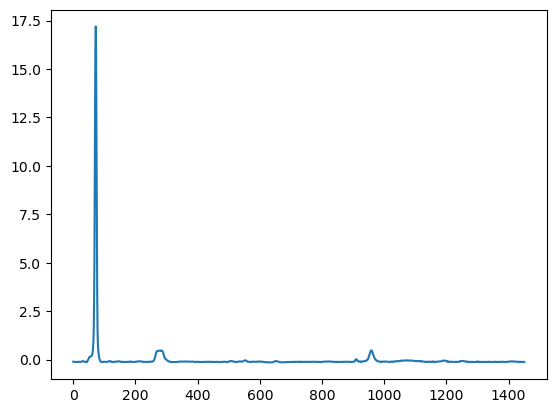

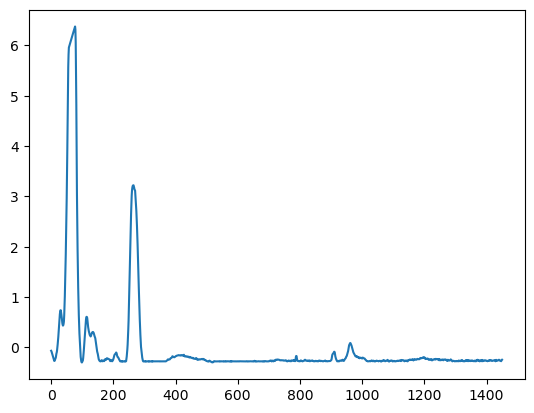

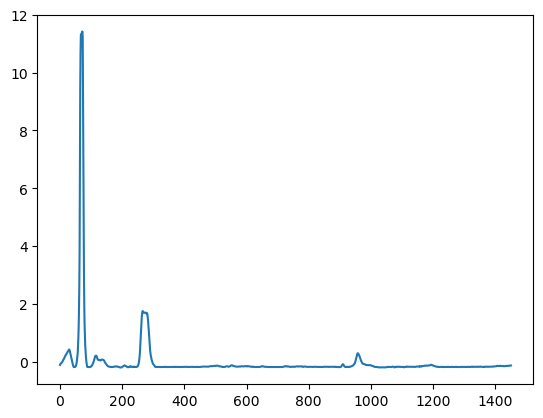

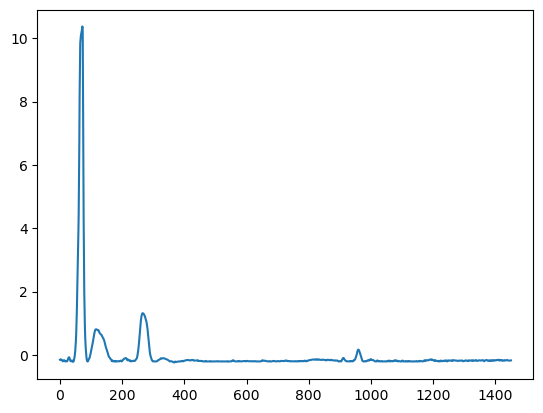

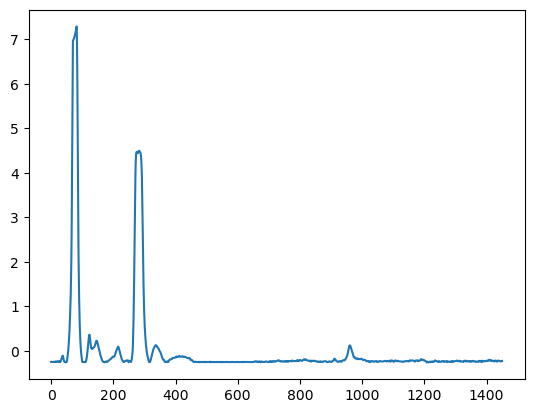

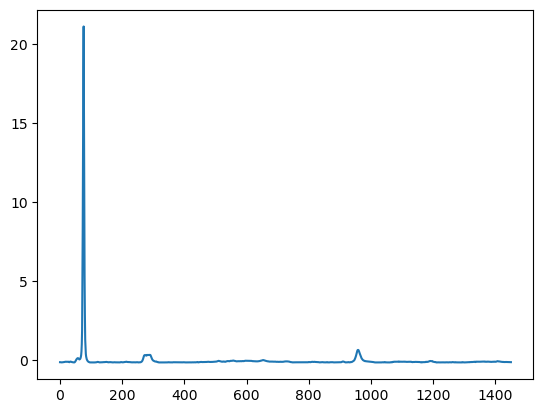

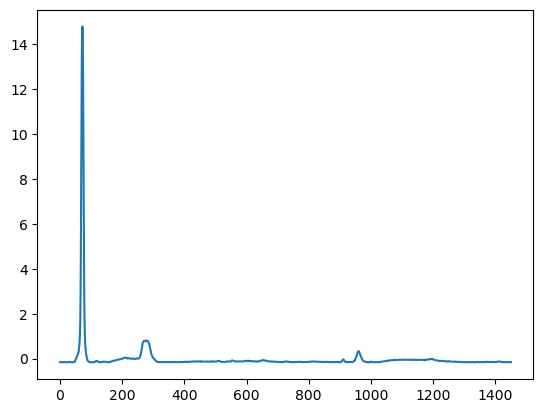

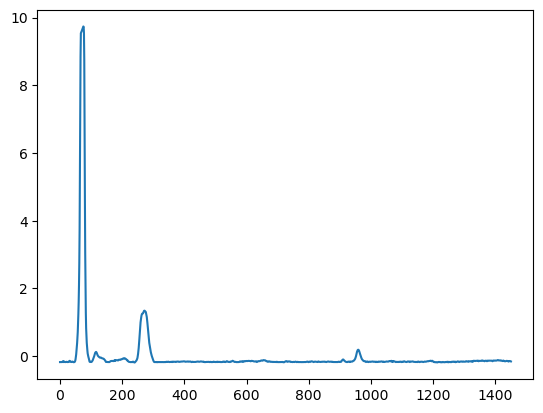

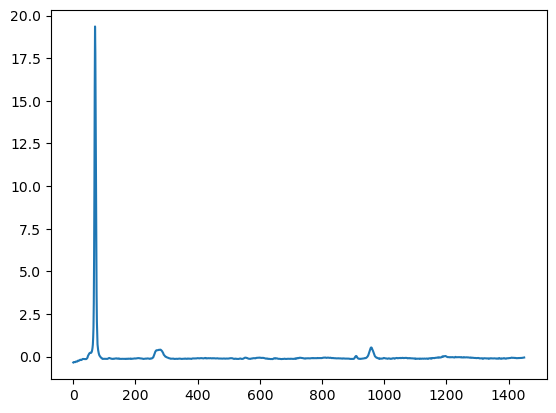

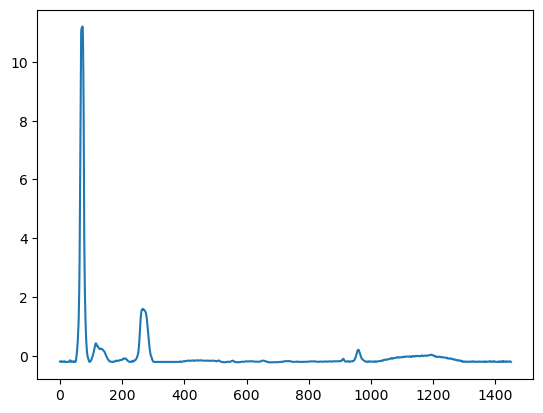

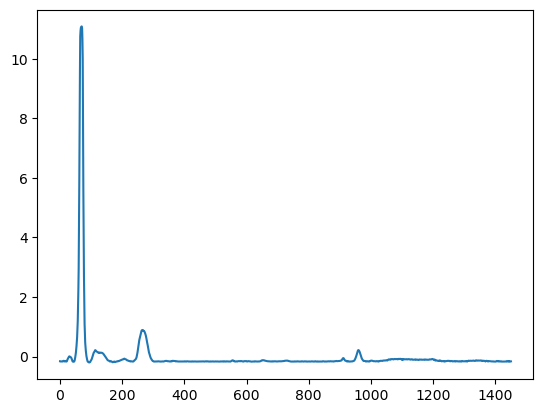

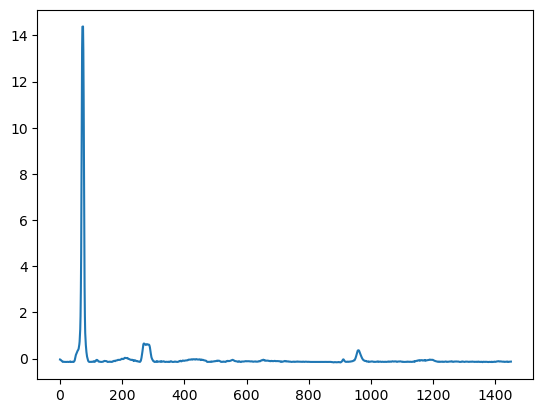

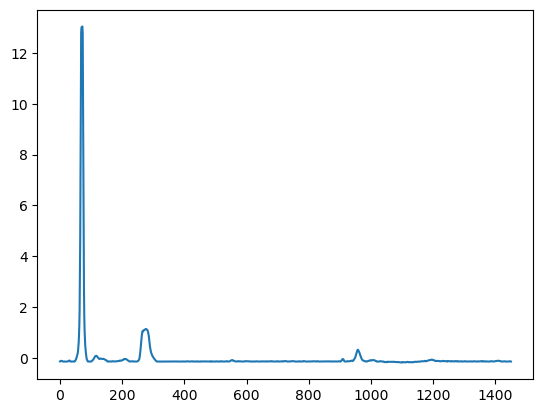

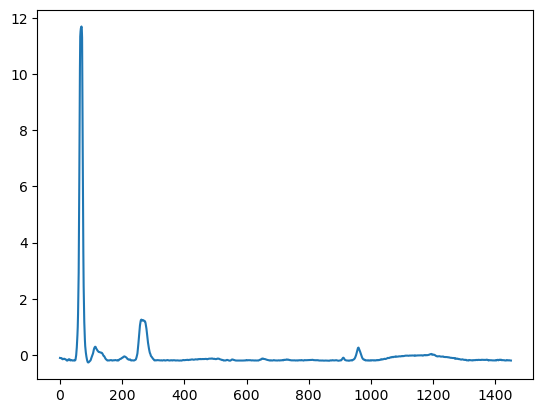

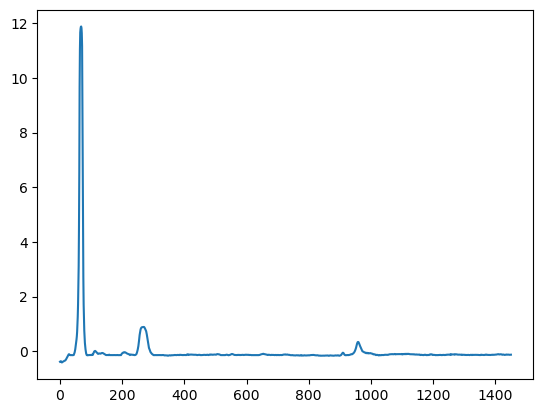

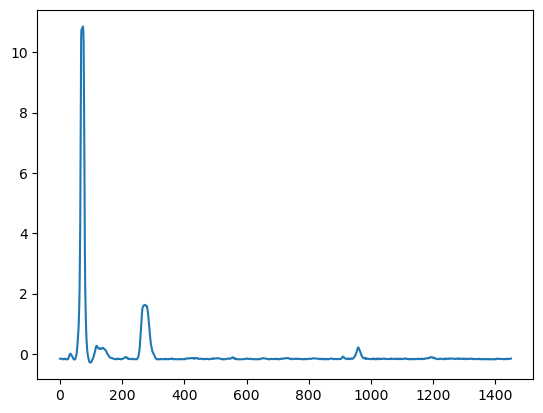

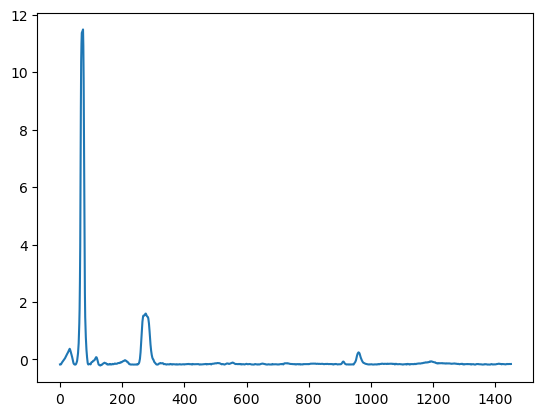

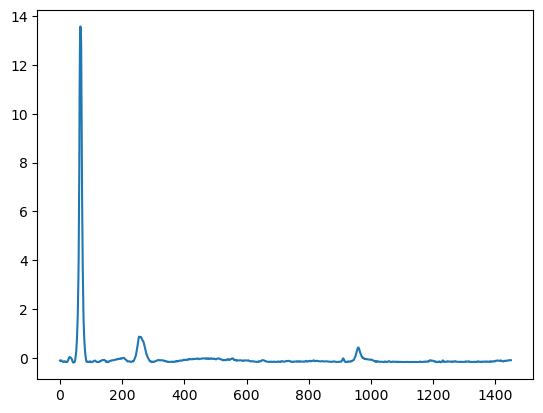

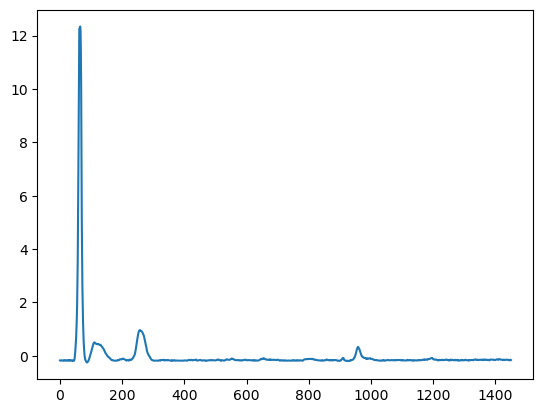

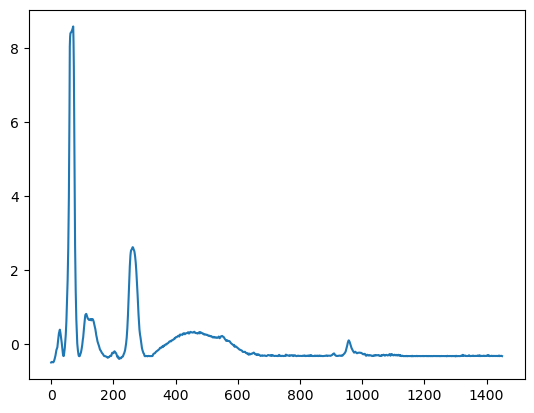

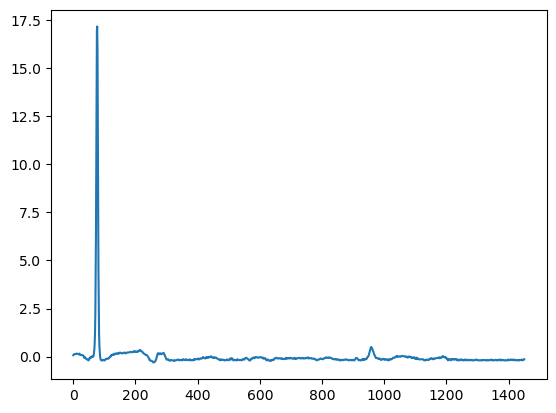

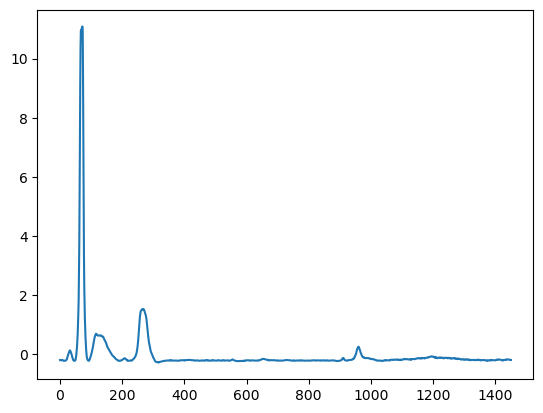

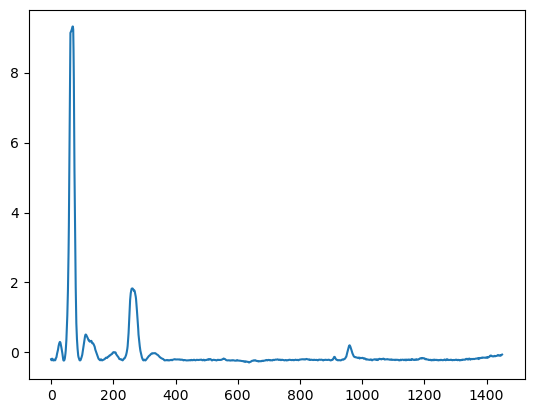

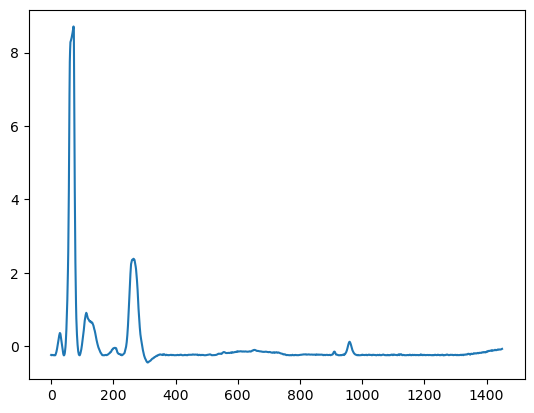

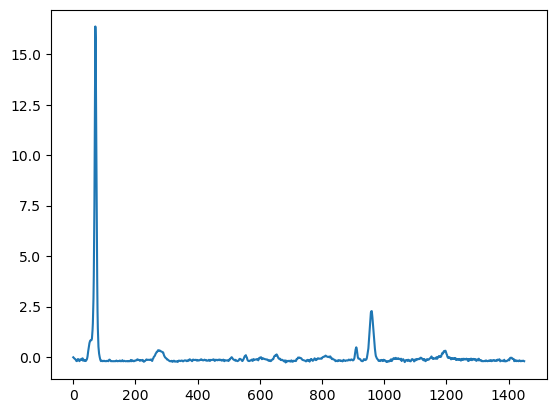

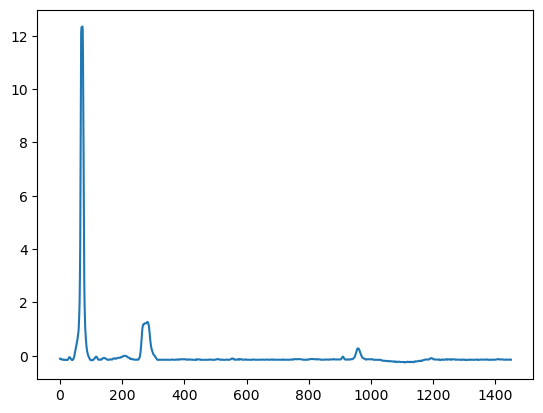

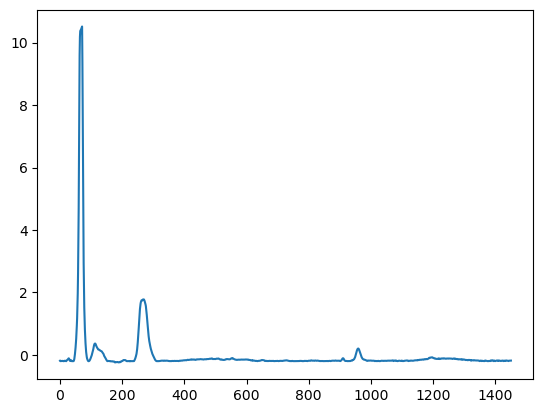

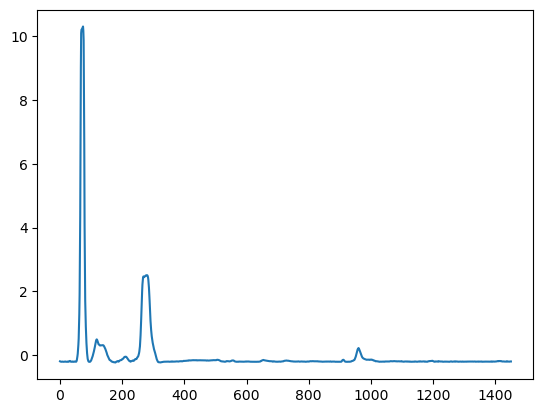

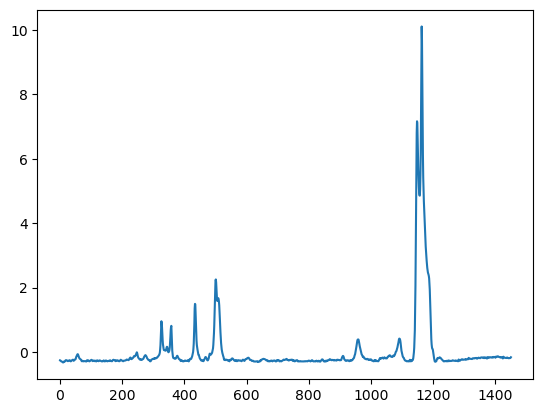

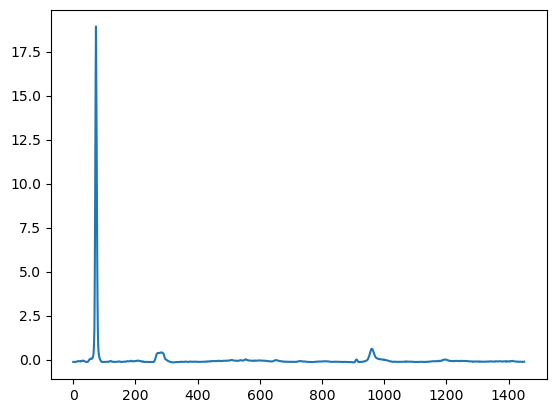

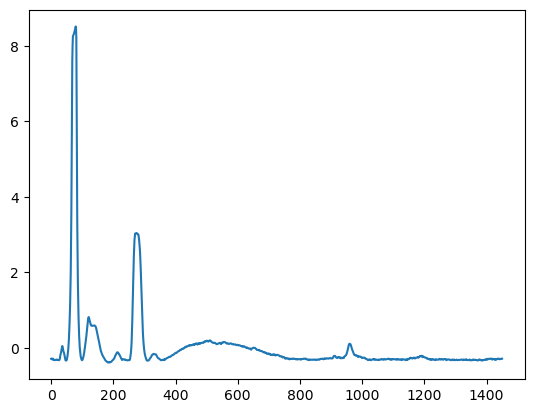

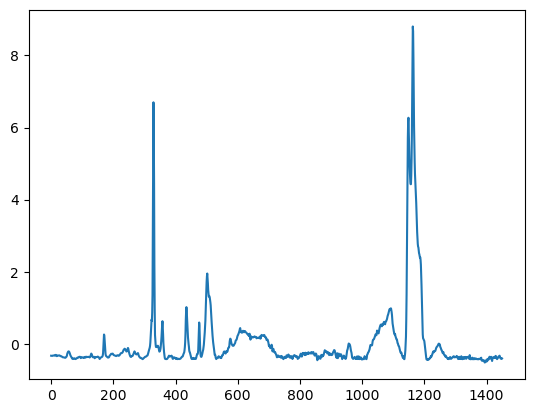

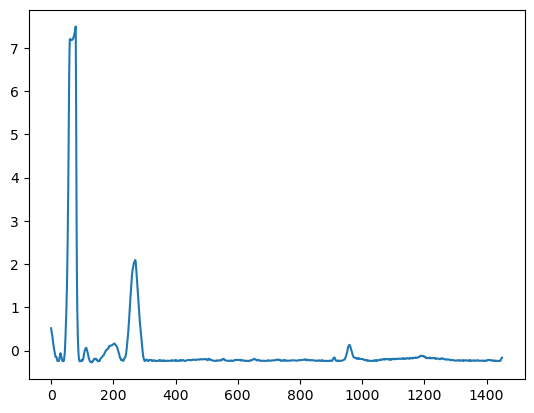

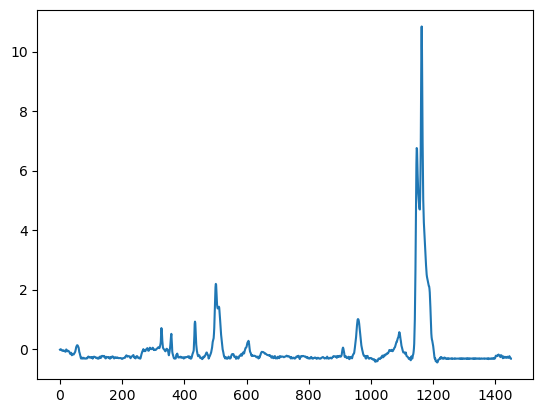

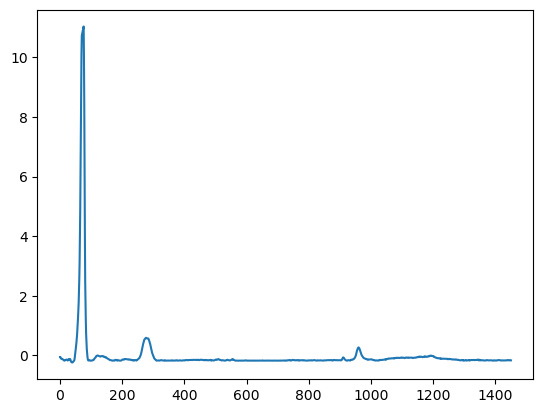

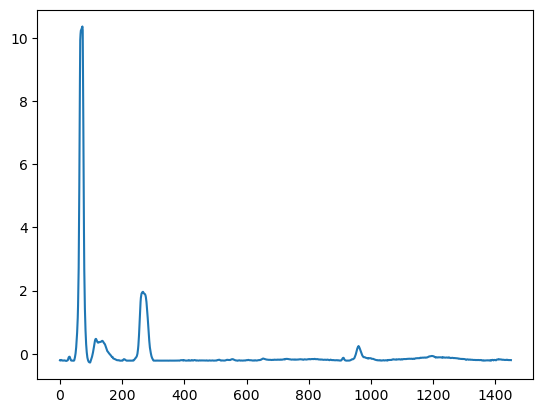

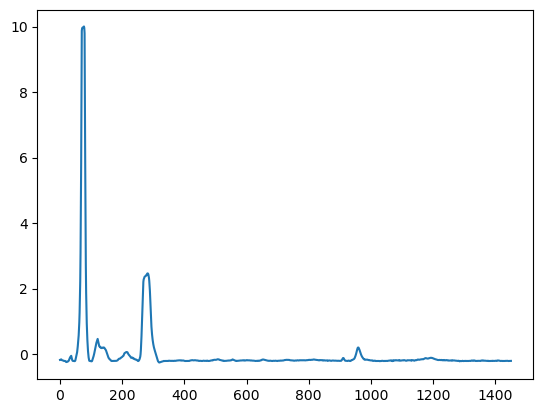

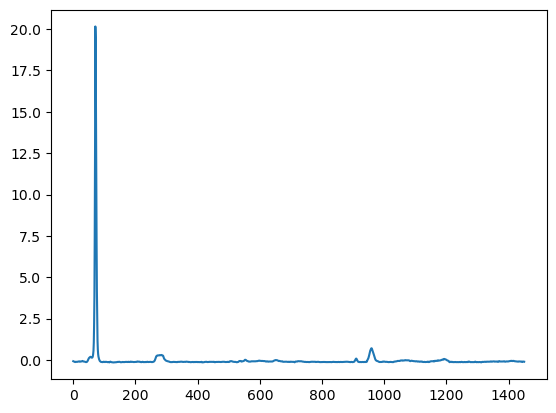

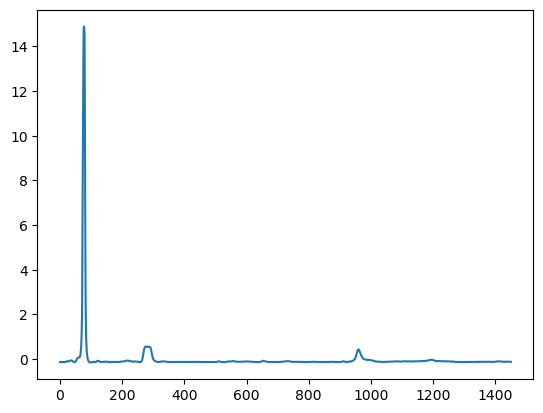

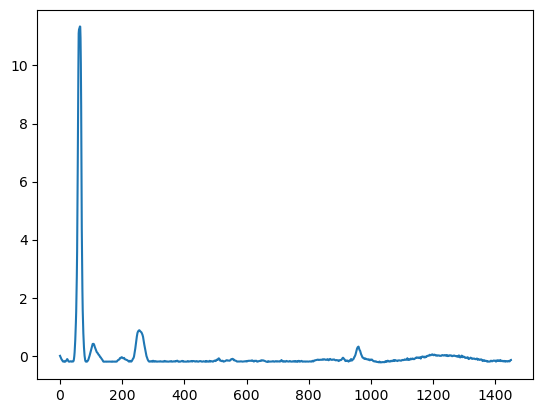

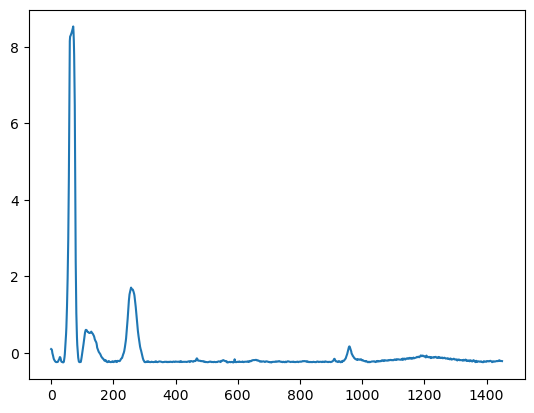

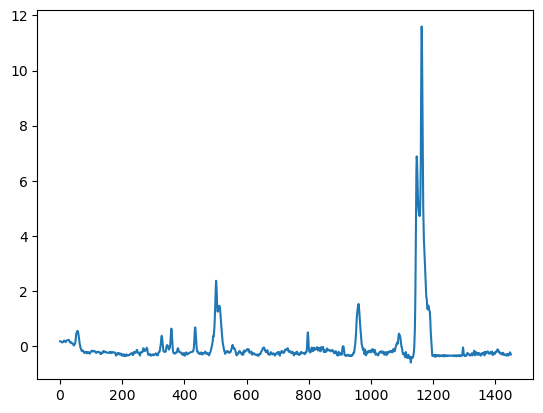

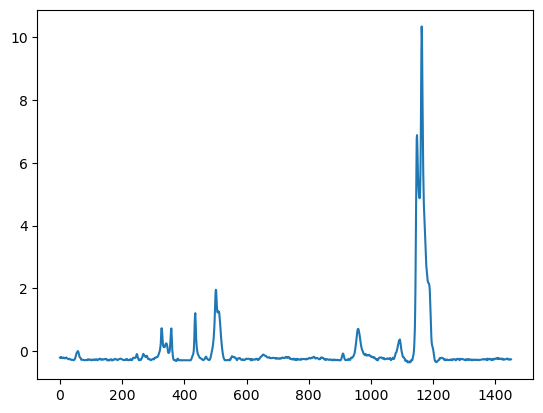

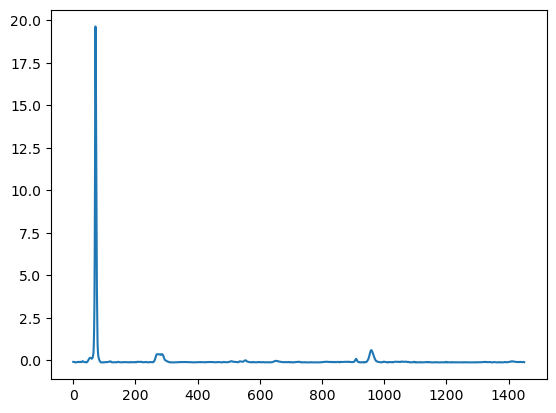

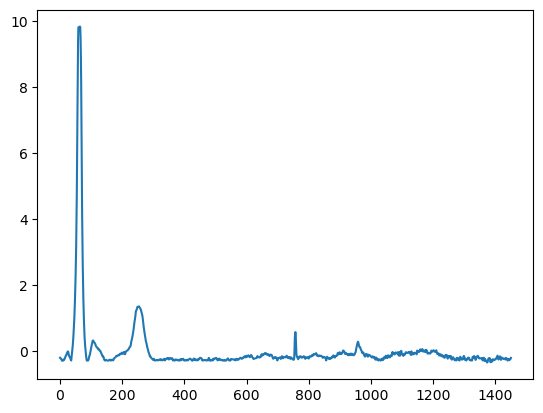

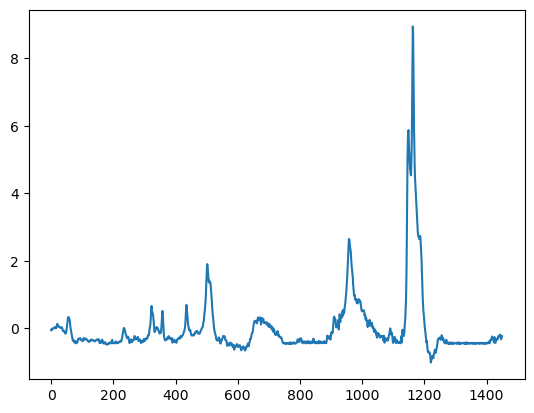

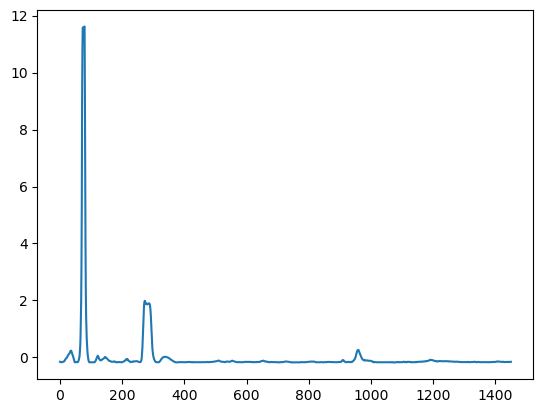

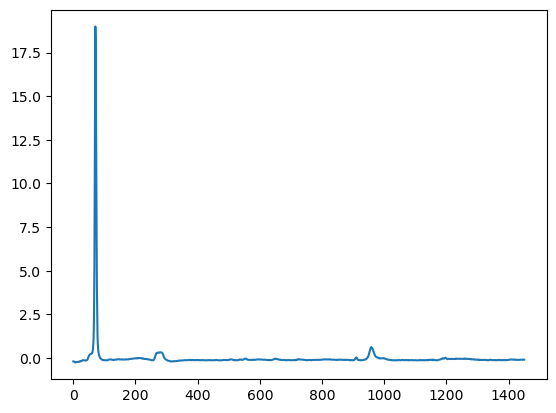

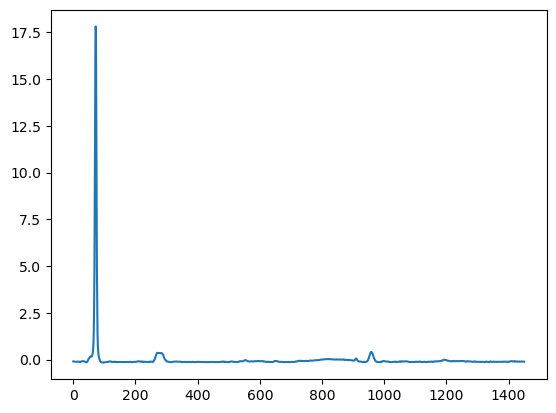

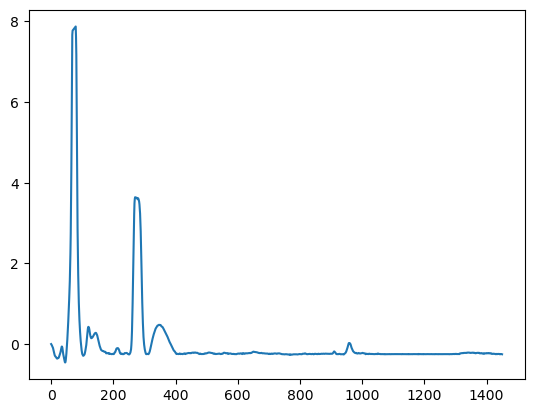

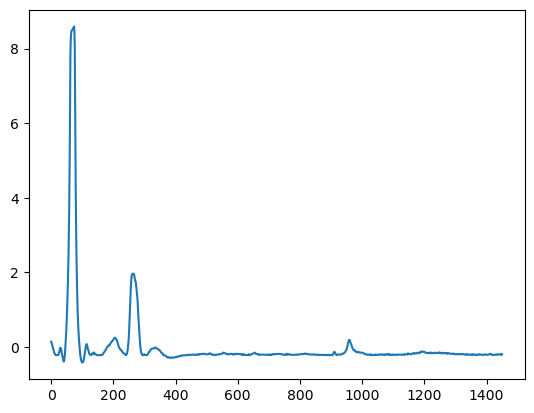

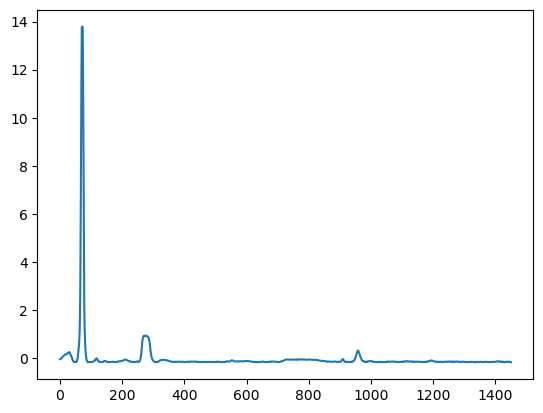

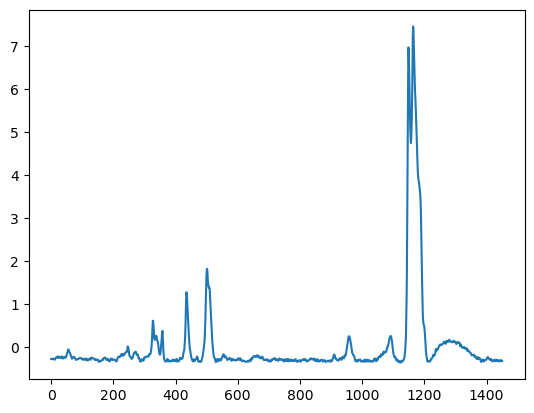

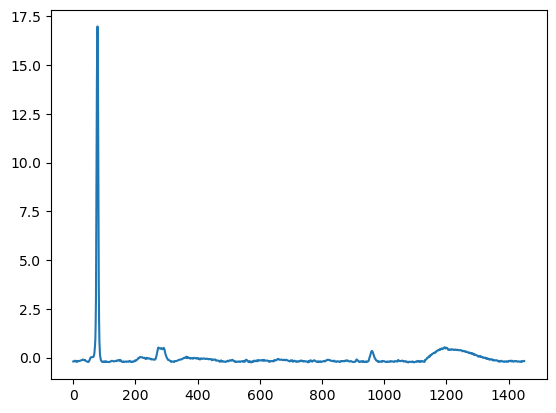

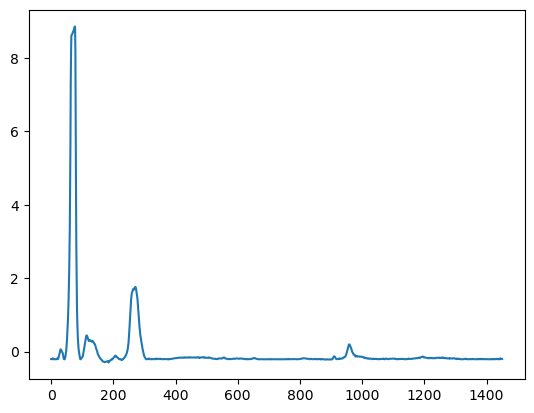

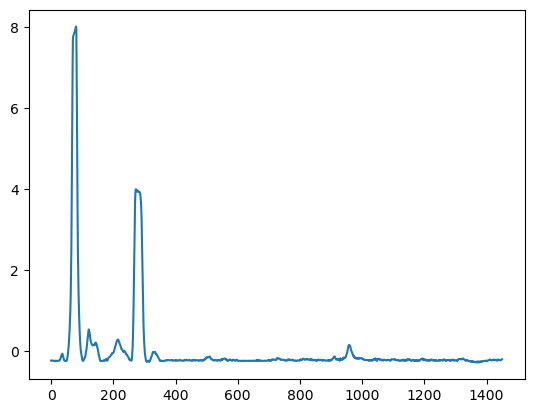

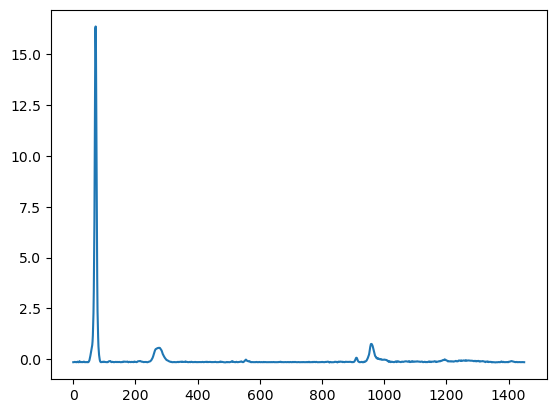

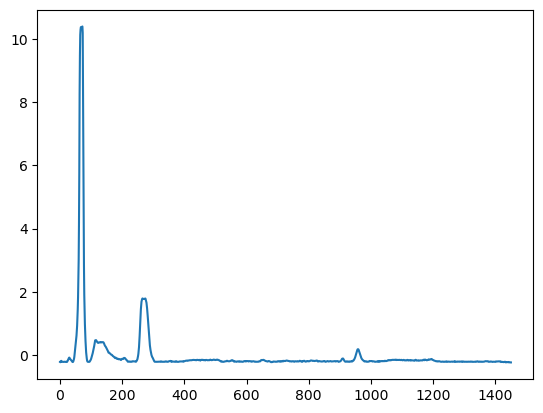

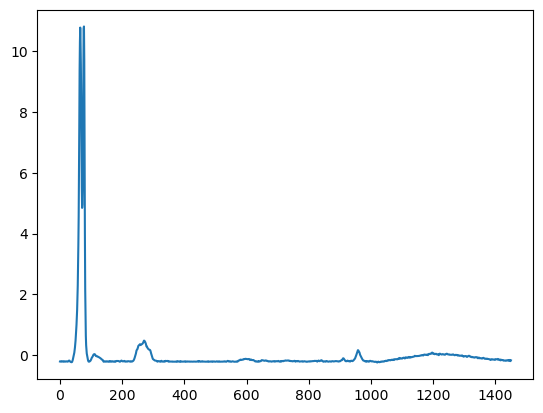

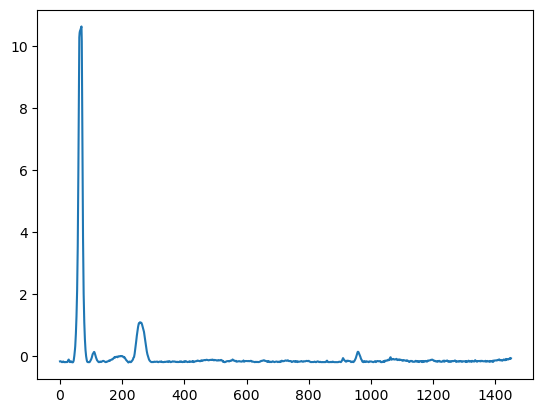

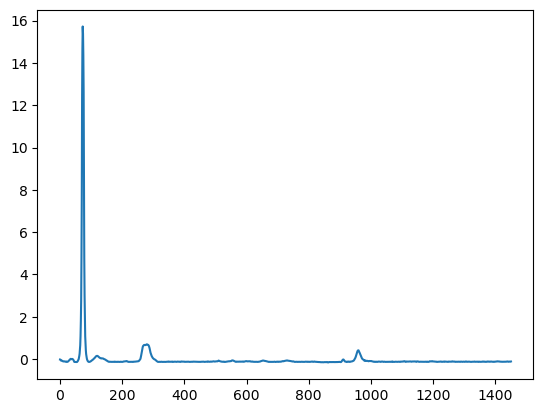

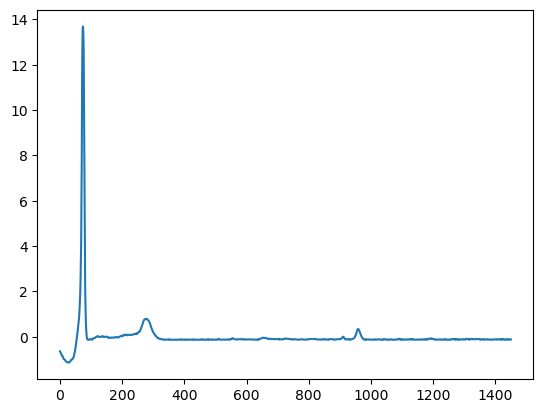

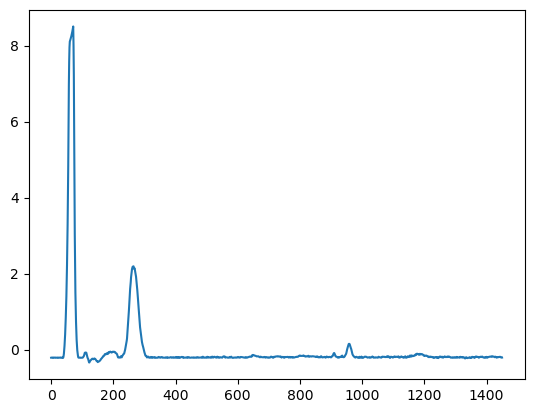

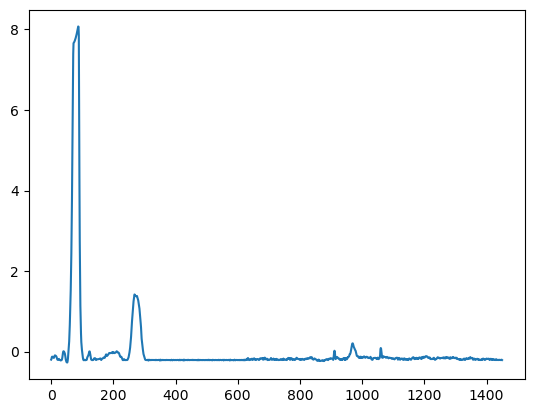

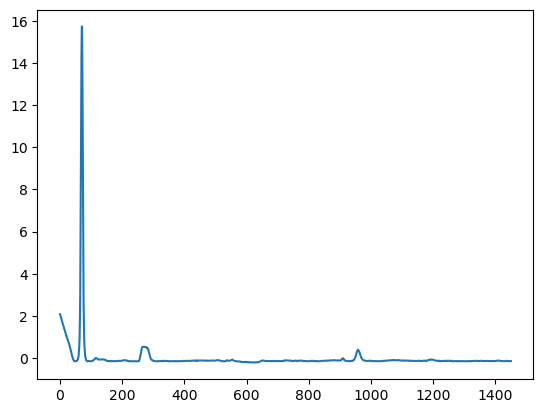

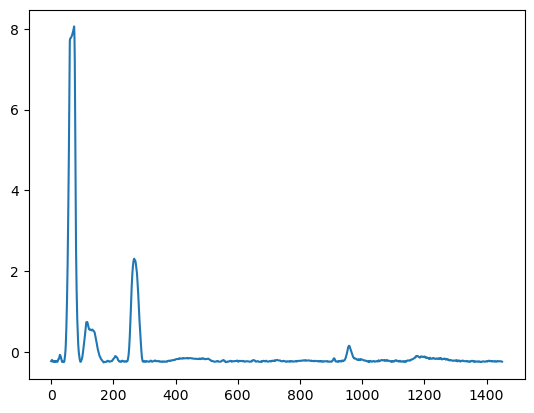

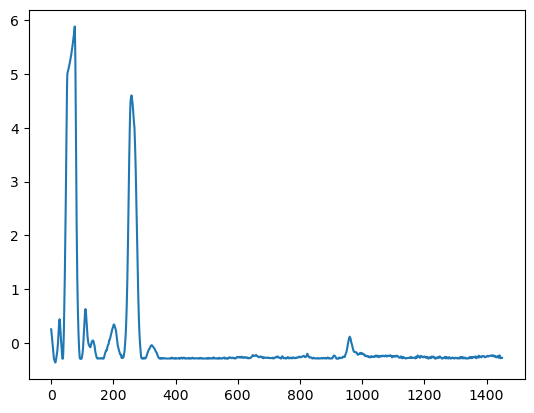

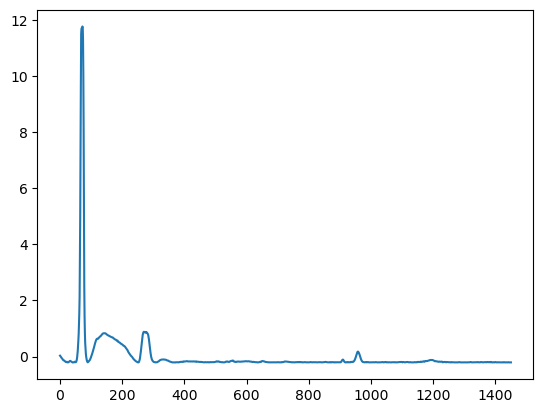

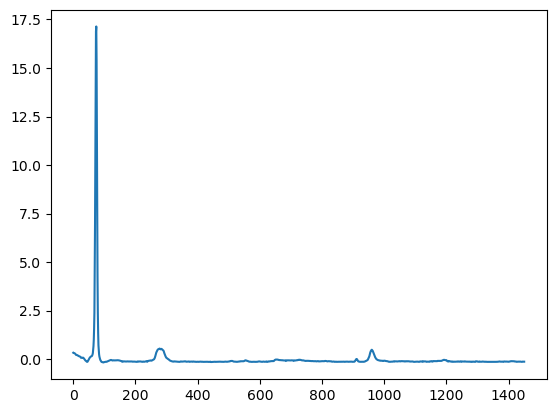

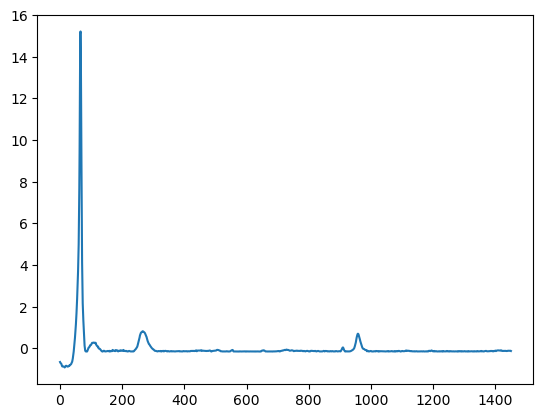

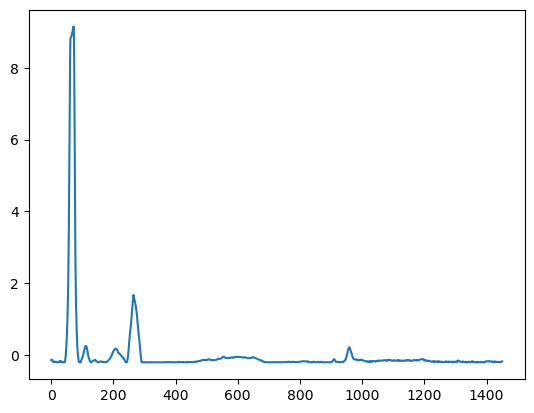

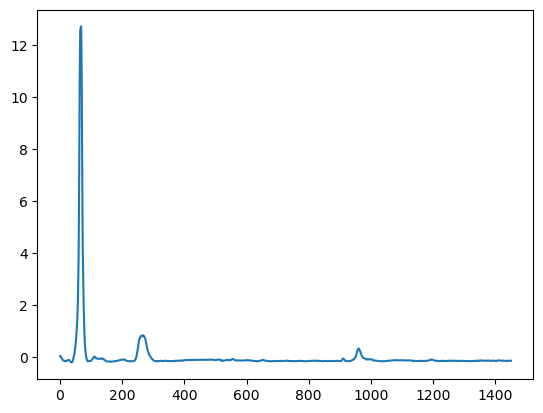

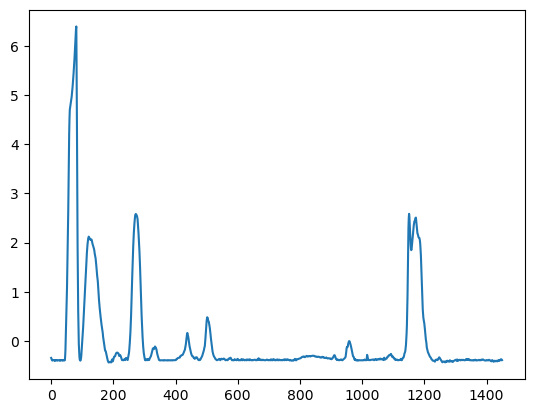

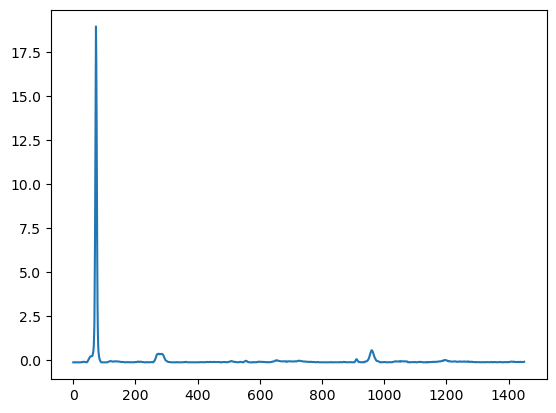

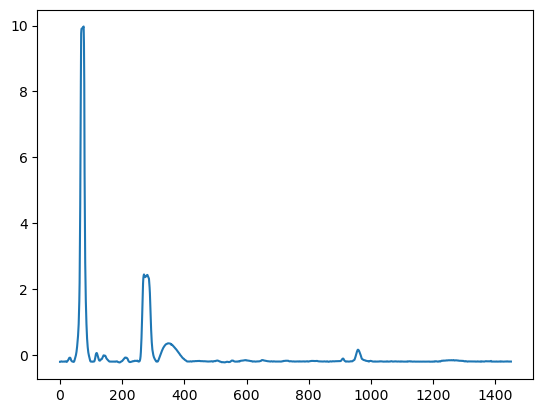

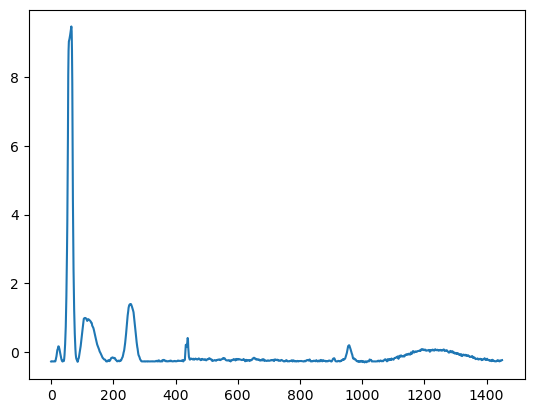

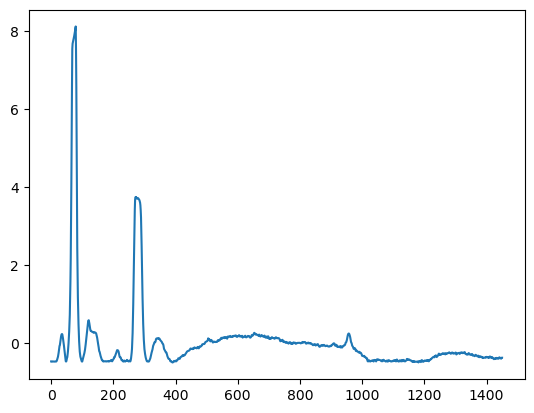

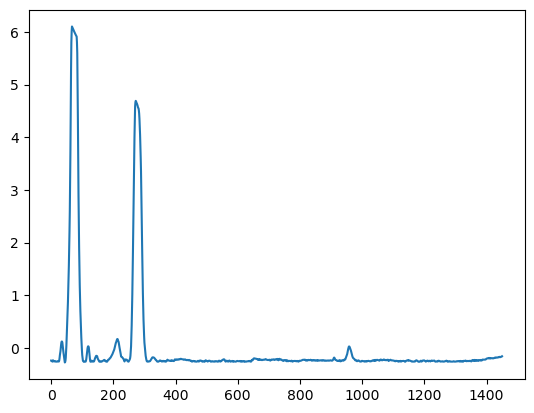

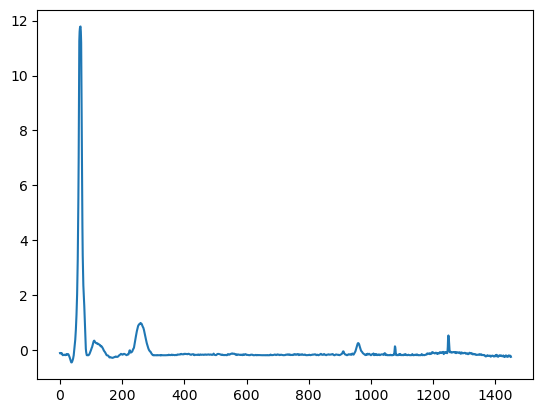

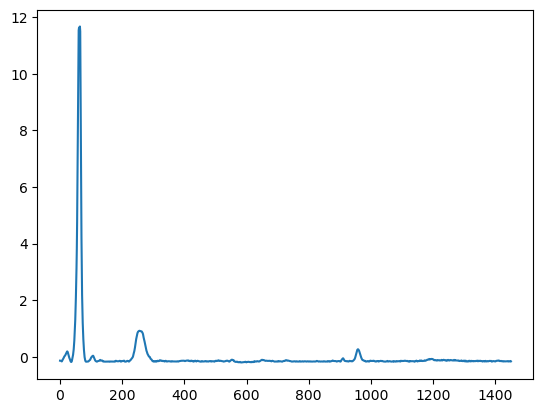

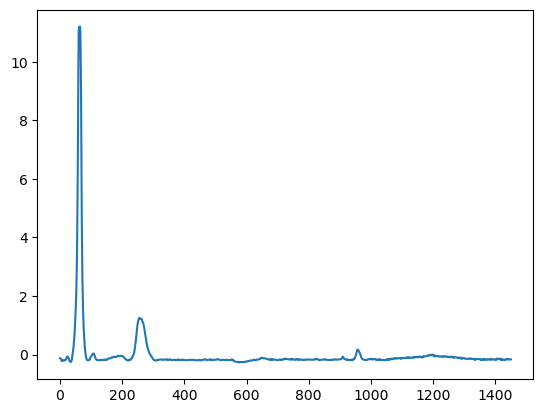

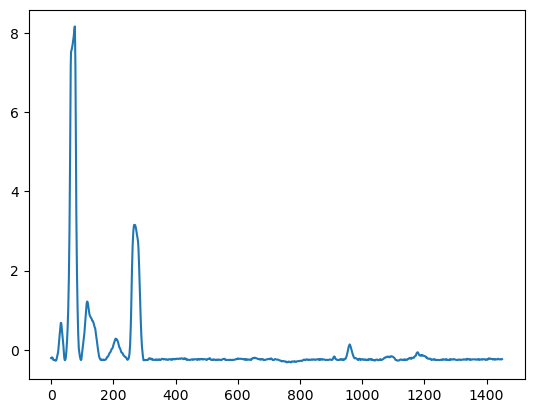

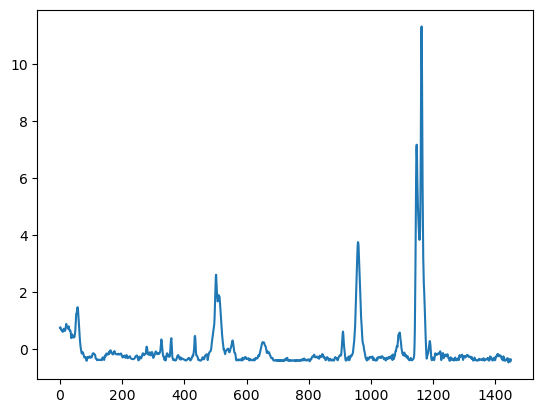

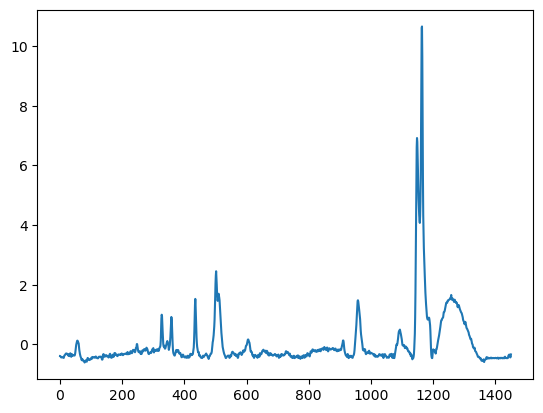

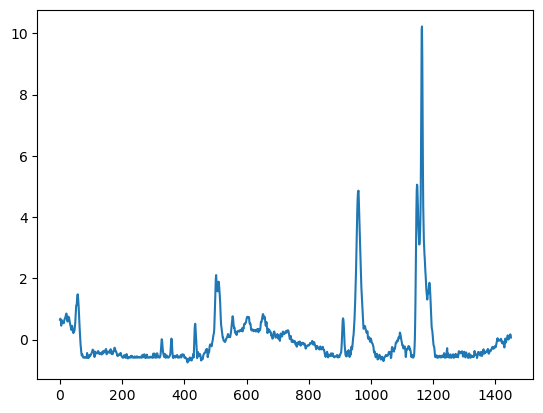

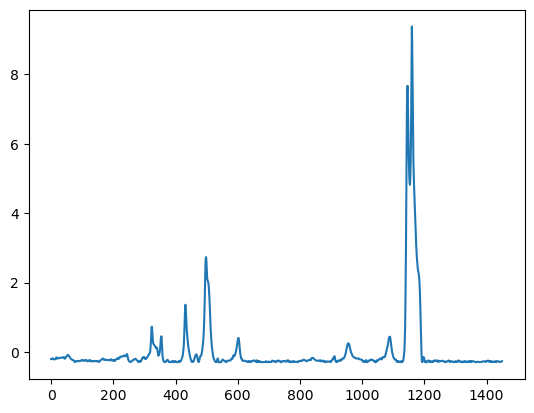

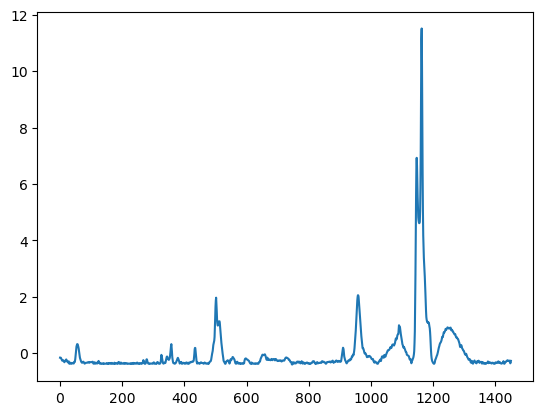

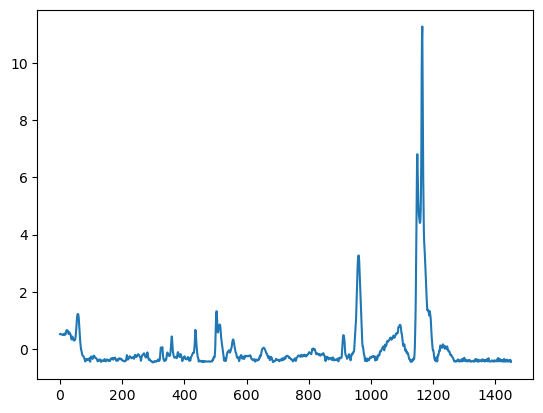

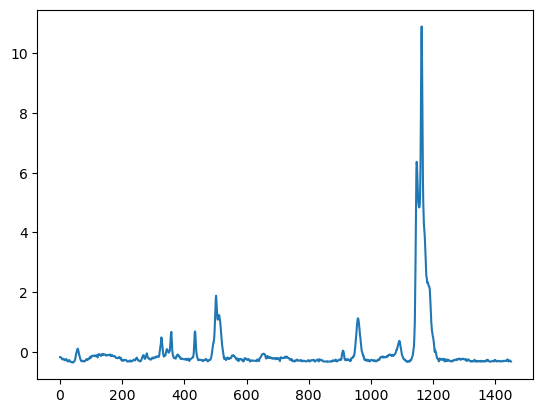

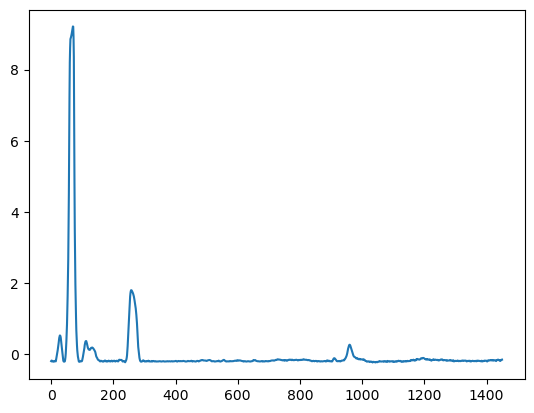

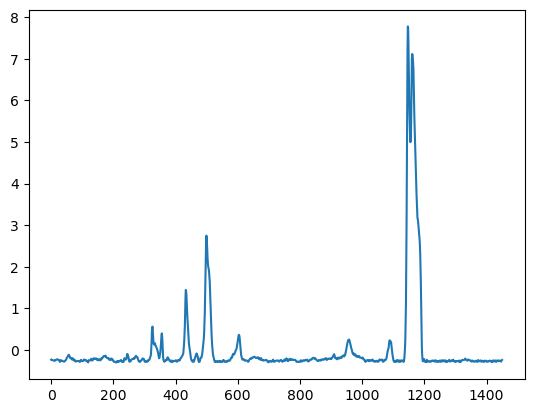

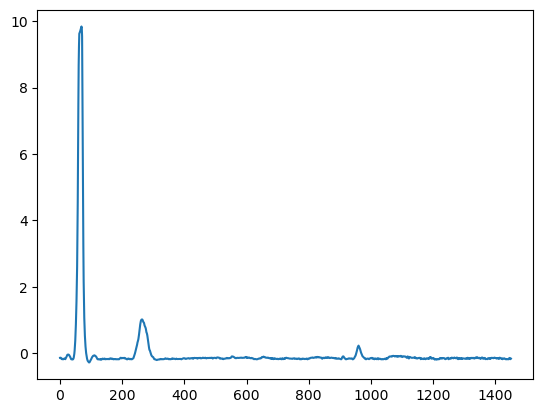

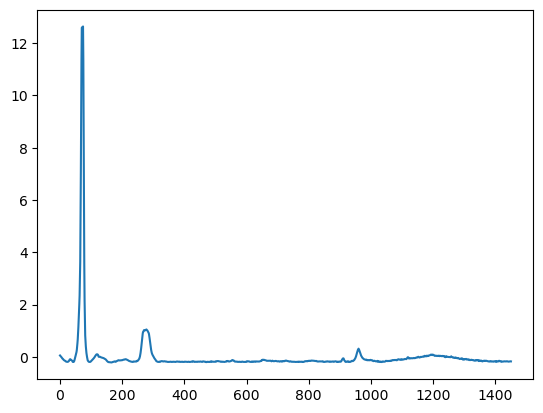

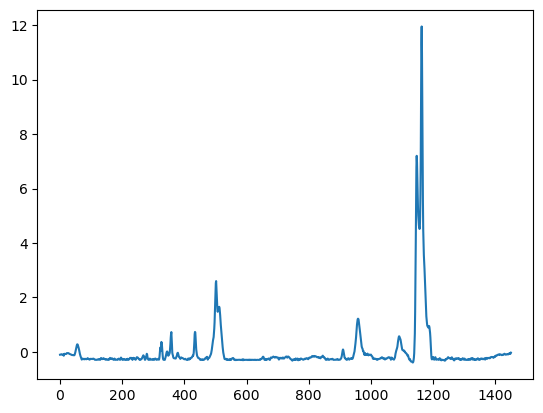

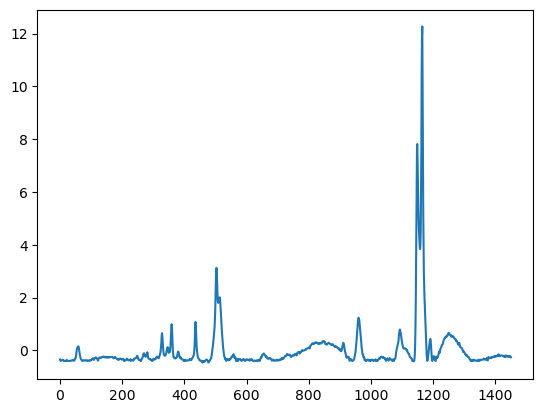

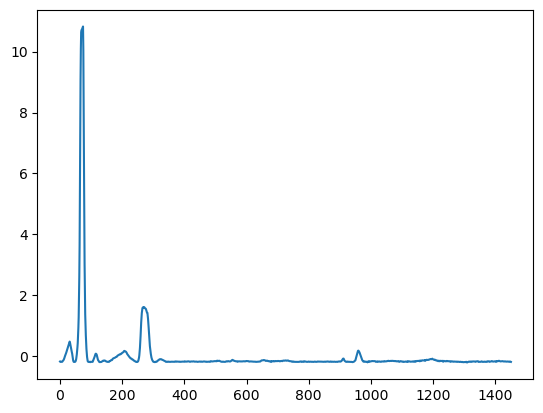

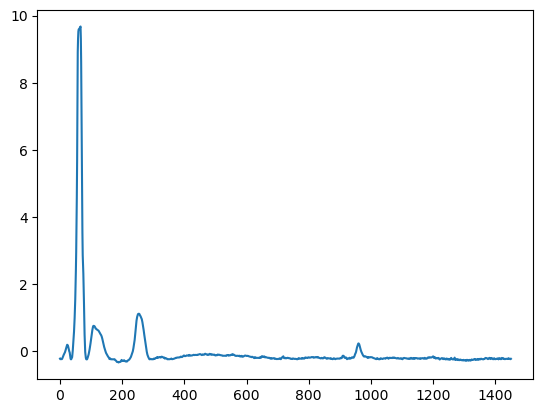

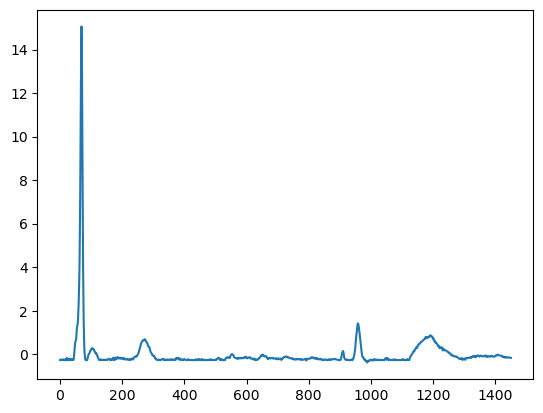

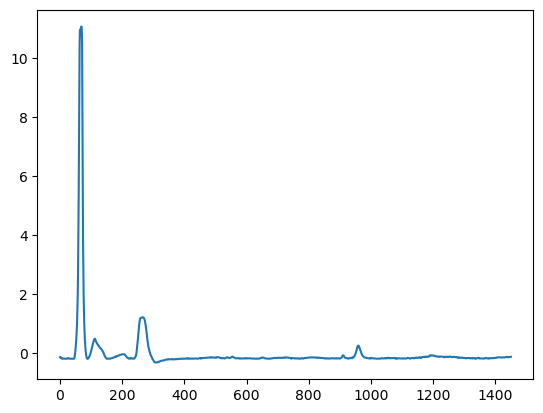

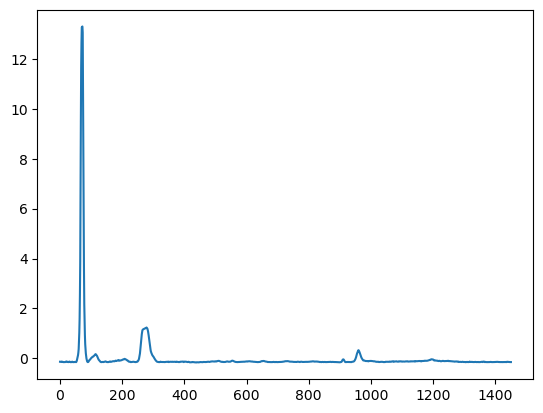

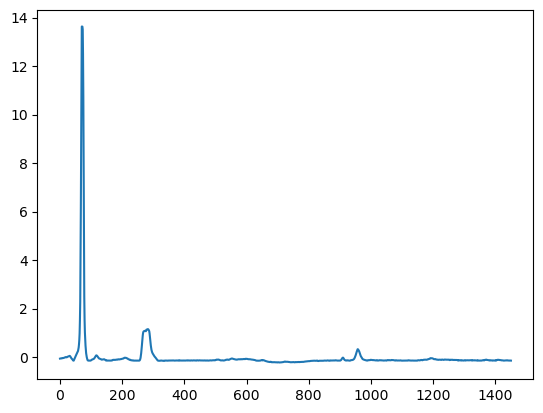

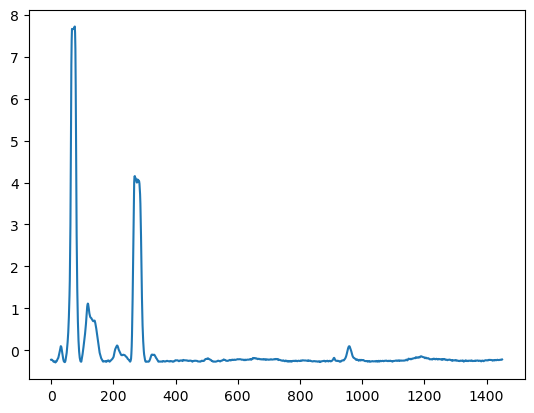

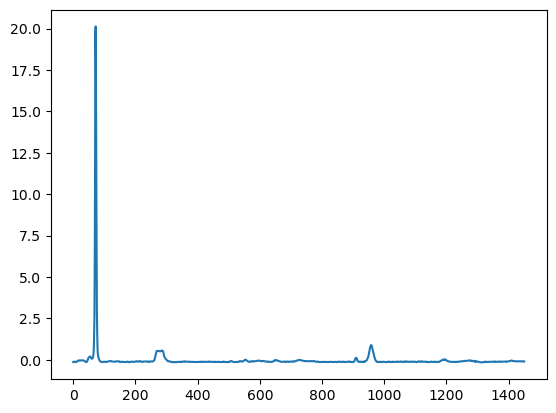

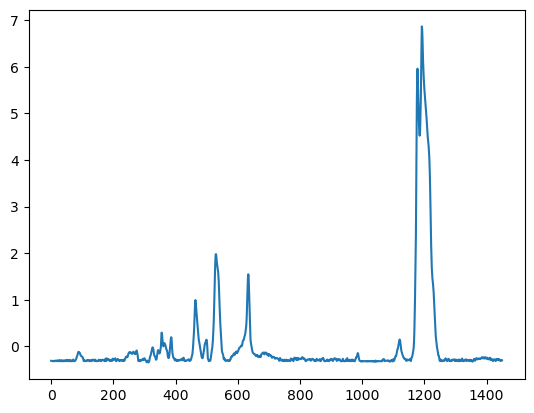

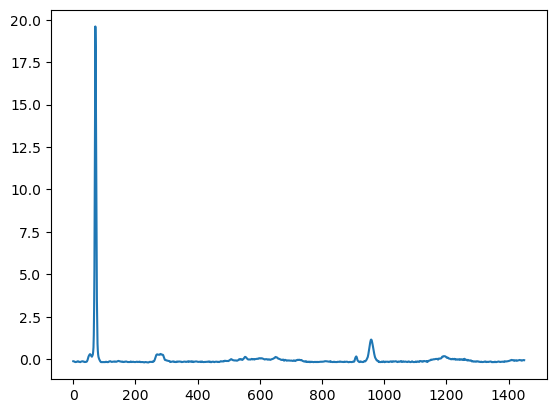

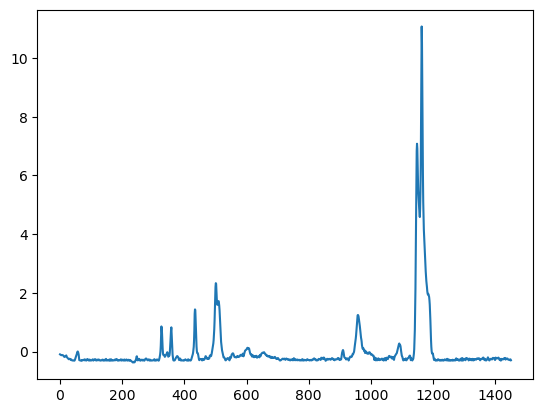

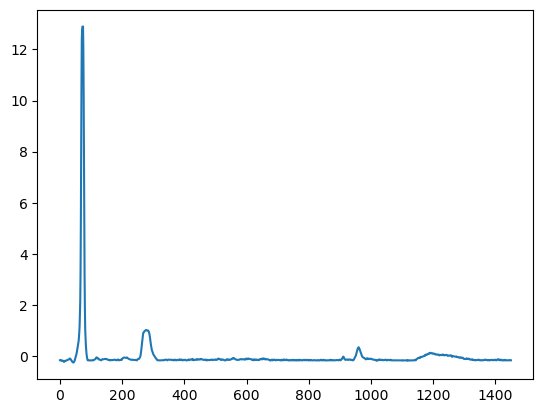

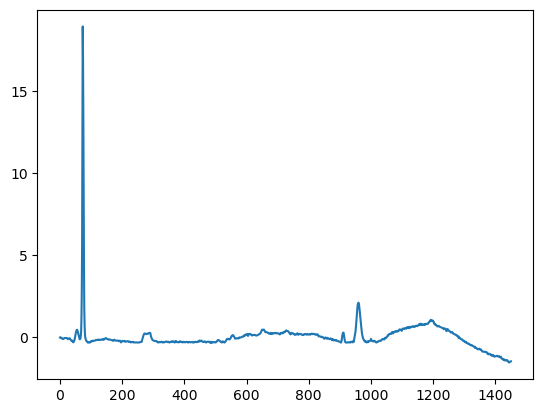

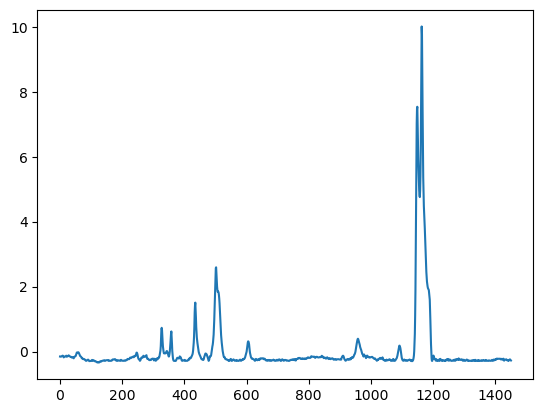

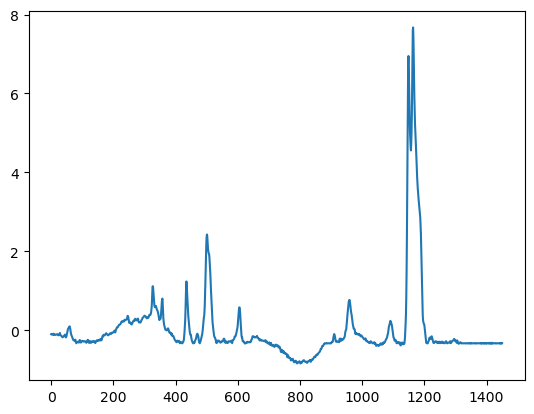

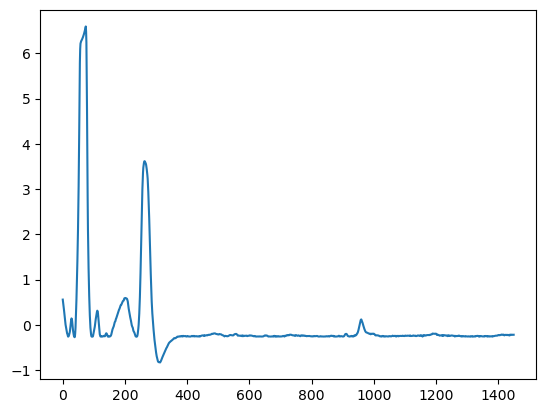

KeyboardInterrupt: 

In [35]:
for i in np.argsort(missing_int_raman)[::-1]:
    plt.plot(x_test_raman[i,:])
    plt.show()

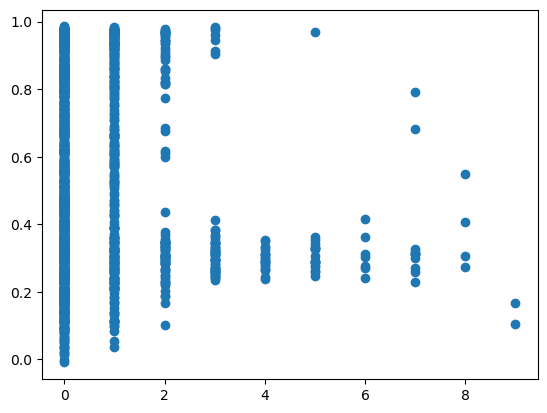

In [36]:
_ = plt.scatter(missing_int_raman[missing_int_raman<10], pred_hqi_raman[missing_int_raman<10])

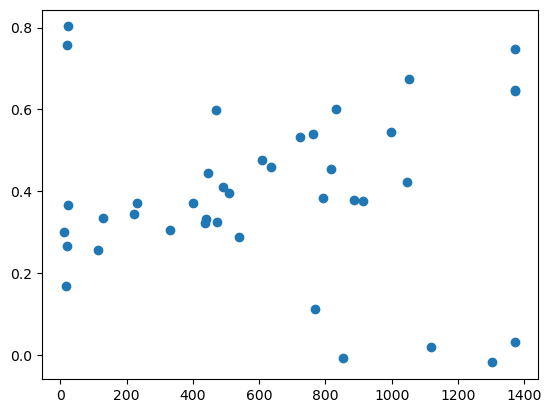

In [37]:
_ = plt.scatter(missing_int_raman[missing_int_raman>10], pred_hqi_raman[missing_int_raman>10])

In [38]:
pd.DataFrame({'missing_n':missing_int_raman, 'n':1}).groupby('missing_n').sum()

,n
missing_n,
0,919
1,311
2,95
3,57
4,21
5,18
6,7
7,11
8,4


In [39]:
spectra_data_raman_particle = spectra_data_raman.loc[:,['map_x', 'map_y', 'id']].merge(particles_data, how='left', left_on='id',right_on='id_x')
spectra_data_raman_particle['hqi_slopp'] = np.array(pred_df_raman['hqi_slopp'])
spectra_data_raman_particle

,map_x,map_y,id,id_x,size,area,perimeter,circularity,hqi_slopp
0,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01_0514_1,1.374926,1.330287,5.386343,0.575968,0.166782
1,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01_0514_2,3.169136,6.776416,11.286760,0.668194,0.037342
2,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01_0514_3,1.793934,2.482638,6.046356,0.853035,0.268144
3,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01_0514_4,0.936898,0.696918,3.310439,0.798824,0.225375
4,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01_0514_5,1.615575,2.111937,5.716350,0.811866,0.528799
...,...,...,...,...,...,...,...,...,...
1481,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02_0328_28,1.796098,2.247508,8.490387,0.391640,0.934955
1482,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02_0328_29,1.743342,2.414853,6.154179,0.800924,0.677885
1483,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02_0328_30,0.515590,0.211829,1.831388,0.793352,0.383779
1484,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02_0328_31,1.621519,2.048388,5.662438,0.802502,0.978346


In [40]:
np.mean(spectra_data_raman_particle['hqi_slopp'] > .7)

0.31292059219380886

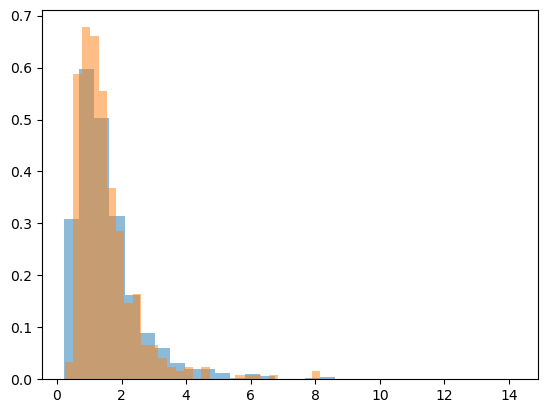

In [41]:
_ = plt.hist(spectra_data_raman_particle['size'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_raman_particle.query('hqi_slopp > .7')['size'], bins=30, density=True, alpha=.5)

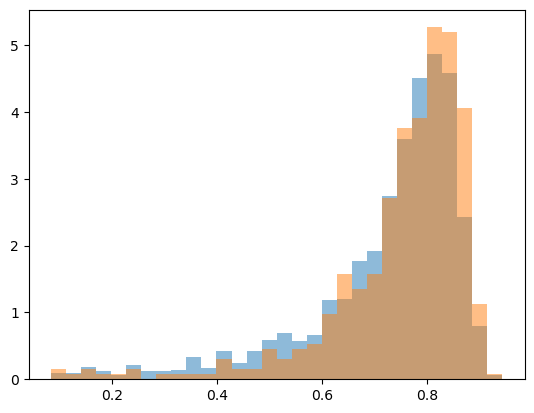

In [42]:
_ = plt.hist(spectra_data_raman_particle['circularity'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_raman_particle.query('hqi_slopp > .7')['circularity'], bins=30, density=True, alpha=.5)

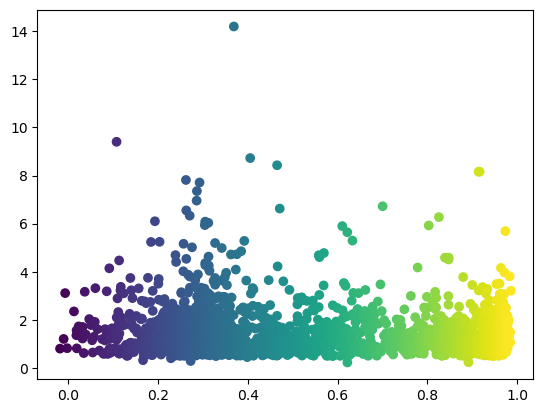

In [43]:
plt.scatter(spectra_data_raman_particle.loc[:,['size','hqi_slopp']].sort_values('hqi_slopp')['hqi_slopp'],
            spectra_data_raman_particle.loc[:,['size','hqi_slopp']].sort_values('hqi_slopp')['size'], 
            c=spectra_data_raman_particle.loc[:,['size','hqi_slopp']].sort_values('hqi_slopp')['hqi_slopp'])

# Compar IR vs Raman

In [150]:
threshold = 0.7
idx_cm= np.logical_and(pred_hqi>threshold, pred_hqi_raman>threshold)
(pred_polymers.to_numpy() == pred_polymers_raman.to_numpy())[idx_cm].mean(), idx_cm.mean()

(0.783375314861461, 0.2671601615074024)

In [151]:
labels = np.unique(np.concatenate([pred_polymers[idx_cm].to_numpy(), pred_polymers_raman[idx_cm].to_numpy()]))

In [152]:
confusion_matrix(pred_polymers[idx_cm], pred_polymers_raman[idx_cm], labels=labels)

array([[  0,   0,   0,   0,   0,   0],
       [  1, 303,   0,   0,  12,   0],
       [  0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0],
       [  0,  53,   1,   1,   8,   1],
       [  0,  15,   0,   0,   2,   0]])

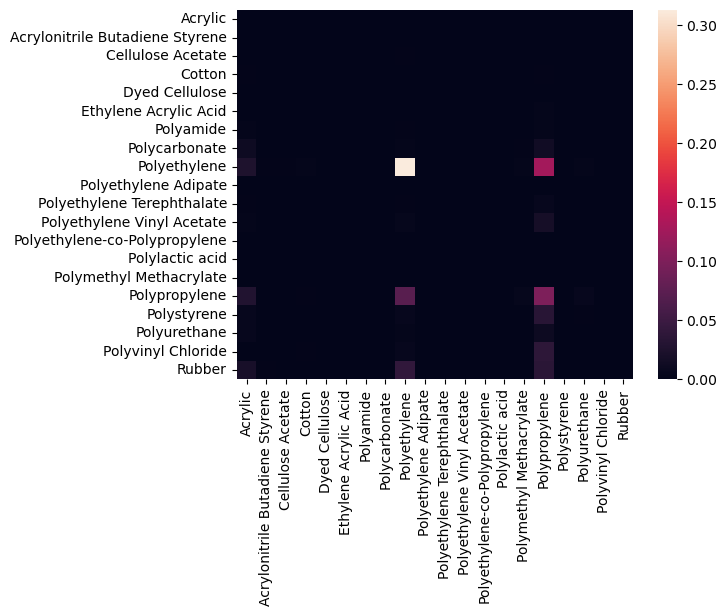

In [149]:
conf_mat = confusion_matrix(pred_polymers[idx_cm], pred_polymers_raman[idx_cm], labels=labels)
#conf_mat = conf_mat/ conf_mat.sum(1)[:,None]
conf_mat = conf_mat/ conf_mat.sum()
#np.nansum(conf_mat[0,:])
#conf_mat[np.isnan(conf_mat)] = 0
#np.sort(conf_mat.flatten())[::-1]

_ = sns.heatmap(conf_mat, xticklabels=labels, yticklabels=labels)

# Rebecca IR

In [116]:
rebecca_data_ir

,948.9097900390625,950.8388061523438,952.767822265625,954.69677734375,956.6257934570312,958.5548095703125,960.4838256835938,962.4127807617188,964.341796875,966.2708129882812,...,2989.791748046875,2991.720703125,2993.64990234375,2995.578857421875,2997.5078125,2999.436767578125,3001.36572265625,map_x,map_y,id
0,0.047558,-0.858840,-0.314445,0.163499,0.262745,-0.367476,-0.027330,-0.378350,-0.798459,-1.018779,...,-0.419044,-1.092907,-2.478409,-2.306997,-0.955491,-2.188334,-2.983691,0,0,sucrose
1,2.553946,1.308952,-0.202485,0.263647,0.355392,-0.613322,-1.221301,-1.135373,-0.907038,-0.269856,...,-0.532888,0.458194,-1.029877,1.288129,1.385426,3.739439,2.823250,0,0,sucrose
2,-0.490438,-0.996198,-1.196329,-0.606503,-0.992912,-0.931925,-0.805939,-1.087360,-0.908954,-0.766301,...,-1.602121,-1.313722,-3.085726,-3.774508,-3.519258,-4.509090,-1.814453,0,0,sucrose
3,-3.691749,-4.953676,-2.656383,0.911441,2.047704,-0.364525,-2.325906,-1.291989,-0.028666,0.663747,...,-1.959055,2.106364,3.156213,5.690798,-0.925729,-6.983326,-9.352137,0,0,sucrose
4,-5.859167,-5.952616,-4.007246,-3.467411,-3.751552,-3.011642,-2.046139,-1.038378,-0.863066,-0.632033,...,-4.242046,-6.209875,-0.035960,-0.229471,-5.353487,-8.769722,-8.964068,0,0,sucrose
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,-5.501368,-0.731867,-0.177870,1.631273,1.277006,-0.030214,-1.289151,-0.571985,0.246478,0.369729,...,-6.726546,-7.156198,-3.977822,-4.158401,-4.595611,-13.014235,-8.531109,0,0,PP
521,-1.505513,-0.951109,-1.146239,-0.818072,-0.425984,-0.550227,-0.906025,-1.096827,-1.026230,-0.812767,...,-2.035541,-2.834967,-2.177698,-1.911629,-3.101400,-3.542112,-2.078771,0,0,PP
522,-1.193376,-0.839387,-0.916520,-0.691928,-0.512431,-0.134070,-0.026930,-0.464041,-0.254140,-0.291876,...,-0.275816,-0.848965,-1.251804,-1.878466,-2.252761,-2.282949,-2.407313,0,0,PP
523,-4.960909,-3.982604,-1.582585,-1.550157,-2.910924,-2.709201,-2.636106,-2.395657,-1.345772,-1.220404,...,-0.561427,-3.150743,-3.617692,-1.793774,0.045828,-0.385556,-5.184566,0,0,PP


In [171]:
rebecca_data_ir = pd.read_csv('gloves_contamination/data_ir_rebecca.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-3])) + list(rebecca_data_ir.columns[-3:])

wn_rb = np.array(rebecca_data_ir.columns[:-3])

idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                       np.logical_and(wn_rb > 2720, wn_rb < 2950) #2993.64990234375-10
                      ) ) + [False]*3

x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV') #MINMAX
#x_train_ir = -x_train_ir
x_train_ir_diff = np.diff(x_train_ir)
x_train_ir_diff = norm_spect_pivot(x_train_ir_diff, norm_type='SNV')
y_train_ir = rebecca_data_ir.iloc[:,-1]


NH2SO4


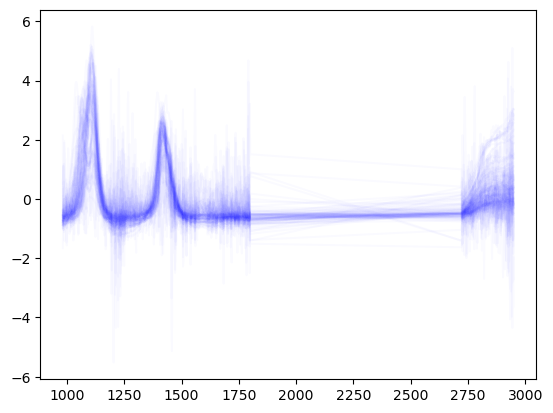

NaNO3


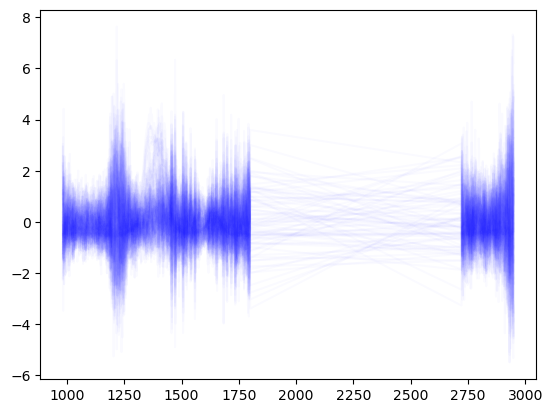

PE


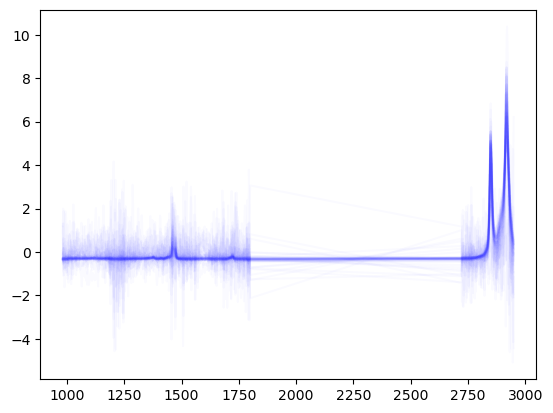

PP


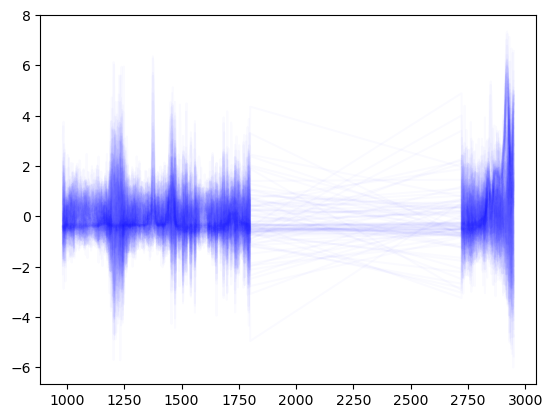

PSL


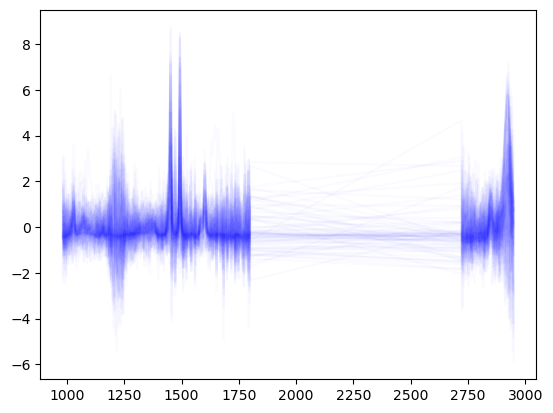

sucrose


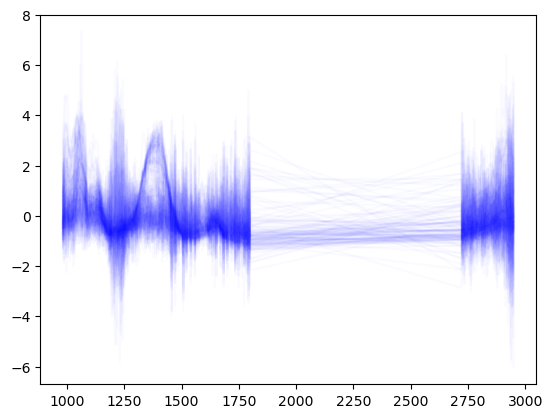

In [172]:
for label in np.unique(y_train_ir):
    print(label)
    _ = plt.plot(wn_rb[idx_rb[:-3]],
             x_train_ir[y_train_ir == label,:].T, c='b', alpha=.02)
    _ = plt.show()

In [182]:
pred_ = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers).reset_index(drop=True)
pred_df.columns = ['polymer_reb_ir']
pred_df['background_mean'] = spectra_data_ir['background']
pred_df['hqi_reb_ir'] = pred_hqi
pred_df.reset_index().query('hqi_reb_ir>.7').groupby('polymer_reb_ir').count()

,index,background_mean,hqi_reb_ir
polymer_reb_ir,,,
NH2SO4,6,6,6
NaNO3,4,4,4
PE,539,539,539
PP,94,94,94
PSL,89,89,89
sucrose,52,52,52


In [184]:
pred_df.query('polymer_reb_ir=="PE"').groupby('background_mean').mean()

,hqi_reb_ir
background_mean,
background,0.788906
no_background,0.944809


In [185]:
pred_df.query('polymer_reb_ir=="PE"').groupby('background_mean').std()

,hqi_reb_ir
background_mean,
background,0.227252
no_background,0.086365


In [134]:
spectra_data_ir['polymer_reb_ir'] = pred_df['polymer_reb_ir']
spectra_data_ir['hqi_reb_ir'] = pred_df['hqi_reb_ir']

In [139]:
spectra_data_ir

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2947.353759765625,2949.28271484375,map_x,map_y,id,background,polymer_flopp,hqi_flopp,polymer_reb_ir,hqi_reb_ir
0,0.872796,0.796779,-0.611306,-2.278622,-1.746481,-0.370841,0.778302,0.997491,0.094961,-0.064373,...,0.674207,-0.859183,15624.450195,1545.449951,MF_L_01_0514_1,background,Polystyrene,0.169966,PSL,0.304577
1,-1.434505,-1.497058,-1.515828,-0.927052,-0.611952,0.703137,0.247949,0.281065,0.596256,1.011994,...,3.062379,1.459214,15623.299805,1550.750000,MF_L_01_0514_2,background,Polycarbonate,0.226918,sucrose,0.316540
2,-0.737597,-0.713237,-0.905982,-0.591487,-0.466991,-0.367976,1.594194,2.186429,0.696239,-0.075104,...,-1.460040,-1.293480,15617.500000,1564.949951,MF_L_01_0514_3,background,Polystyrene,0.070586,sucrose,0.213590
3,-2.124903,-0.445256,1.207637,0.106094,0.010575,0.896289,0.727375,-0.501711,-1.311360,-0.878556,...,1.008936,-0.186797,15620.650391,1565.050049,MF_L_01_0514_4,background,Polypropylene,0.199337,PE,0.294339
4,-0.324747,0.132726,0.309409,1.550920,-0.190660,-0.960115,-0.619112,-0.322470,-0.299099,-0.761152,...,1.382513,3.019189,15616.150391,1570.400024,MF_L_01_0514_5,background,Polyethylene Vinyl Acetate,0.250529,PP,0.327056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,-0.262721,-0.276170,-0.284734,-0.286635,-0.275587,-0.286407,-0.297969,-0.295624,-0.294374,-0.298505,...,0.509604,0.532265,-4543.500000,-1759.750000,KC_N_02_0328_28,no_background,Polyethylene,0.942226,PE,0.975938
1482,-0.288857,-0.285425,-0.268086,-0.264488,-0.279130,-0.287197,-0.286700,-0.283724,-0.281515,-0.280514,...,0.209320,0.153394,-4501.899902,-1758.099976,KC_N_02_0328_29,no_background,Polyethylene,0.775349,PSL,0.919746
1483,-2.289574,-1.723470,-1.599757,-1.588312,-1.486721,-0.954253,-0.713513,-0.372474,-0.098228,0.336216,...,-4.747120,-3.493588,-4510.850098,-1747.099976,KC_N_02_0328_30,background,Polyethylene,0.396031,PE,0.537298
1484,-0.411749,-0.411490,-0.412306,-0.412452,-0.411963,-0.411440,-0.411809,-0.412027,-0.412110,-0.412255,...,1.472530,1.570823,-4511.100098,-1743.050049,KC_N_02_0328_31,no_background,Polyethylene,0.894872,PSL,0.966609


(289, 544)


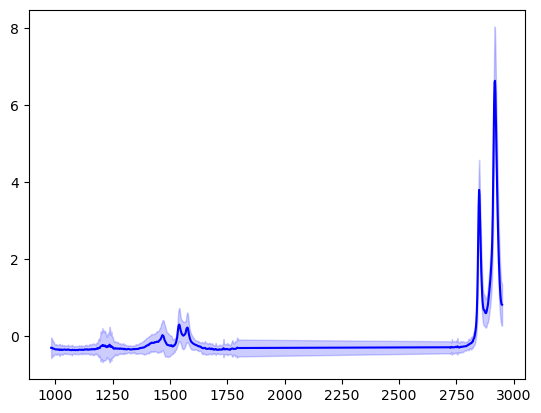

In [140]:
df_PE = spectra_data_ir.query('background != "background" and polymer_reb_ir == "PE" and hqi_reb_ir > .7').loc[:,idx_gl+[False]*4]
mean_PE = np.array(df_PE.mean(0))
std_PE = np.array(df_PE.std(0))

mean_PE = np.float64(mean_PE)
std_PE = np.float64(std_PE)
wn_gl = np.float64(wn_gl)
print(df_PE.shape)

_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE, c='b')

#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE+std_PE)
#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE-std_PE)
    
_ = plt.fill_between(wn_gl[idx_gl[:-4]], mean_PE - std_PE, mean_PE + std_PE, color='b', alpha=.2)


In [160]:
df_PE

,981.702820,983.631775,985.560791,987.489807,989.418823,991.347778,993.276794,995.205811,997.134827,999.063782,...,2931.921875,2933.850830,2935.779785,2937.708740,2939.637695,2941.566895,2943.495850,2945.424805,2947.353760,2949.282715
150,-0.547668,-0.513674,-0.374161,-0.664187,-0.835640,-0.344295,-0.334822,-0.142999,-0.550384,-0.706570,...,-0.537996,0.313352,1.056867,2.230888,2.681514,-0.081626,-0.592833,-0.307541,-0.189386,0.033330
204,-0.680866,0.057670,0.259102,0.356562,0.541767,0.771528,0.547068,-0.032563,-0.552680,-0.420576,...,0.528785,0.458185,0.774411,2.265629,2.384768,1.377353,1.893950,2.743465,1.718285,0.366942
206,-0.989362,-1.299462,-1.844992,-1.332374,-0.561705,-0.391355,-0.250045,0.532634,0.362832,-0.991490,...,1.097720,-0.509563,-1.473920,-1.292918,-0.391007,0.024367,-1.172264,-1.352442,-2.776459,-0.906844
216,-1.877383,-1.877941,-1.446725,-0.116515,1.194917,1.135364,0.673244,-0.162516,-0.573085,-0.525624,...,2.132093,1.281429,0.321478,-1.910046,-0.752769,0.419047,1.622728,1.086097,-0.354000,-1.698796
218,-0.268008,-0.257930,-0.291739,-0.334761,-0.359136,-0.361089,-0.474866,-0.347328,-0.298127,-0.285088,...,1.895601,2.007494,1.447234,0.845479,0.806950,0.453167,0.515234,0.448477,0.336529,0.201703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,-0.367346,-0.356374,-0.596237,-0.491095,-0.462404,-0.458336,-0.384509,-0.445827,-0.570800,-0.513413,...,1.710157,1.180468,1.038967,0.810934,0.909529,0.789557,0.671130,0.747204,0.321550,-0.435246
1459,-0.161006,-0.325221,-0.493159,-0.704359,-0.459173,0.119569,0.557073,0.301044,-0.123081,-0.234632,...,1.169683,0.565239,0.392920,0.504044,0.318813,0.468726,-0.427110,-0.810977,-0.020494,-0.227957
1465,-0.442799,-0.449552,-0.225256,-0.370421,-0.305143,-0.273330,-0.321109,-0.266259,-0.323380,-0.370612,...,1.995286,1.393103,0.936804,0.625584,0.460850,0.314152,0.300879,0.372806,0.267914,0.089763
1466,-0.456447,0.213647,0.215046,-0.357525,-0.793040,-1.138810,-0.457294,-0.074801,0.262309,0.102279,...,1.347408,1.682730,2.351256,1.353718,0.410393,-0.580632,-0.863658,-1.065952,0.067859,1.385670


(250, 544)


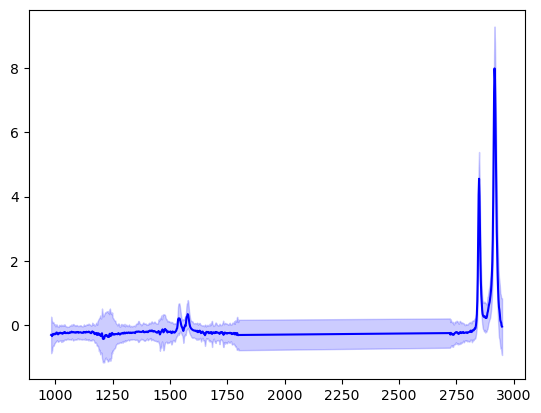

In [159]:
df_PE = spectra_data_ir.query('background == "background" and polymer_reb_ir == "PE" and hqi_reb_ir > .7').loc[:,idx_gl+[False]*6]
mean_PE = np.array(df_PE.mean(0))
std_PE = np.array(df_PE.std(0))

mean_PE = np.float64(mean_PE)
std_PE = np.float64(std_PE)
wn_gl = np.float64(wn_gl)
print(df_PE.shape)

_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE, c='b')

#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE+std_PE)
#_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE-std_PE)
    
_ = plt.fill_between(wn_gl[idx_gl[:-4]], mean_PE - std_PE, mean_PE + std_PE, color='b', alpha=.2)


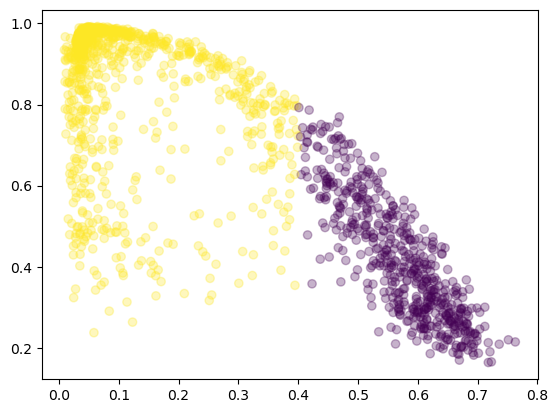

In [163]:
abs_var = np.abs(np.diff(x_test_ir,1)).mean(1) 
plt.scatter(abs_var, pred_hqi, c=abs_var < .4, alpha=.3)

In [164]:
spectra_data_ir_particle = spectra_data_ir.loc[:,['map_x', 'map_y', 'id']].merge(particles_data, how='left', left_on='id',right_on='id_x')
spectra_data_ir_particle['hqi_reb_ir'] = np.array(pred_df['hqi_reb_ir'])
spectra_data_ir_particle

,map_x,map_y,id,id_x,size,area,perimeter,circularity,hqi_reb_ir
0,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01_0514_1,1.374926,1.330287,5.386343,0.575968,0.540581
1,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01_0514_2,3.169136,6.776416,11.286760,0.668194,0.467004
2,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01_0514_3,1.793934,2.482638,6.046356,0.853035,0.206918
3,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01_0514_4,0.936898,0.696918,3.310439,0.798824,0.333157
4,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01_0514_5,1.615575,2.111937,5.716350,0.811866,0.375978
...,...,...,...,...,...,...,...,...,...
1481,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02_0328_28,1.796098,2.247508,8.490387,0.391640,0.972905
1482,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02_0328_29,1.743342,2.414853,6.154179,0.800924,0.919315
1483,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02_0328_30,0.515590,0.211829,1.831388,0.793352,0.570391
1484,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02_0328_31,1.621519,2.048388,5.662438,0.802502,0.950477


In [165]:
np.mean(spectra_data_ir_particle['hqi_reb_ir'] > .7)

0.5289367429340511

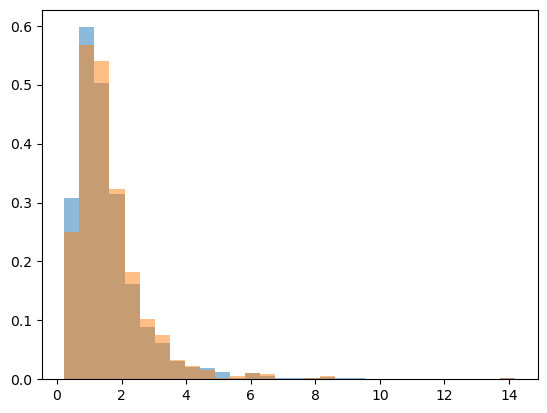

In [166]:
_ = plt.hist(spectra_data_ir_particle['size'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_reb_ir > .7')['size'], bins=30, density=True, alpha=.5)

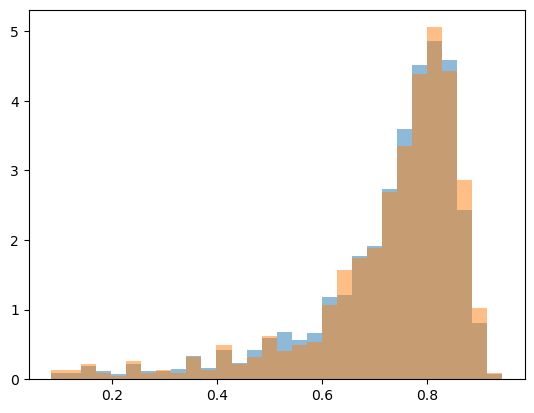

In [167]:
_ = plt.hist(spectra_data_ir_particle['circularity'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_reb_ir > .7')['circularity'], bins=30, density=True, alpha=.5)

# Rebecca Raman

In [173]:
rebecca_data_raman = pd.read_csv('gloves_contamination/data_raman_rebecca.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-3])) + list(rebecca_data_raman.columns[-3:])
rebecca_data_raman

x_train_raman = rebecca_data_raman.iloc[:,idx_gl_r].to_numpy()
x_train_raman = norm_spect_pivot(x_train_raman, norm_type='SNV') #MINMAX
#x_train_raman = -x_train_raman
x_train_raman_diff = np.diff(x_train_raman)
x_train_raman_diff = norm_spect_pivot(x_train_raman_diff, norm_type='SNV')
y_train_raman = rebecca_data_raman.iloc[:,-1]


NH2SO4


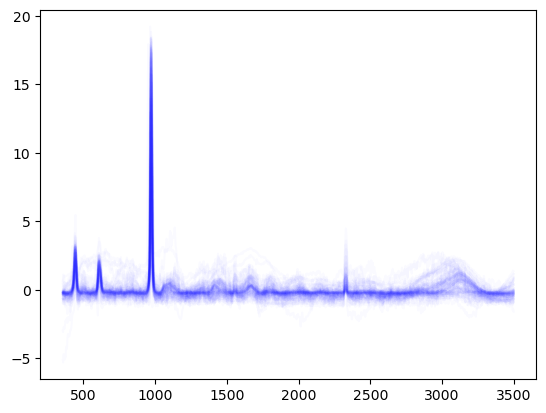

NaNO3


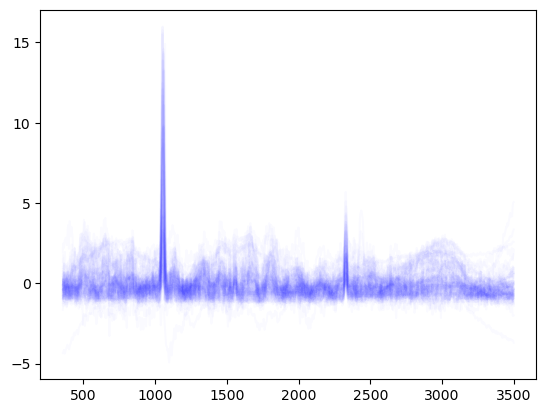

PE


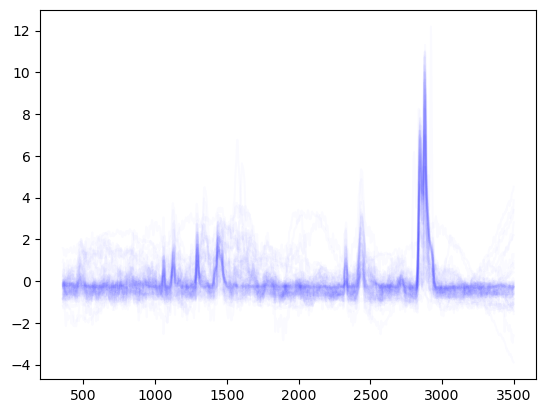

PP


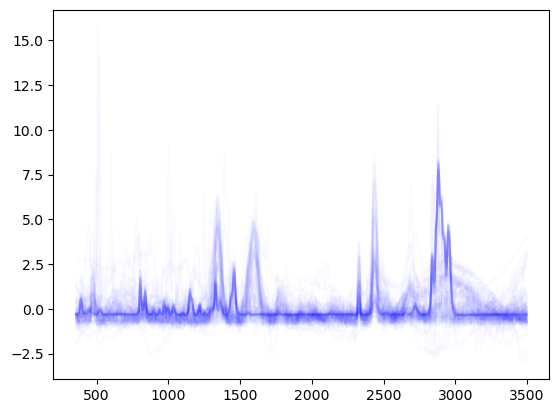

PSL


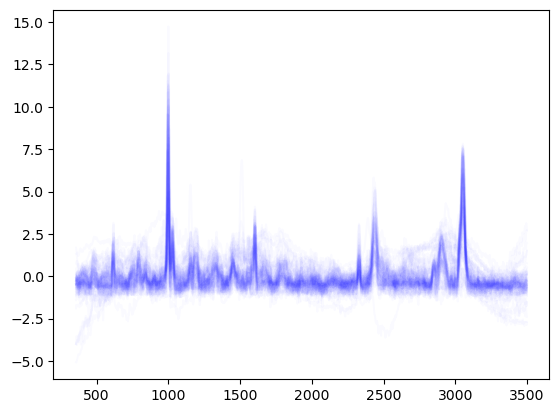

sucrose


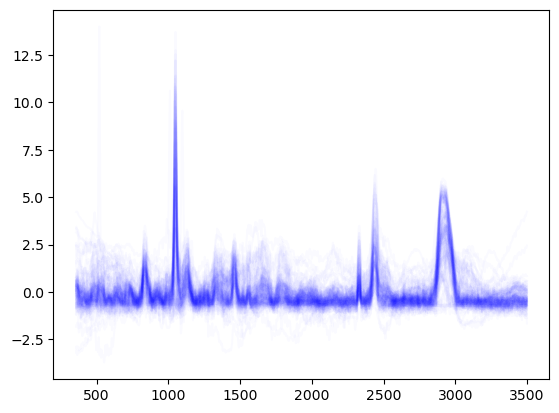

In [174]:
for label in np.unique(y_train_raman):
    print(label)
    _ = plt.plot(wn_gl_r[idx_gl_r[:-3]],
             x_train_raman[y_train_raman == label,:].T, c='b', alpha=.02)
    _ = plt.show()

In [175]:
pred_raman = corr_matching(x_train_raman, y_train_raman, 
                      x_test_raman, r_min=0)
pred_polymers_raman = pred_raman[0]
pred_hqi_raman = pred_raman[1]
pred_df_raman = pd.DataFrame(pred_polymers_raman)
pred_df_raman.columns = ['polymer_reb_raman']
pred_df_raman['hqi_reb_raman'] = pred_hqi_raman
pred_df_raman.reset_index().query('hqi_reb_raman>.7').groupby('polymer_reb_raman').count()

,index,hqi_reb_raman
polymer_reb_raman,,
NaNO3,101,101
PE,69,69
PP,938,938
PSL,23,23
sucrose,177,177


In [179]:
pred_df_raman.reset_index().query('hqi_reb_raman>.7').shape[0]

1308

In [97]:
spectra_data_raman_particle = spectra_data_raman.loc[:,['map_x', 'map_y', 'id']].merge(particles_data, how='left', left_on='id',right_on='id_x')
spectra_data_raman_particle['hqi_reb_raman'] = np.array(pred_df_raman['hqi_reb_raman'])
spectra_data_raman_particle

,map_x,map_y,id,id_x,size,area,perimeter,circularity,hqi_reb_raman
0,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01_0514_1,1.374926,1.330287,5.386343,0.575968,0.796990
1,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01_0514_2,3.169136,6.776416,11.286760,0.668194,0.778232
2,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01_0514_3,1.793934,2.482638,6.046356,0.853035,0.719731
3,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01_0514_4,0.936898,0.696918,3.310439,0.798824,0.851084
4,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01_0514_5,1.615575,2.111937,5.716350,0.811866,0.919952
...,...,...,...,...,...,...,...,...,...
1481,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02_0328_28,1.796098,2.247508,8.490387,0.391640,0.948309
1482,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02_0328_29,1.743342,2.414853,6.154179,0.800924,0.817681
1483,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02_0328_30,0.515590,0.211829,1.831388,0.793352,0.701376
1484,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02_0328_31,1.621519,2.048388,5.662438,0.802502,0.984757


In [101]:
np.mean(spectra_data_raman_particle['hqi_reb_raman'] > .7)

0.8378196500672948

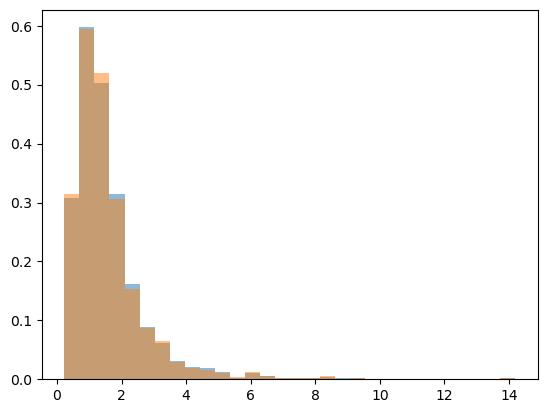

In [99]:
_ = plt.hist(spectra_data_raman_particle['size'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_raman_particle.query('hqi_reb_raman > .7')['size'], bins=30, density=True, alpha=.5)

# Stearate IR

In [142]:
stearates_data_ir = pd.read_csv('gloves_contamination/stearates_preprocessed_ir.csv')
del stearates_data_ir['Unnamed: 0']
stearates_data_ir.columns = list(np.float64(stearates_data_ir.columns[:-3])) + list(stearates_data_ir.columns[-3:])
#stearates_data_ir['material'] = [x[:str.find(x, '_')] if x[(str.find(x, '_')-1):str.find(x, '_')] != '2' else x[:(str.find(x, '_')-3)] for x in stearates_data_ir['id']]
stearates_data_ir['material'] = [x[:str.find(x, '_')] for x in stearates_data_ir['id']]
stearates_data_ir

#stearates_data_ir.groupby('material').count().iloc[:,-1:]

material_list = ['Magnesium Stearate v2',
                 'Calcium Stearate',  
                 'Sodium Stearate',  
                 'Zinc Stearate']

material_sheets =['Mg (v2)', 'Ca', 'Na', 'Zn']

df_stearates_library_list = []

for mat, sheet in zip(material_list, material_sheets):
    df_stearates_library = pd.read_excel('gloves_contamination/MEC_04_010_StearateLibrary_Compilation.xlsx', sheet_name=sheet)
    df_stearates_library = df_stearates_library.iloc[:-2,:2]#['Number']
    df_stearates_library['id'] = [mat+ '_' + str(x) for x in df_stearates_library['Number']]
    df_stearates_library = df_stearates_library.loc[:,['id', 'PTIR']]
    df_stearates_library.columns = ['id', 'in_library']
    df_stearates_library_list.append(df_stearates_library)
    
df_stearates_library = pd.concat(df_stearates_library_list, axis=0)
df_stearates_library = df_stearates_library.query('in_library == 1').reset_index(drop=True)

stearates_data_ir = stearates_data_ir.merge(df_stearates_library)
stearates_data_ir

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2960.856689453125,2962.785888671875,2964.71484375,2966.643798828125,2968.57275390625,map_x,map_y,id,material,in_library
0,-0.675534,-0.674187,-0.676164,-0.677512,-0.676342,-0.673528,-0.673201,-0.675380,-0.676044,-0.675955,...,0.642383,0.493054,0.340156,0.193000,0.063008,11231.849609,214.850006,Magnesium Stearate v2_1,Magnesium Stearate v2,1.0
1,-0.693635,-0.696416,-0.701324,-0.706167,-0.711282,-0.716251,-0.721704,-0.723549,-0.721428,-0.718515,...,1.007395,0.965420,0.888698,0.784624,0.684637,11279.049805,216.600006,Magnesium Stearate v2_2,Magnesium Stearate v2,1.0
2,-0.692647,-0.693295,-0.687913,-0.684325,-0.681512,-0.679313,-0.680552,-0.678067,-0.673682,-0.669751,...,0.301285,0.210615,0.113115,0.000349,-0.111578,11255.250000,216.600006,Magnesium Stearate v2_3,Magnesium Stearate v2,1.0
3,-0.940120,-0.942183,-0.938993,-0.929239,-0.914637,-0.900830,-0.893118,-0.891615,-0.896755,-0.906499,...,0.022649,-0.085364,-0.159528,-0.184049,-0.214074,11216.599609,218.699997,Magnesium Stearate v2_4,Magnesium Stearate v2,1.0
4,-0.632855,-0.637773,-0.641436,-0.643244,-0.635807,-0.625978,-0.617085,-0.608624,-0.596049,-0.578634,...,-0.287346,-0.372035,-0.446433,-0.514453,-0.582863,11348.250000,254.100006,Magnesium Stearate v2_5,Magnesium Stearate v2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,-0.598982,-0.601600,-0.608833,-0.607913,-0.598026,-0.597362,-0.591982,-0.588038,-0.591854,-0.598374,...,-0.327372,-0.350094,-0.408934,-0.451611,-0.461317,10437.250000,-1466.050049,Zinc Stearate_107,Zinc Stearate,1.0
312,-0.692782,-0.702264,-0.692153,-0.703968,-0.695667,-0.691210,-0.692771,-0.696071,-0.697907,-0.699064,...,-0.086340,-0.220806,-0.277223,-0.306242,-0.403612,10423.900391,-1464.800049,Zinc Stearate_108,Zinc Stearate,1.0
313,-0.658094,-0.668548,-0.670447,-0.664076,-0.651426,-0.648725,-0.645287,-0.638012,-0.635143,-0.633217,...,0.589333,0.453168,0.333181,0.190004,0.034273,10464.000000,-1458.449951,Zinc Stearate_109,Zinc Stearate,1.0
314,-0.746370,-0.746520,-0.747310,-0.748197,-0.749398,-0.750353,-0.751858,-0.753229,-0.753672,-0.753272,...,1.679791,1.547962,1.393496,1.223780,1.035223,10499.500000,-1452.949951,Zinc Stearate_110,Zinc Stearate,1.0


In [186]:
wn_st = np.array(stearates_data_ir.columns[:-5])

idx_st = list(np.logical_or(np.logical_and(wn_st > 980, wn_st < 1800),
                       np.logical_and(wn_st > 2720, wn_st < 2950) #2993.64990234375-10
                      ) ) + [False]*5


x_train_ir = stearates_data_ir.iloc[:,idx_st].to_numpy()
x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV') #MINMAX
#x_train_ir = -x_train_ir
x_train_ir_diff = np.diff(x_train_ir)
x_train_ir_diff = norm_spect_pivot(x_train_ir_diff, norm_type='SNV')
y_train_ir = stearates_data_ir.iloc[:,-2]


Calcium Stearate


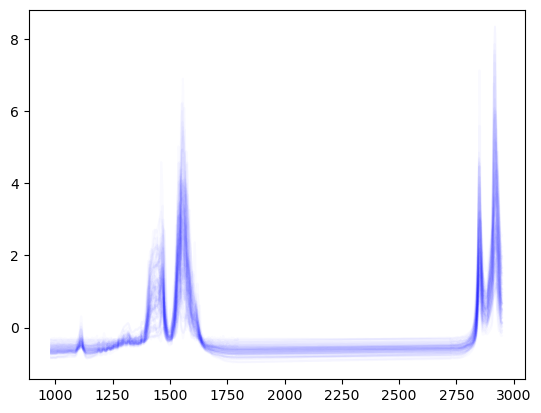

Magnesium Stearate v2


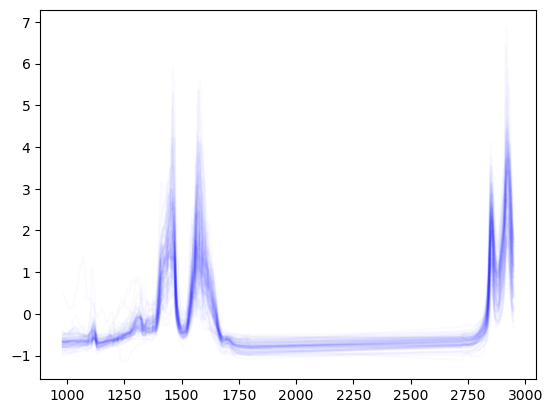

Sodium Stearate


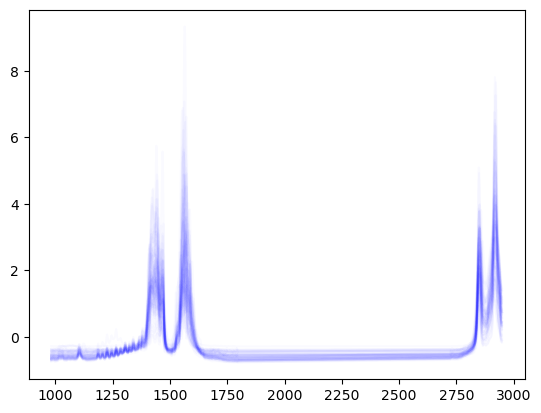

Zinc Stearate


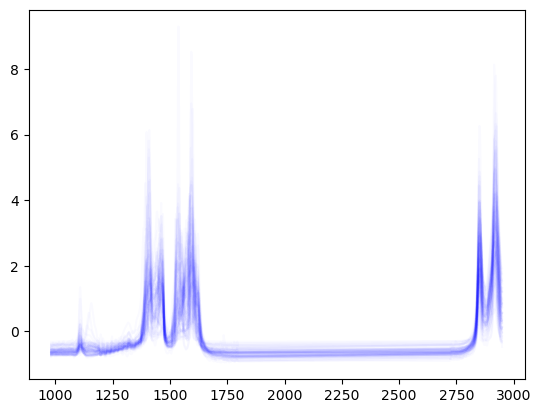

In [144]:
for label in np.unique(y_train_ir):
    print(label)
    _ = plt.plot(wn_st[idx_st[:-5]],
             x_train_ir[y_train_ir == label,:].T, c='b', alpha=.02)
    _ = plt.show()

In [187]:
pred_ir = corr_matching(x_train_ir, y_train_ir, 
                      x_test_ir, r_min=0)
pred_polymers_ir = pred_ir[0]
pred_hqi_ir = pred_ir[1]
pred_df_ir = pd.DataFrame(pred_polymers_ir)
pred_df_ir.columns = ['polymer_stearates_ir']
pred_df_ir['hqi_stearates_ir'] = pred_hqi_ir
pred_df_ir = pred_df_ir.reset_index(drop=True) 

pred_df_ir['background'] = spectra_data_ir['background']

matches_mean_ir = pred_df_ir.reset_index().query('hqi_stearates_ir>.7').query('background!="background"').groupby('polymer_stearates_ir').count()#['hqi_stearates_ir']
matches_mean_ir = matches_mean_ir / matches_mean_ir.sum()

matches_bg_mean_ir = pred_df_ir.reset_index().query('hqi_stearates_ir>.7').query('background=="background"').groupby('polymer_stearates_ir').count()['hqi_stearates_ir']
matches_bg_mean_ir = matches_bg_mean_ir / matches_bg_mean_ir.sum()
matches_bg_mean_ir

#pred_df_ir.reset_index().query('hqi_stearates_ir>.7').groupby('polymer_stearates_ir').count()


polymer_stearates_ir
Calcium Stearate         0.940945
Magnesium Stearate v2    0.011811
Zinc Stearate            0.047244
Name: hqi_stearates_ir, dtype: float64

In [191]:
#pred_df['background_mean'] = spectra_data_ir['background']
pred_df_ir.groupby(['polymer_stearates_ir','background']).mean()

hqi_stearates_ir
polymer_stearates_ir  background                     
Calcium Stearate      background             0.694809
                      no_background          0.911284
Magnesium Stearate v2 background             0.223872
                      no_background          0.404302
Sodium Stearate       background             0.125455
                      no_background          0.361269
Zinc Stearate         background             0.206859
                      no_background          0.897672

In [150]:
spectra_data_ir['polymer_stearates_ir'] = pred_df_ir['polymer_stearates_ir']
spectra_data_ir['hqi_stearates_ir'] = pred_df_ir['hqi_stearates_ir']

(257, 544)
Calcium Stearate


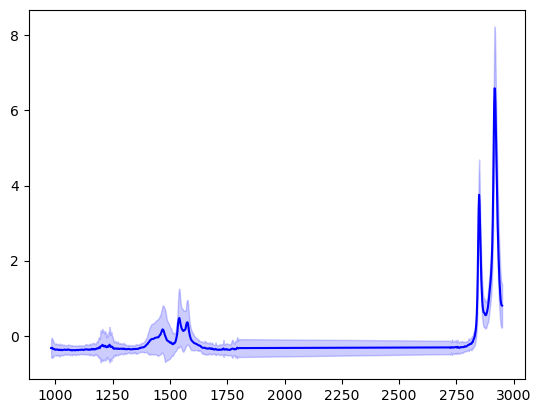

(43, 544)
Magnesium Stearate v2


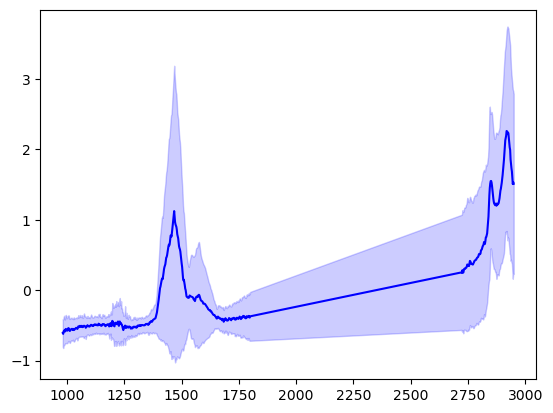

(3, 544)
Sodium Stearate


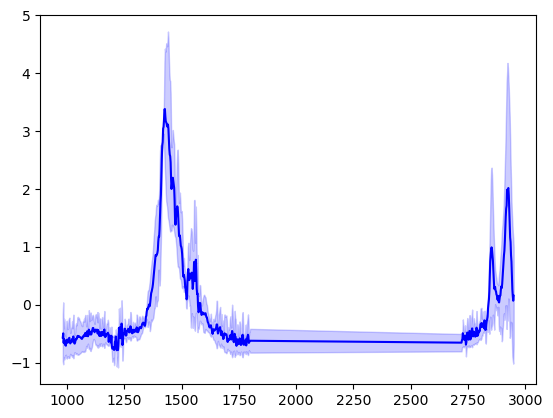

(131, 544)
Zinc Stearate


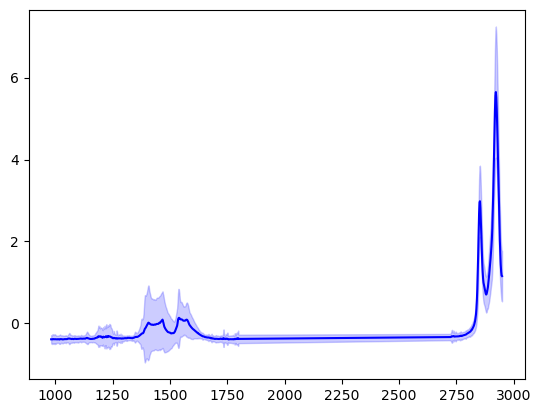

In [155]:
for label in np.unique(y_train_ir):
    df_PE = spectra_data_ir.query('background != "background" and polymer_stearates_ir == @label and hqi_stearates_ir > .7').loc[:,idx_gl+[False]*6]
    mean_PE = np.array(df_PE.mean(0))
    std_PE = np.array(df_PE.std(0))

    mean_PE = np.float64(mean_PE)
    std_PE = np.float64(std_PE)
    wn_gl = np.float64(wn_gl)
    print(df_PE.shape)
    print(label)

    _ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE, c='b')

    #_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE+std_PE)
    #_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE-std_PE)

    _ = plt.fill_between(wn_gl[idx_gl[:-4]], mean_PE - std_PE, mean_PE + std_PE, color='b', alpha=.2)
    _ = plt.show()


(239, 544)
Calcium Stearate


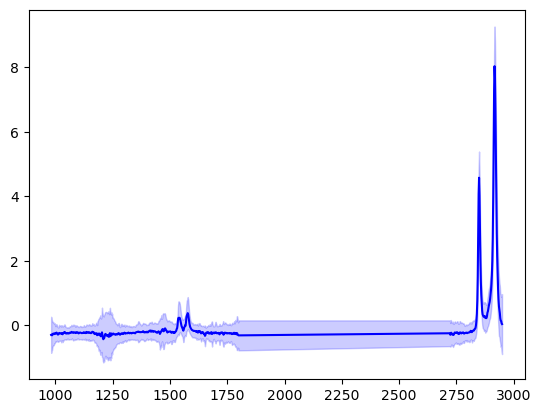

(3, 544)
Magnesium Stearate v2


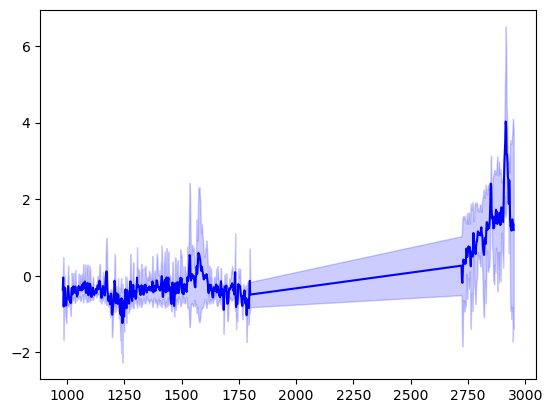

(0, 544)
Sodium Stearate


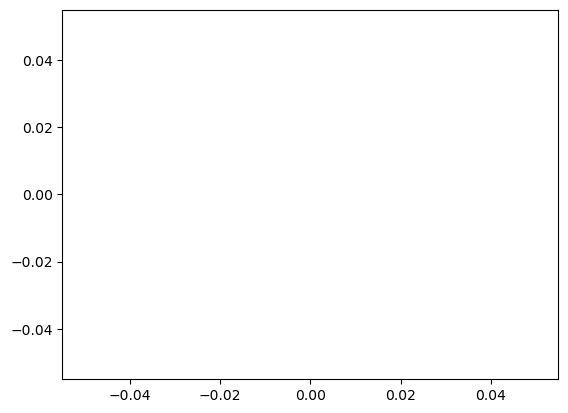

(12, 544)
Zinc Stearate


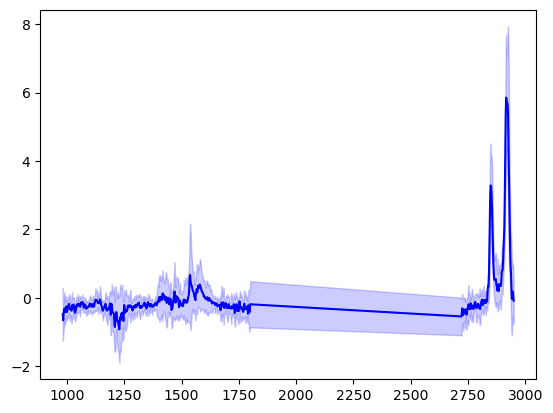

In [156]:
for label in np.unique(y_train_ir):
    df_PE = spectra_data_ir.query('background == "background" and polymer_stearates_ir == @label and hqi_stearates_ir > .7').loc[:,idx_gl+[False]*6]
    mean_PE = np.array(df_PE.mean(0))
    std_PE = np.array(df_PE.std(0))

    mean_PE = np.float64(mean_PE)
    std_PE = np.float64(std_PE)
    wn_gl = np.float64(wn_gl)
    print(df_PE.shape)
    print(label)

    _ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE, c='b')

    #_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE+std_PE)
    #_ = plt.plot(wn_gl[idx_gl[:-4]],mean_PE-std_PE)

    _ = plt.fill_between(wn_gl[idx_gl[:-4]], mean_PE - std_PE, mean_PE + std_PE, color='b', alpha=.2)
    _ = plt.show()


In [438]:
np.mean(pred_df_ir.query('hqi_stearates_ir>.7')['background'] == 'no_background')

1.0

In [439]:
pred_df_ir.query('hqi_stearates_ir>.7').shape[0] #/pred_df_ir.shape[0]

676

In [457]:
np.logical_and(np.array(pred_df_ir['hqi_stearates_ir'] >.7), np.array(pred_df['hqi_flopp'] >.7)).sum()

622

In [452]:

np.array(pred_df['hqi_flopp'] >.7)

array([False, False, False, ..., False,  True, False])

In [385]:
matches_mean_ir

,index,hqi_stearates_ir,background
polymer_stearates_ir,,,
Calcium Stearate,0.717456,0.717456,0.717456
Magnesium Stearate v2,0.075444,0.075444,0.075444
Sodium Stearate,0.004438,0.004438,0.004438
Zinc Stearate,0.202663,0.202663,0.202663


(array([ 22., 130., 246., 135.,  69.,  72.,  91., 108.,  77., 536.]),
 array([-0.14337519, -0.0292746 ,  0.08482599,  0.19892658,  0.31302717,
         0.42712776,  0.54122836,  0.65532895,  0.76942954,  0.88353013,
         0.99763072]),
 <BarContainer object of 10 artists>)

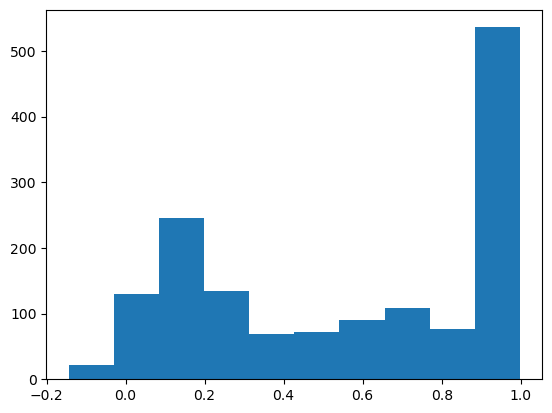

In [421]:
plt.hist(pred_df_ir['hqi_stearates_ir'])

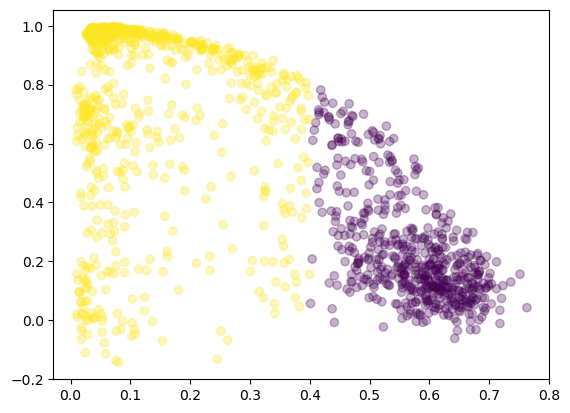

In [387]:
abs_var = np.abs(np.diff(x_test_ir,1)).mean(1) 
plt.scatter(abs_var, pred_hqi_ir, c=abs_var < .4, alpha=.3)

In [394]:
spectra_data_ir_particle = spectra_data_ir.loc[:,['map_x', 'map_y', 'id']].merge(particles_data, how='left', left_on='id',right_on='id_x')
spectra_data_ir_particle['hqi_stearates_ir'] = np.array(pred_df_ir['hqi_stearates_ir'])
spectra_data_ir_particle

,map_x,map_y,id,id_x,size,area,perimeter,circularity,hqi_stearates_ir
0,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01_0514_1,1.374926,1.330287,5.386343,0.575968,0.046158
1,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01_0514_2,3.169136,6.776416,11.286760,0.668194,0.180952
2,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01_0514_3,1.793934,2.482638,6.046356,0.853035,0.124855
3,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01_0514_4,0.936898,0.696918,3.310439,0.798824,0.214289
4,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01_0514_5,1.615575,2.111937,5.716350,0.811866,0.188688
...,...,...,...,...,...,...,...,...,...
1481,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02_0328_28,1.796098,2.247508,8.490387,0.391640,0.986738
1482,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02_0328_29,1.743342,2.414853,6.154179,0.800924,0.944355
1483,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02_0328_30,0.515590,0.211829,1.831388,0.793352,0.353427
1484,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02_0328_31,1.621519,2.048388,5.662438,0.802502,0.973973


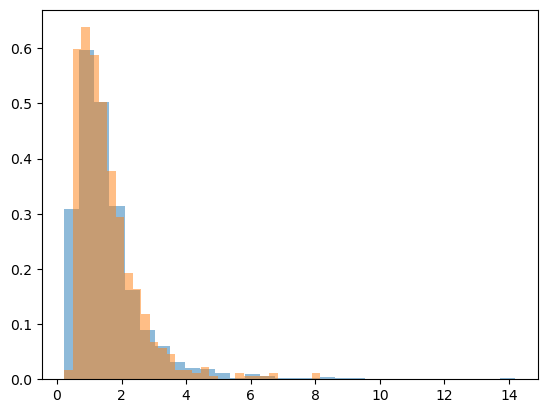

In [396]:
_ = plt.hist(spectra_data_ir_particle['size'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_stearates_ir > .7')['size'], bins=30, density=True, alpha=.5)

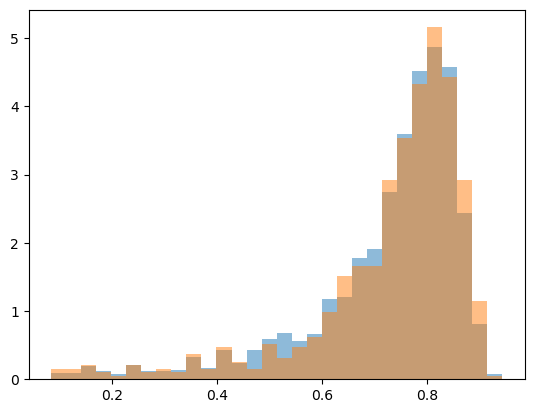

In [397]:
_ = plt.hist(spectra_data_ir_particle['circularity'], bins=30, density=True, alpha=.5)
_ = plt.hist(spectra_data_ir_particle.query('hqi_stearates_ir > .7')['circularity'], bins=30, density=True, alpha=.5)

# Stearate Raman

In [6]:
stearates_data_raman = pd.read_csv('gloves_contamination/stearates_preprocessed_raman.csv')
del stearates_data_raman['Unnamed: 0']
stearates_data_raman.columns = list(np.float64(stearates_data_raman.columns[:-3])) + list(stearates_data_raman.columns[-3:])
#stearates_data_ir['material'] = [x[:str.find(x, '_')] if x[(str.find(x, '_')-1):str.find(x, '_')] != '2' else x[:(str.find(x, '_')-3)] for x in stearates_data_ir['id']]
stearates_data_raman['material'] = [x[:str.find(x, '_')] for x in stearates_data_raman['id']]
stearates_data_raman

#stearates_data_ir.groupby('material').count().iloc[:,-1:]

material_list = ['Magnesium Stearate v2',
                 'Calcium Stearate',  
                 'Sodium Stearate',  
                 'Zinc Stearate']

material_sheets =['Mg (v2)', 'Ca', 'Na', 'Zn']

df_stearates_library_list = []

for mat, sheet in zip(material_list, material_sheets):
    df_stearates_library = pd.read_excel('gloves_contamination/MEC_04_010_StearateLibrary_Compilation.xlsx', sheet_name=sheet)
    df_stearates_library = df_stearates_library.iloc[:-2,[0,3]]#['Number']
    df_stearates_library['id'] = [mat+ '_' + str(x) for x in df_stearates_library['Number']]
    df_stearates_library = df_stearates_library.loc[:,['id', 'Raman']]
    df_stearates_library.columns = ['id', 'in_library']
    df_stearates_library_list.append(df_stearates_library)
    
df_stearates_library = pd.concat(df_stearates_library_list, axis=0)
df_stearates_library = df_stearates_library.query('in_library == 1').reset_index(drop=True)
stearates_data_raman = stearates_data_raman.merge(df_stearates_library)
stearates_data_raman

,355.5555419921875,357.72357177734375,359.8915710449219,362.0596008300781,364.2276306152344,366.3956604003906,368.56365966796875,370.731689453125,372.89971923828125,375.0677490234375,...,3887.262939453125,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x,map_y,id,material,in_library
0,-0.234462,-0.245992,-0.248062,-0.246671,-0.242597,-0.244773,-0.251859,-0.267206,-0.265747,-0.259754,...,-0.279306,-0.279306,-0.279306,-0.279306,-0.279306,11231.849609,214.850006,Magnesium Stearate v2_1,Magnesium Stearate v2,1.0
1,-0.230094,-0.229777,-0.234459,-0.238141,-0.241047,-0.237766,-0.237562,-0.243239,-0.239474,-0.232553,...,-0.247259,-0.247259,-0.247259,-0.247259,-0.247259,11348.250000,254.100006,Magnesium Stearate v2_5,Magnesium Stearate v2,1.0
2,-0.186715,-0.185408,-0.182980,-0.182002,-0.182148,-0.181463,-0.179386,-0.174903,-0.172555,-0.171166,...,-0.181858,-0.181858,-0.181858,-0.181858,-0.181858,11224.750000,293.850006,Magnesium Stearate v2_11,Magnesium Stearate v2,1.0
3,-0.197424,-0.224952,-0.215511,-0.199330,-0.177922,-0.186048,-0.213622,-0.273597,-0.285801,-0.281595,...,0.020341,0.020341,0.020341,0.020341,0.020341,11337.549805,295.600006,Magnesium Stearate v2_12,Magnesium Stearate v2,1.0
4,-0.244343,-0.249480,-0.250236,-0.249824,-0.248507,-0.249512,-0.250135,-0.249919,-0.246247,-0.243002,...,-0.239317,-0.239317,-0.239317,-0.239317,-0.239317,11226.500000,293.950012,Magnesium Stearate v2_13,Magnesium Stearate v2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176,-0.166295,-0.152782,-0.149671,-0.154362,-0.161236,-0.167185,-0.192812,-0.233620,-0.273249,-0.293440,...,-0.268813,-0.268813,-0.268813,-0.268813,-0.268813,10545.650391,-1468.500000,Zinc Stearate_106,Zinc Stearate,1.0
177,-0.333810,-0.332781,-0.330903,-0.328972,-0.327788,-0.330442,-0.334665,-0.340100,-0.333037,-0.328261,...,-0.131585,-0.131585,-0.131585,-0.131585,-0.131585,10437.250000,-1466.050049,Zinc Stearate_107,Zinc Stearate,1.0
178,-0.178851,-0.206740,-0.231102,-0.228828,-0.213190,-0.170986,-0.177441,-0.221436,-0.215089,-0.199092,...,-0.309094,-0.309094,-0.309094,-0.309094,-0.309094,10423.900391,-1464.800049,Zinc Stearate_108,Zinc Stearate,1.0
179,-0.098356,-0.115626,-0.125338,-0.143822,-0.169380,-0.217137,-0.205559,-0.148205,-0.126923,-0.112377,...,-0.361385,-0.361385,-0.361385,-0.361385,-0.361385,10464.000000,-1458.449951,Zinc Stearate_109,Zinc Stearate,1.0


In [7]:
stearates_data_raman.to_csv('gloves_contamination/stearates_preprocessed_raman_in_library.csv')

In [408]:
wn_st_r = np.array(stearates_data_raman.columns[:-5])

idx_st_r = list(np.logical_and(wn_st_r > 355, wn_st_r < 3500)) + [False]*5

x_train_raman = stearates_data_raman.iloc[:,idx_st_r].to_numpy()
x_train_raman = norm_spect_pivot(x_train_raman, norm_type='SNV') #MINMAX
#x_train_ir = -x_train_ir
x_train_raman_diff = np.diff(x_train_raman)
x_train_raman_diff = norm_spect_pivot(x_train_raman_diff, norm_type='SNV')
y_train_raman = stearates_data_raman.iloc[:,-2]


Calcium Stearate


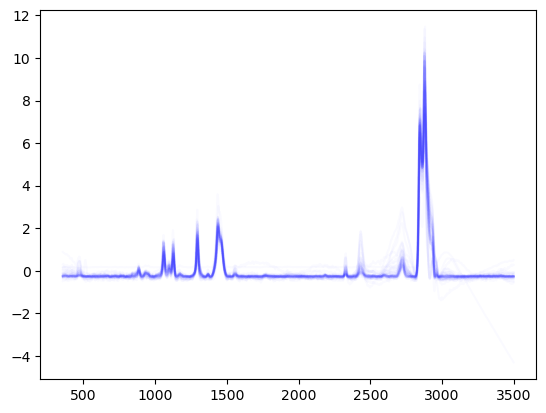

Magnesium Stearate v2


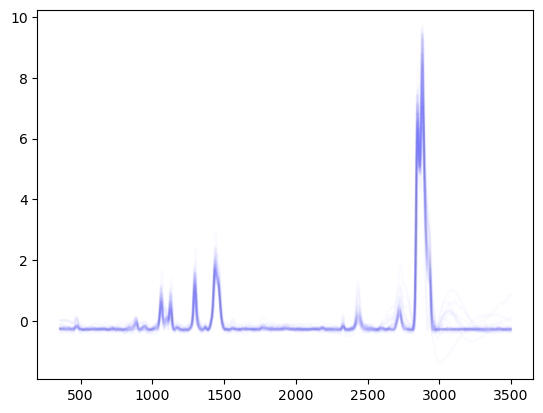

Sodium Stearate


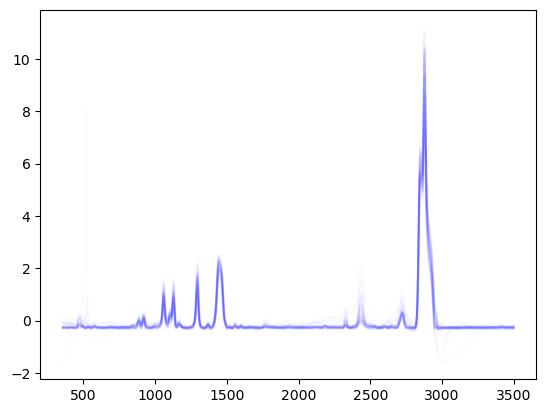

Zinc Stearate


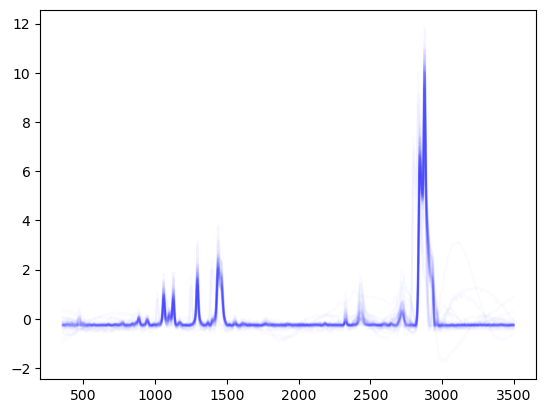

In [418]:
for label in np.unique(y_train_raman):
    print(label)
    _ = plt.plot(wn_st_r[idx_st_r[:-5]],
             x_train_raman[y_train_raman == label,:].T, c='b', alpha=.02)
    _ = plt.show()

In [411]:
pred_raman = corr_matching(x_train_raman, y_train_raman, 
                      x_test_raman, r_min=0)
pred_polymers_raman = pred_raman[0]
pred_hqi_raman = pred_raman[1]
pred_df_raman = pd.DataFrame(pred_polymers_raman)
pred_df_raman.columns = ['polymer_stearates_raman']
pred_df_raman['hqi_stearates_raman'] = pred_hqi_raman
pred_df_raman = pred_df_raman.reset_index(drop=True) 

#pred_df_raman['background'] = spectra_data_raman['background']

matches_mean_raman = pred_df_raman.reset_index().query('hqi_stearates_raman>.7').groupby('polymer_stearates_raman').count()#['hqi_stearates_ir']
matches_mean_raman = matches_mean_raman / matches_mean_raman.sum()
matches_mean_raman

#pred_df_ir.reset_index().query('hqi_stearates_ir>.7').groupby('polymer_stearates_ir').count()


,index,hqi_stearates_raman
polymer_stearates_raman,,
Calcium Stearate,0.211462,0.211462
Magnesium Stearate v2,0.065217,0.065217
Sodium Stearate,0.355731,0.355731
Zinc Stearate,0.367589,0.367589


In [460]:
pred_df_raman.query('hqi_stearates_raman > .7')

,polymer_stearates_raman,hqi_stearates_raman
206,Sodium Stearate,0.717031
207,Sodium Stearate,0.739399
208,Sodium Stearate,0.701719
210,Sodium Stearate,0.827788
216,Calcium Stearate,0.798356
...,...,...
1479,Zinc Stearate,0.975964
1480,Calcium Stearate,0.714930
1481,Calcium Stearate,0.928504
1482,Sodium Stearate,0.796237


(array([  9.,  53., 104., 325., 246., 133., 113., 107., 150., 240.]),
 array([0.05412439, 0.14747227, 0.24082014, 0.33416802, 0.4275159 ,
        0.52086378, 0.61421166, 0.70755954, 0.80090742, 0.8942553 ,
        0.98760318]),
 <BarContainer object of 10 artists>)

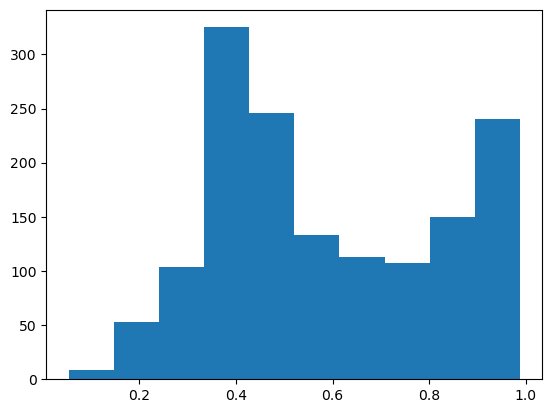

In [420]:
plt.hist(pred_df_raman['hqi_stearates_raman'])

In [415]:
np.mean(pred_df_raman['hqi_stearates_raman'] > .7)

0.3405114401076716

# Background

In [101]:
background_data_ir = pd.read_csv('gloves_contamination/data_ir_background_gloves.csv')
del background_data_ir['Unnamed: 0']
background_data_ir = background_data_ir.iloc[:,:-2]
background_data_ir.columns = np.float64(background_data_ir.columns)
background_data_ir.insert(0, "data_source", '')
background_data_ir.insert(0, "polymer", 'bg')
background_data_ir.insert(0, "id", 1)


In [110]:
pred_total_df_bg

,polymer_background,hqi_background,background_total
0,bg,1.000000,background
1,bg,1.000000,background
2,bg,1.000000,no_background
3,bg,1.000000,no_background
4,bg,1.000000,no_background
...,...,...,...
1481,bg,0.571144,no_background
1482,bg,0.589299,no_background
1483,bg,0.490863,no_background
1484,bg,0.582360,no_background


In [111]:
pred_total_df_bg = matching(background_data_ir, spectra_data_ir_total, limits=((980,1800),(2720, 2950)), lib_name='background', data_name='total')
(np.mean(pred_total_df_bg.query('background_total == "background"')['hqi_background'] > .7),
np.mean(pred_total_df_bg.query('background_total == "no_background"')['hqi_background'] > .7))


(0.2676056338028169, 0.11943462897526502)

In [105]:
mean_hqi_total_bg = pd.concat([#pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_bg.groupby(['polymer_background', 'background_total']).count(),
                               pred_total_df_bg.groupby(['polymer_background', 'background_total']).mean(),
                               pred_total_df_bg.groupby(['polymer_background', 'background_total']).std()],axis=1)
#mean_hqi_total_st.columns = ['n','mean_hqi', 'std_hqi']
#mean_hqi_total_st['excl_rule'] = 'total_var'
#mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_min_stearates.csv')
mean_hqi_total_bg


hqi_background  hqi_background  \
polymer_background background_total                                   
bg                 background                    71        0.425505   
                   no_background               1415        0.536885   

                                     hqi_background  
polymer_background background_total                  
bg                 background              0.352683  
                   no_background           0.192040

In [177]:
mean_hqi_total_bg = pd.concat([#pred_total_df_st.groupby('background_total_var').count()['polymer_stearates_ir'],
                               pred_total_df_bg.count(),
                               pred_total_df_bg.mean(),
                               pred_total_df_bg.std()],axis=1)
#mean_hqi_total_st.columns = ['n','mean_hqi', 'std_hqi']
#mean_hqi_total_st['excl_rule'] = 'total_var'
#mean_hqi_total_st.to_csv('gloves_contamination/mean_std_hqi_min_stearates.csv')
mean_hqi_total_bg


,0,1,2
polymer_background,1486,NaN,NaN
hqi_background,1486,0.531564,0.203824
background_total,1486,NaN,NaN


# Background against Flopp

In [124]:
background_data_ir = pd.read_csv('gloves_contamination/data_ir_background_gloves.csv')
del background_data_ir['Unnamed: 0']
background_data_ir.columns = list(np.float64(background_data_ir.columns[:-2])) + list(background_data_ir.columns[-2:])
background_data_ir['background'] = 'background'
background_data_ir['id'] = 1
background_data_ir

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2939.6376953125,2941.56689453125,2943.495849609375,2945.4248046875,2947.353759765625,2949.28271484375,map_x,map_y,background,id
0,1.064093,-0.709076,0.148053,-1.478656,-1.931184,-1.414527,-0.648624,0.394164,0.786798,0.429629,...,2.616702,1.884557,-1.023943,0.145100,1.055595,1.230860,0,0,background,1
1,0.225281,0.599344,-1.026284,-1.322264,-1.706205,-1.234870,-0.786177,-0.083469,0.360934,-0.075452,...,0.075446,2.104574,0.459390,2.036867,2.209021,3.501965,0,0,background,1
2,2.140653,1.106025,0.698607,0.334014,1.479439,1.331816,1.045905,0.471054,0.601645,0.421140,...,2.596484,1.098548,0.038893,1.344325,3.496606,4.225934,0,0,background,1
3,-1.811077,-1.197157,0.179185,-0.360507,-0.540565,-1.030370,-0.923846,-1.172802,-1.472101,-1.080226,...,-0.510963,-0.142746,-2.215900,-2.171097,-1.679763,-3.660455,0,0,background,1
4,1.005833,0.099599,-0.733488,-1.044153,-0.133176,-0.975554,-2.332681,-2.195930,-0.771425,-0.184024,...,-3.689393,-2.641657,-3.630348,-1.840201,-1.516295,-4.295624,0,0,background,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,-0.224219,0.049475,-0.811554,-0.433064,-1.355675,-1.774116,-0.674873,-0.966245,-0.914912,0.088596,...,-0.818144,-4.415222,-4.366511,-2.199884,1.045862,2.266011,0,0,background,1
136,1.207168,-0.468039,-2.549086,-1.683398,-1.435072,-1.006440,-0.301754,0.062249,1.783502,1.816475,...,2.781947,-0.682063,-1.409779,3.305688,4.938367,0.284720,0,0,background,1
137,0.994650,0.461290,1.156144,-0.127088,-1.053293,-0.953797,0.236237,0.548628,1.358646,2.036568,...,3.262985,4.878158,4.162152,3.761976,1.865993,2.138661,0,0,background,1
138,-1.256608,-1.809763,-0.249189,0.387998,0.593958,0.329358,1.097471,2.453407,2.170890,1.201292,...,0.738508,-0.387999,-2.731985,-2.314536,-1.496785,3.112458,0,0,background,1


In [144]:
#pred_fp_df = matching(flopp_flopp_e_pivot_new, spectra_data_ir_fp, limits=((980,1800),(2720, 2950)), lib_name='flopp', data_name='finger_print')
#pred_mean_int_df = matching(flopp_flopp_e_pivot_new, spectra_data_ir_mean, limits=((980,1800),(2720, 2950)), lib_name='flopp', data_name='mean_int')
pred_total_df, pred_ = matching(flopp_flopp_e_pivot_new, background_data_ir, limits=((980,1800),(2720, 2950)), lib_name='flopp', data_name='total_var')


In [149]:
pd.DataFrame(pred_[0]).iloc[np.where(pred_total_df['hqi_flopp'] > .7)[0],:]

,polymer
175,Rubber
181,Rubber


In [145]:
pred_total_df.iloc[np.where(pred_total_df['hqi_flopp'] > .7)[0],:]

,polymer_flopp,hqi_flopp,background_total_var
83,Rubber,0.711188,background
106,Rubber,0.859723,background


In [128]:
np.sum(pred_total_df['hqi_flopp'] > .7)

2

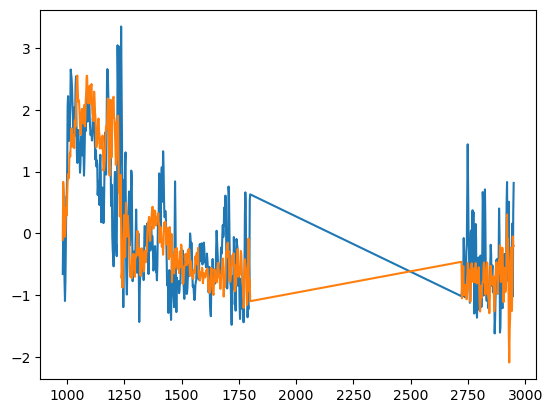

In [155]:
plt.plot(background_data_ir.iloc[np.where(pred_total_df['hqi_flopp'] > .7)[0],:-4].T)

#plt.plot(flopp_flopp_e_pivot_new.iloc[[175, 181],3:].T)

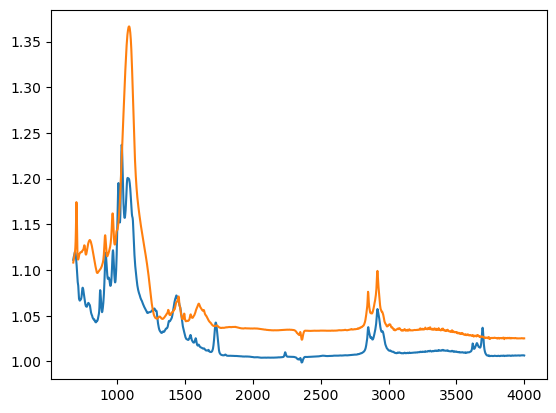

In [156]:
plt.plot(flopp_flopp_e_pivot_new.iloc[[175, 181],3:].T)

In [ ]:
plt.plot()